# Chapter 3 figures

Change the paths, dataset prefixes and settings below to regenerate the chapter.
Each call displays its figure here and saves it to dphil-analysis/figures/ch3.
The maintained thesis workflow is independent of this notebook. The tree illustration displays a PDF;
SVG source stays in memory for notebook display without creating SVG files.
Simulation figures use the updated 20 Mb aggregate in data/ch3, with
separate focal-site caches in data/ch3/current. The multiple-demography
comparison uses this Out-of-Africa aggregate and updated new-branch
aggregates for the other three models.
The plotting module is self-contained and does not import `tsinfer-paper`.
Run scripts/extract_zarr_validation_data.py on the machine holding the variant Zarr stores.
Transfer PREFIX_zarr_data.csv alongside the aggregate CSV; the main plots
need no Zarrs locally. Per-focal-site tables are written to data_folder.
The phase-switch illustration uses PREFIX_phase_runs.csv from the same simulation.
The empirical DAF comparison uses the local TGP chromosome 20 Zarr.

To tweak a plot, edit its keyword arguments and rerun that cell. The imports
cell enables `%autoreload 2`, so saved changes to the plotting modules also
take effect without restarting the kernel or reloading the data. In an
already-running notebook, rerun the imports cell once to enable autoreload.

In [167]:
import dataclasses
import pathlib

import IPython.display as ipd
import numpy as np
import pandas as pd
import polars as pl
import tskit

from ch3 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


<module 'ch3_ancestor_extension' from '/Users/duncan/work/dphil-analysis/src/ch3_ancestor_extension.py'>

## Ancestor extension: toy example

Six samples and eight sites show both shared pruning and the shorter 0.5
ancestor. The focal site has carriers {a,b,c,d}; site 2's doubleton {a,d}
lies within that set. Sites 3–4 are older (five derived carriers) and remove b
in both versions. Sites 5–6's doubletons {c,f} cross the sample-set boundary
and remove c only in 0.5. Derived allele counts supply site times.
The generator replays 0.4.1 and the corrected 0.5.x backport, including
assignment of 0 at younger sites regardless of the current consensus.
The replay follows `AncestorBuilder.make_ancestor` from tag 0.4.1 and the
[0.5.x backport](https://github.com/Duncan-JR/tsinfer/tree/0.5.x)
(commit `d694eea`). Both removal and flag updates use the same gate.

Site 2 cannot mark samples for removal because both carriers are within S.
Red conflicts mark and remove b at sites 3 and 4. Orange conflicts mark and
remove c at sites 5 and 6. After b leaves, S={a,c,d}; f is a derived carrier
outside S, making the c/f doubletons informative despite their younger ages.
Removing c halves the original four-sample set, so 0.5 stops after site 6.
The 0.4 ancestor continues through site 8, two sites longer in this window;
its arrow indicates that its stopping criterion has still not been reached.
Younger sites are assigned 0 in both ancestors regardless of their consensus.
Both toy figures are also included in Chapter 3 of the thesis.

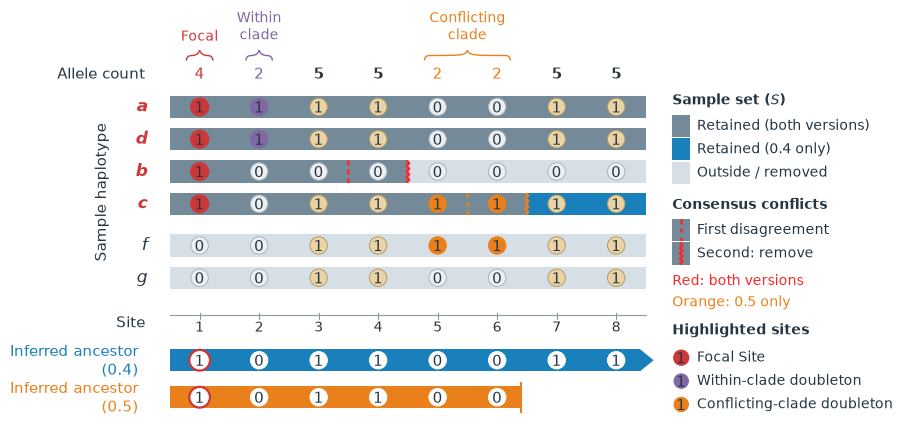

In [168]:
# Columns are one-indexed sites 1–8; site 1 is focal.
# a
# d
# b
# c
# f
# g
figure_folder = (repository_dir / "figures/ch3").expanduser()
figure_folder.mkdir(parents=True, exist_ok=True)
extension_config = nb_utils.ExtensionConfig(
    genotypes=(
        (1, 1, 1, 1, 0, 0, 1, 1),
        (1, 1, 1, 1, 0, 0, 1, 1),
        (1, 0, 0, 0, 0, 0, 0, 0),
        (1, 0, 1, 1, 1, 1, 1, 1),
        (0, 0, 1, 1, 1, 1, 1, 1),
        (0, 0, 1, 1, 0, 0, 1, 1),
    ),
    samples=("a", "d", "b", "c", "f", "g"),
    focal_site=1,
)
nb_plot.plot_ancestor_extension(
    extension_config,
    figure_folder=figure_folder,
    allele_fontsize=10.8,
    allele_text_offset=0.038,
    bar_height=0.52,
    circle_radius=0.205,
    conflict_color="#ff2626",
    conflict_line_width=1.8,
    contained_color="#8167a6",
    dpi=400,
    figsize=(9.0, 4.9),
    first_conflict_dashes=3,
    focal_color="#cc3838",
    focal_ring_width=0.065,
    ink_color="#253642",
    label_fontsize=11,
    legend_fontsize=10,
    legend_width=6.3,
    neutral_allele_color="#d7dce0",
    older_allele_color="#ead4a5",
    outside_color="#d6dfe5",
    outside_gap=0.22,
    row_spacing=0.76,
    sample_color="#748a98",
    site_spacing=1.4,
    version_colors=("#1a80bb", "#ea801c"),
)

## Genealogical justification for ancestor extension

Three trees reproduce **all 48 genotypes** above. At sites 1–2, E's doubleton
{a,d} is nested within F's focal clade {a,b,c,d}. At sites 3–4, b has left F,
while the two older mutations each cover everyone except b: both algorithms
detect b's repeated disagreement. At sites 5–8, c joins f under G. The {c,f}
doubletons at sites 5–6 overlap S={a,c,d} without being nested within it;
they supply the extra evidence used by 0.5. The older mutations at sites 7–8
are included in 0.4's longer ancestor. Every mutation occurs once, so the
conflicting clades require recombination; the genotypes do not identify a
unique recombination history.

Red branches and bold red sample labels identify F's descendants in the first
two trees and the surviving a/d clade in the last tree; orange
branches connect G to c and f in the final tree. E remains purple to match
its doubleton in the matrix, while its descendant branches are red because
they lie within F. Circled labels identify the ancestors. Crosses mark 0→1
mutations and are labelled by site. Ages are illustrative on a shared linear
scale, rather than the derived allele counts used as inference site times.
Sites have irregular illustrative positions across 100 bp; mutation and arrow
labels retain the site numbers 1–8 used in the genotype matrix.
F disappears at the second breakpoint (47 bp), where retaining it above E
would create a unary node. E and G remain distinct coalescent ancestors.
The unlabelled multifurcations are unresolved branches: a binary refinement
permits b's departure at the first breakpoint and c joining f at the second,
with no change to the labelled mutation nodes or any observed genotypes.
This matches the non-unary reference representation used for ancestor
evaluation: E, F and G are the mutation nodes for sites 2, 1 and 5–6,
respectively, rather than persistent names for descendant sample sets.

Using the evaluator's decoding convention, F's true haplotype is `1011----`:
it is defined at sites 1–4 and missing thereafter. The inferred haplotypes
are `10110011` (0.4) and `101100--` (0.5). Both recover the four known alleles
exactly; 0.5 overshoots by two sites instead of four. Thus this example shows
reduced span inflation, not improved allelic accuracy or an exact boundary.
The true tree breakpoint (47 bp) and boundaries inferred from site coordinates
are different quantities; the evaluator uses the next shared site as the
right boundary of a contiguous stretch of known genotypes.

Construction follows tskit's [tables and editing tutorial](https://tskit.dev/tutorials/tables_and_editing.html),
and SVG styling follows its [visualization tutorial](https://tskit.dev/tutorials/viz.html).
This plot is also included in Chapter 3 of the thesis.

In [169]:
# Site number, branch's child node, and mutation age. Positions are separate.
extension_tree_config = {
    "site_positions": (6, 17, 31, 39, 58, 65, 81, 96),
    "topologies": (
        {"A": ("F", "f", "g"), "F": ("E", "b", "c"), "E": ("a", "d")},
        {"R": ("A", "b"), "A": ("F", "f", "g"), "F": ("E", "c"), "E": ("a", "d")},
        {"R": ("A", "b"), "A": ("E", "G", "g"), "E": ("a", "d"), "G": ("c", "f")},
    ),
    "sequence_length": 100,
    "mutations": (
        (1, "F", 5.3),
        (2, "E", 3.1),
        (3, "A", 7.2),
        (4, "A", 8.6),
        (5, "G", 3.2),
        (6, "G", 4.5),
        (7, "A", 7.2),
        (8, "A", 8.6),
    ),
    "node_ages": {"E": 2, "F": 4, "G": 2, "A": 6, "R": 10},
    "intervals": ((0, 24), (24, 47), (47, 100)),
}

In [170]:
# Build the nodes, edges, sites and mutations directly, without simulation.
# Verify compatibility with the existing haplotype illustration, including all
# background mutations, rather than just the highlighted doubletons.
# Both mark b at site 3.
# Both remove b at site 4.
# Only 0.5 marks c at site 5.
# Match get_true_ancestor's single-mutation rule, and check that these mutation
# nodes are coalescences rather than unary waypoints or sample-set labels.
# process_ancestor_chunk marks all nodes as samples before decoding, so an
# ancestor absent from a tree is isolated and therefore missing at that site.
extension_tables = tskit.TableCollection(extension_tree_config["sequence_length"])
extension_tables.time_units = "uncalibrated"
extension_node_ids = {}
for name in extension_config.samples:
    extension_node_ids[name] = extension_tables.nodes.add_row(
        flags=tskit.NODE_IS_SAMPLE, time=0
    )
for name, age in extension_tree_config["node_ages"].items():
    extension_node_ids[name] = extension_tables.nodes.add_row(time=age)
for interval, topology in zip(
    extension_tree_config["intervals"], extension_tree_config["topologies"]
):
    left, right = interval
    for parent, children in topology.items():
        for child in children:
            extension_tables.edges.add_row(
                left=left,
                right=right,
                parent=extension_node_ids[parent],
                child=extension_node_ids[child],
            )
for site_number, node_name, age in extension_tree_config["mutations"]:
    position = extension_tree_config["site_positions"][site_number - 1]
    site_id = extension_tables.sites.add_row(position=position, ancestral_state="0")
    extension_tables.mutations.add_row(
        site=site_id, node=extension_node_ids[node_name], derived_state="1", time=age
    )
extension_tables.sort()
extension_ts = extension_tables.tree_sequence()
expected_extension_genotypes = np.asarray(extension_config.genotypes)
np.testing.assert_array_equal(
    extension_ts.genotype_matrix().T, expected_extension_genotypes
)
np.testing.assert_array_equal(
    extension_ts.sites_position, extension_tree_config["site_positions"]
)
assert extension_ts.num_trees == len(extension_tree_config["intervals"])
old_extension = nb_utils.trace_ancestor(extension_config, extension_config.versions[0])
new_extension = nb_utils.trace_ancestor(extension_config, extension_config.versions[1])
extension_b = extension_config.samples.index("b")
extension_c = extension_config.samples.index("c")
assert old_extension.marks[extension_b] == [2]
assert new_extension.marks[extension_b] == [2]
assert old_extension.removals == {extension_b: 3}
assert new_extension.marks[extension_c] == [4]
assert new_extension.removals == {extension_b: 3, extension_c: 5}
assert old_extension.end == 8
assert new_extension.end == 6
assert old_extension.end - new_extension.end == 2
for variant in extension_ts.variants():
    tree = extension_ts.at(variant.site.position)
    carriers = variant.samples[variant.genotypes == 1]
    true_node = variant.site.mutations[0].node
    assert true_node == tree.mrca(*carriers)
    assert tree.num_children(true_node) >= 2
for tree in extension_ts.trees():
    assert all((tree.num_children(node) != 1 for node in tree.nodes()))
assert extension_node_ids["F"] not in set(extension_ts.last().nodes())
extension_truth_tables = extension_ts.dump_tables()
extension_truth_tables.nodes.flags = np.full(
    extension_ts.num_nodes, tskit.NODE_IS_SAMPLE, dtype=np.uint32
)
extension_truth_ts = extension_truth_tables.tree_sequence()
extension_true_haplotype = extension_truth_ts.genotype_matrix(
    samples=[extension_node_ids["F"]], isolated_as_missing=True
)[:, 0]
np.testing.assert_array_equal(extension_true_haplotype, [1, 0, 1, 1, -1, -1, -1, -1])
extension_true_sites = np.flatnonzero(extension_true_haplotype != tskit.MISSING_DATA)
np.testing.assert_array_equal(
    old_extension.haplotype[extension_true_sites],
    extension_true_haplotype[extension_true_sites],
)
np.testing.assert_array_equal(
    new_extension.haplotype[extension_true_sites],
    extension_true_haplotype[extension_true_sites],
)
assert old_extension.end - (extension_true_sites[-1] + 1) == 4
assert new_extension.end - (extension_true_sites[-1] + 1) == 2

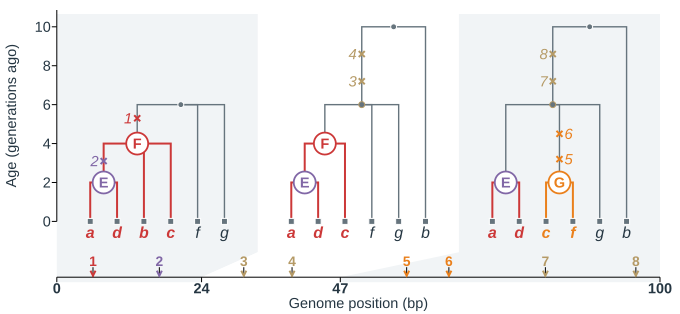

In [171]:
# Scope every selector so this SVG cannot recolour other notebook figures.
# Centre the labels on their node symbols using SVG attributes so the white
# circles also render correctly in SVG viewers without CSS transform support.
# Move the axis and its connecting background together, preserving the trees'
# alignment with the age scale while increasing the gap below the sample labels.
# Add the site numbers above tskit's site arrows.
# PDF conversion uses rsvg-convert from librsvg.
extension_tree_svg = nb_plot.plot_extension_tree(
    extension_ts,
    extension_node_ids,
    extension_config,
    figure_folder=figure_folder,
    svg_id="ancestor_extension_trees",
    ink_color="#253642",
    muted_color="#66747d",
    background_color="#f1f4f6",
    font_size=14.5,
    sample_font_size=15.8,
    mutation_font_size=14.8,
    site_font_size=13.8,
    node_colors={"F": "#cc3838", "E": "#8167a6", "G": ("#1a80bb", "#ea801c")[1]},
    label_radius=11,
    descendant_colors={"F": "#cc3838", "E": "#cc3838", "G": ("#1a80bb", "#ea801c")[1]},
    older_color="#b59a66",
    size=(680, 300),
    axis_gap=14,
    plot_interval=(0, 100),
    y_ticks=(0, 2, 4, 6, 8, 10),
    symbol_size=6,
    canvas_color="white",
    site_label_offset=-16,
)

In [172]:
# Prefixes include the simulation region, sample size and seed, but not replicate
# or error-profile suffixes. All available replicates are pooled.
# Default opacity for all jitter points (alpha can override).
# Use available CPU cores for focal-site preprocessing.
# Rebuild automatically when the updated simulation or truth changes.
# Read the current phase settings from the aggregate, not the older Zarr summary.
data_folder = (repository_dir / "data/ch3").expanduser()
aggregated_folder = pathlib.Path(
    "~/work/tsinfer-anc-eval/data/anc_eval/dataframes"
).expanduser()
data_prefix = "OutOfAfrica_3G09-chr20-L0-R2e7-n6000-s1"
aggregated_path = data_folder / f"{data_prefix}-aggregated.csv"
focal_data_folder = data_folder / "current"
focal_data_folder.mkdir(exist_ok=True)
zarr_data_path = data_folder / f"{data_prefix}_zarr_data.csv"
phase_runs_path = data_folder / f"{data_prefix}_phase_runs.csv"
tgp_zarr_path = (
    repository_dir / "data/general/zarr_vcfs/tgp/chr20/data.zarr"
).expanduser()
config = nb_utils.AnalysisConfig(
    genotype_multipliers=(1, 2, 5, 10, 100),
    mispol_rates=(0, 0.01, 0.05, 0.1),
    tgp_region_start=0,
    tgp_region_end=20000000,
    workers=None,
)
rebuild_focal_tables = False
focal_paths = nb_utils.FocalPaths(
    focal_data_folder / f"{data_prefix}_focal_overshoots.csv",
    focal_data_folder / f"{data_prefix}_focal_spans.csv",
)
cached_truth_path = focal_data_folder / zarr_data_path.name
if not cached_truth_path.exists():
    cached_truth_path.symlink_to(zarr_data_path)
focal_cache_paths = (focal_paths.overshoots, focal_paths.spans)
focal_inputs_mtime = max(
    aggregated_path.stat().st_mtime, zarr_data_path.stat().st_mtime
)
focal_cache_current = all(
    (
        path.exists() and path.stat().st_mtime >= focal_inputs_mtime
        for path in focal_cache_paths
    )
)
if rebuild_focal_tables or not focal_cache_current:
    processed_paths = nb_utils.preprocess_data(
        aggregated_path, zarr_data_path, focal_data_folder, config
    )
data = nb_utils.load_data(focal_data_folder, data_prefix, config)
config.phase_spacings = data.phase_spacings

## Error-free results

The span and overshoot boxplots use the custom DAF cutoffs supplied below.
Without cutoffs, five rounded quantile bins cover the full frequency range.
Boxes show quartiles, medians and 1.5 IQR whiskers; outliers are hidden.
All boxplots enable y_log=False. Spans use a standard log axis; signed
overshoots use a symmetric log axis, linear between -1 kb and +1 kb.
Zero values remain visible and the outer ticks mark powers of ten in Mb.
Each focal site contributes its own true/inferred span comparison and one
overshoot per side. Sites remain separate when they share a true or inferred
ancestor, including when their polarisation states differ. Counts below the
boxes show focal sites per bin. Bins use each focal allele's observed frequency.
Jitter points between -1 and +1 Mb are sampled uniformly (up to 1,500 per
group); all points outside are shown. Boxes and quantile caps use every observation.

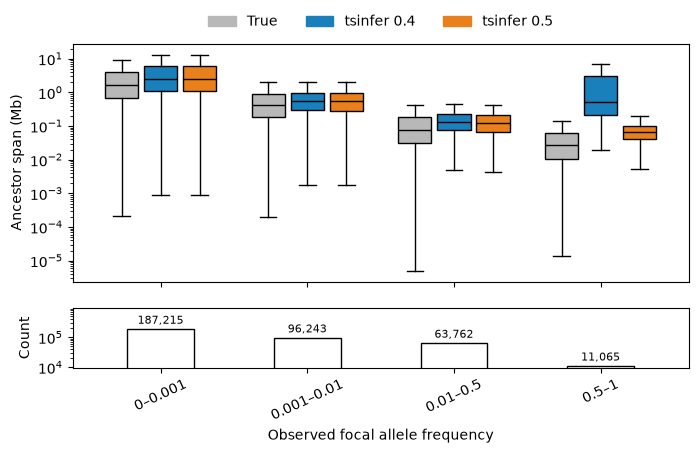

In [173]:
# Focal-site counts use a logarithmic scale, with exact counts above each bar.
nb_plot.plot_ancestor_spans(
    data,
    figure_folder=figure_folder,
    cutoffs=[0, 0.001, 0.01, 0.5, 1],
    figsize=(7, 4.5),
    y_log=True,
    ancestor_count_fontsize=8,
    ancestor_count_margin=0.35,
    ancestor_count_padding=2,
    ancestor_panel_spacing=0.18,
    box_size=(7, 4.5),
    dpi=300,
    jitter_alpha=0.15,
    jitter_max_points=1500,
    jitter_sample_interval_mb=(-1, 1),
    jitter_seed=42,
    jitter_size=5,
    jitter_width=0.32,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    overshoot_linthresh_bp=1000,
    quantile_line_style="--",
    quantile_line_width=1.2,
    quantile_secondary_color="#555555",
    quantile_secondary_line_style="-.",
    true_color="#b8b8b8",
    version_colors=("#1a80bb", "#ea801c"),
)

### Mean ancestor span by focal allele frequency

Use the same 20 equal-width DAF bins as the error-direction curve, including
DAF 1 in the final bin. Calculate arithmetic means at bin midpoints, with
each focal site counted separately even when sites share an ancestor.
Simulation curves use only the error-free profile; truth is counted once.
Separate plots use solid curves with the same version colours; simulation
truth is dark red. Both mean-span panels share logarithmic y-axis limits.
Each plot has a short focal-site count panel below it; counts are checked
to match between versions within each dataset. Both are exported to the thesis.

The corrected 1KGP spans run between the first and last included inference
sites, without using sequence_length. The title reports the first-to-last
inference-site extent from the CSV (26.0 Mb), rather than the nominal
28.1 Mb chr20p mask. The exact positions and width are displayed below.
No spans are clipped or rescaled. Its `inferred_time` values are the benchmark's
default focal-frequency proxies, rather than ages in generations (see the
[tsinfer documentation](https://tskit.dev/tsinfer/docs/stable/api.html#tsinfer.VariantData)).

In [174]:
# The replacement export contains only 0.5; retain the corrected 0.4 baseline.
tgp_ancestor_spans_path = data_folder / "tgp_ancestor_spans.csv"
tgp_original_spans = pd.read_csv(data_folder / "tgp_ancestor_spans_0.4.1.csv")
tgp_alternative_spans = pd.read_csv(tgp_ancestor_spans_path)
assert tgp_original_spans.version.eq(config.versions[0]).all()
assert tgp_alternative_spans.version.eq(config.versions[1]).all()
tgp_combined_spans = pd.concat(
    [tgp_original_spans, tgp_alternative_spans], ignore_index=True
)
tgp_combined_spans_path = data_folder / "tgp_ancestor_spans_alt.csv"
tgp_combined_spans.to_csv(tgp_combined_spans_path, index=False)
tgp_ancestor_spans = nb_utils.load_tgp_ancestor_spans(tgp_combined_spans_path)
ancestor_span_curve_summary = nb_utils.summarise_ancestor_span_curves(
    data, tgp_ancestor_spans, ancestor_error_bins=20
)
tgp_inference_site_extent = tgp_ancestor_spans.groupby("version").focal_position.agg(
    first_site_bp="min", last_site_bp="max"
)
tgp_inference_site_extent["width_bp"] = (
    tgp_inference_site_extent.last_site_bp - tgp_inference_site_extent.first_site_bp
)
tgp_inference_site_extent["width_mb"] = (
    tgp_inference_site_extent.width_bp / config.bp_per_mb
)
assert tgp_inference_site_extent.width_bp.nunique() == 1
tgp_inference_width_mb = tgp_inference_site_extent.width_mb.iloc[0]
for version, extent in tgp_inference_site_extent.iterrows():
    version_spans = tgp_ancestor_spans.loc[
        tgp_ancestor_spans.version == version, "inferred_span"
    ]
    assert version_spans.between(0, extent.width_bp).all()
ipd.display(
    tgp_inference_site_extent.style.format(
        {
            "first_site_bp": "{:,.0f}",
            "last_site_bp": "{:,.0f}",
            "width_bp": "{:,.0f}",
            "width_mb": "{:.6f}",
        }
    ).set_caption(
        "1KGP title width: (last inference-site position - first position) / 1,000,000"
    )
)

,first_site_bp,last_site_bp,width_bp,width_mb
version,,,,
0.4.1,"227,217","26,223,820","25,996,603",25.996603
0.5.1,"227,217","26,223,820","25,996,603",25.996603


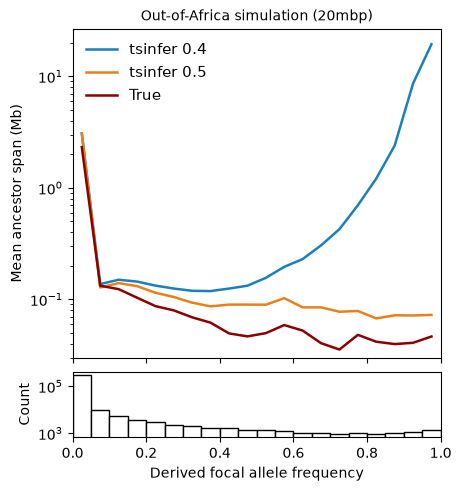

In [175]:
nb_plot.plot_ancestor_span_curves(
    ancestor_span_curve_summary,
    "Simulation",
    config=config,
    title="Out-of-Africa simulation (20mbp)",
    figure_folder=figure_folder,
    y_log=True,
    dpi=300,
    span_curve_height_ratios=(3, 0.6),
    span_curve_legend_fontsize=11,
    span_curve_limit_factor=1.2,
    span_curve_line_width=1.8,
    span_curve_size=(4.5, 4.8),
    span_curve_title_fontsize=10,
    span_curve_true_color="#8b0000",
    version_colors=("#1a80bb", "#ea801c"),
)

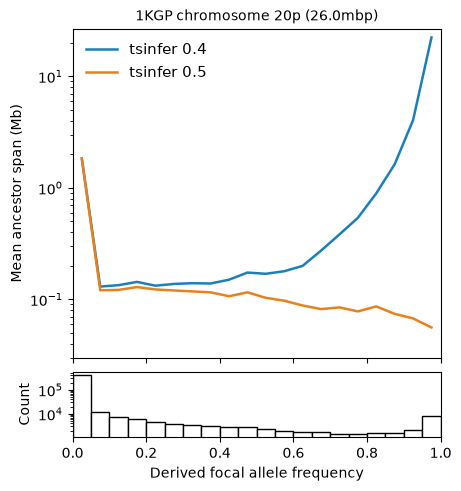

In [176]:
nb_plot.plot_ancestor_span_curves(
    ancestor_span_curve_summary,
    "1000 Genomes Project",
    config=config,
    title=f"1KGP chromosome 20p ({tgp_inference_width_mb:.1f}mbp)",
    figure_folder=figure_folder,
    y_log=True,
    dpi=300,
    span_curve_height_ratios=(3, 0.6),
    span_curve_legend_fontsize=11,
    span_curve_limit_factor=1.2,
    span_curve_line_width=1.8,
    span_curve_size=(4.5, 4.8),
    span_curve_title_fontsize=10,
    span_curve_true_color="#8b0000",
    version_colors=("#1a80bb", "#ea801c"),
)

Plotted every observation: 1,433,140 points; size=3.5; alpha=0.15


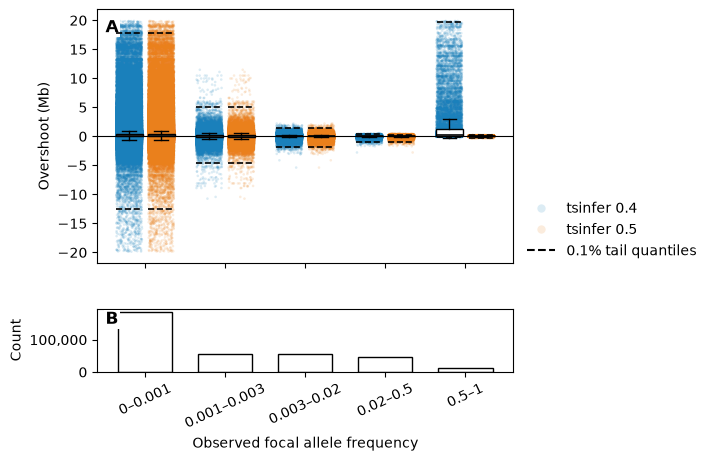

Prepared thesis export: ancestor_overshoot_boxplot.png


In [2]:
# Show every focal-site side with smaller markers; other boxplots retain their sampling settings.
frequency_boxplot_config = dataclasses.replace(
    config, jitter_max_points=None, jitter_size=3.5
)
frequency_boxplot_data = dataclasses.replace(data, config=frequency_boxplot_config)
nb_plot.plot_ancestor_overshoot(
    frequency_boxplot_data,
    figure_folder=figure_folder,
    cutoffs=[0, 0.001, 0.003, 0.02, 0.5, 1],
    conf=0.001,
    figsize=(7, 4.5),
    y_log=False,
    ancestor_count_fontsize=8,
    ancestor_count_margin=0.35,
    ancestor_count_padding=2,
    ancestor_panel_spacing=0.18,
    box_size=(7, 4.5),
    dpi=300,
    jitter_alpha=0.15,
    jitter_max_points=1500,
    jitter_sample_interval_mb=(-1, 1),
    jitter_seed=42,
    jitter_size=5,
    jitter_width=0.32,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    overshoot_linthresh_bp=1000,
    quantile_line_style="--",
    quantile_line_width=1.2,
    quantile_secondary_color="#555555",
    quantile_secondary_line_style="-.",
    true_color="#b8b8b8",
    version_colors=("#1a80bb", "#ea801c"),
)

### Pooled overlap mismatch fraction

Use the same error-free profiles and frequency bins as the overshoot plot.
Error counts and overlap lengths describe the whole shared overlap and are
repeated on left/right rows, so use only the left row of each focal-site
comparison. Comparisons sharing an ancestor remain separate, matching the
overshoot plot. The top panel shows the proportion with zero ancestral-state
errors. The middle panel pools `sum(num_errors) / sum(overlap_site_span)` within
each version and bin, rather than averaging per-comparison error rates.
Solid bars show total mismatch fraction without splitting error directions;
colours identify tsinfer versions and the mismatch-fraction axis is logarithmic.
Orange labels above the pooled-mismatch-fraction bars show 100 × (0.5 / 0.4 - 1),
using each version's total pooled mismatch fraction in that frequency bin.
The bottom panel counts focal-site comparisons, shared by both versions.
This figure is saved for the error-free results section of the thesis.

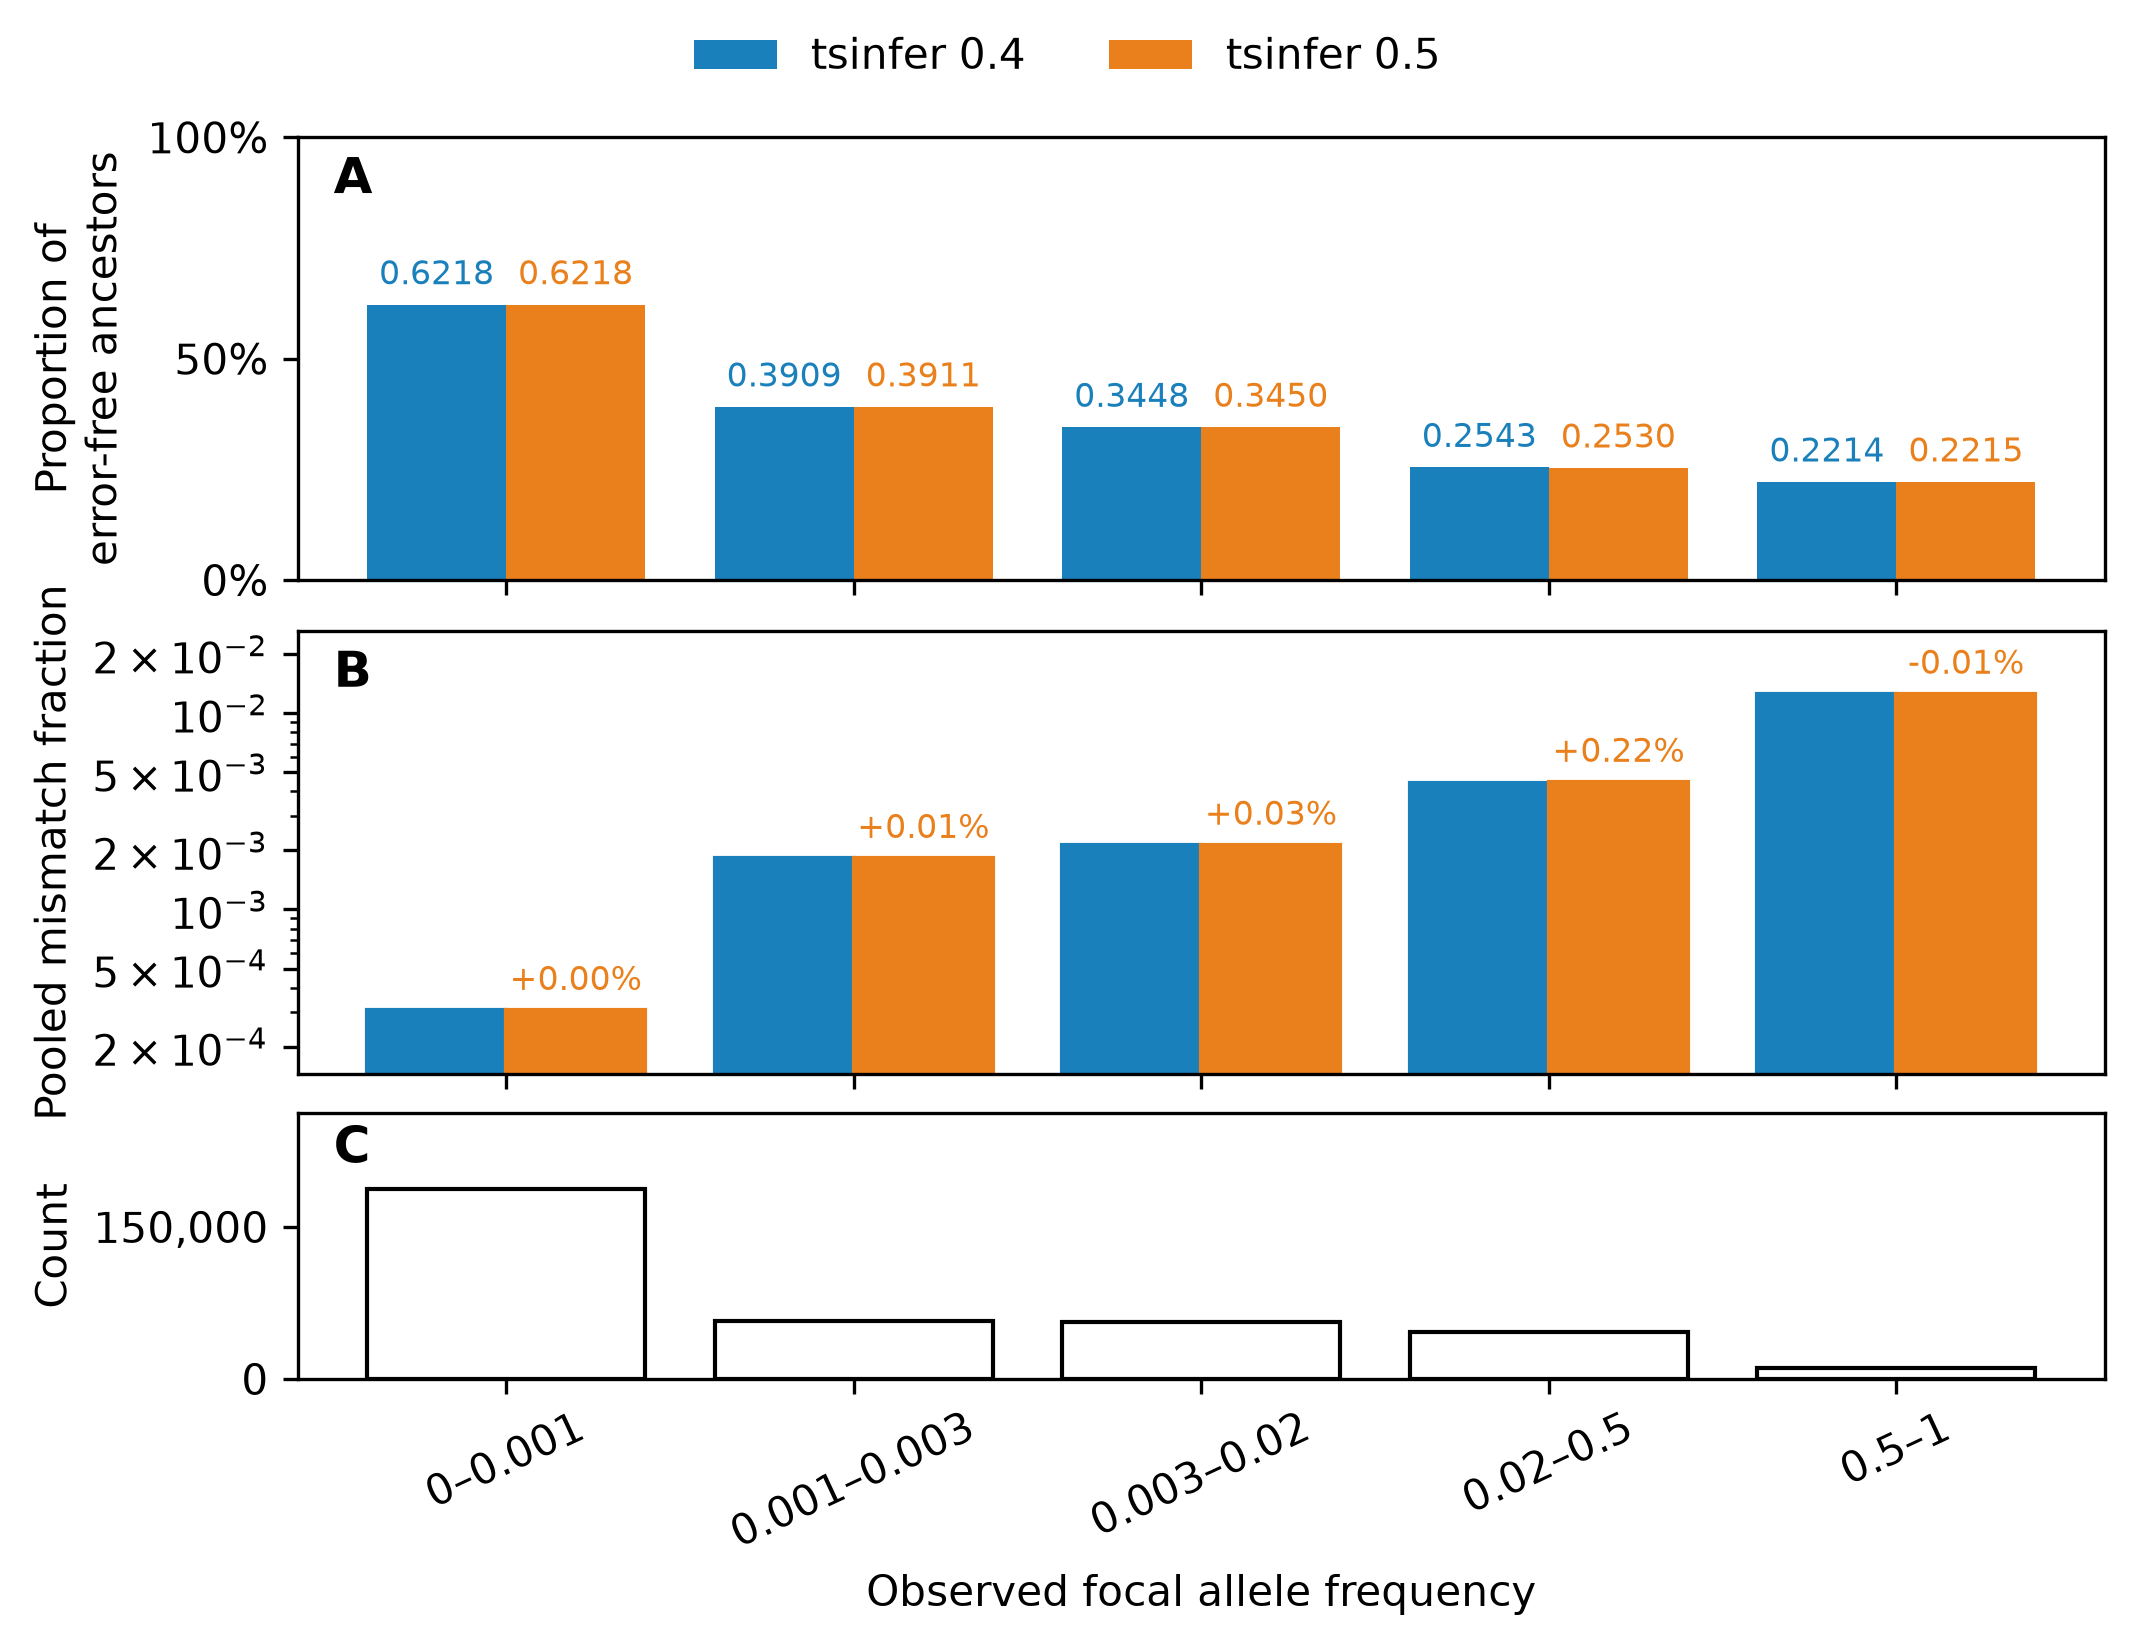

In [ ]:
ancestor_overlap_errors = nb_utils.load_ancestor_overlap_errors(
    aggregated_path, config=config
)
ancestor_error_summary = nb_utils.summarise_ancestor_overlap_errors(
    ancestor_overlap_errors,
    config=dataclasses.replace(config, ancestor_error_label_decimals=4),
    cutoffs=[0, 0.001, 0.003, 0.02, 0.5, 1],
)
nb_plot.plot_ancestor_overlap_errors(
    ancestor_error_summary,
    figure_folder=figure_folder,
    config=dataclasses.replace(
        config, ancestor_error_label_decimals=4, ancestor_error_y_log=True
    ),
    figsize=(7, 5.4),
    show_mismatch_change=True,
    panel_labels=("A", "B", "C"),
    split_error_types=False,
    ancestor_error_change_decimals=2,
    ancestor_error_count_margin=0.4,
    ancestor_error_hatch="///",
    ancestor_error_height_ratios=(1, 1, 0.6),
    ancestor_error_label_decimals=3,
    ancestor_error_label_fontsize=8,
    ancestor_error_label_padding=3,
    ancestor_error_legend_fontsize=9,
    ancestor_error_log_numticks=6,
    ancestor_error_log_subs=(1, 2, 5),
    ancestor_error_size=(7, 5.4),
    ancestor_error_type_labels=("True = 0, Observed = 1", "True = 1, Observed = 0"),
    ancestor_error_y_log=True,
    ancestor_mismatch_fraction_label_margin=0.2,
    dpi=300,
    mean_bar_group_width=0.8,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    version_colors=("#1a80bb", "#ea801c"),
)

### Comparison across demographic models

Compare error-free profiles from four simulations, each with 6,000 diploid
individuals across the first 20 Mb of chromosome 20. The American admixture
simulation samples 1,500 individuals from each of its four populations.
All comparisons pool focal allele frequencies within each demographic model.
The usual overshoot boxes retain both sides per focal site, with the same
jitter and 0.1% tail quantiles as the error-free overshoot plot above.
The pooled mismatch fraction uses each whole overlap once (left rows only), retaining
the error-free proportion and stacked error-direction panels without counts.
The two-column quantile summary and pooled mismatch fraction are exported to the thesis;
the original jitter boxplot remains in the notebook for comparison.

Out of Africa uses the updated 20 Mb aggregate in data/ch3; the
other three models use the replacement aggregates generated with the new branch.

In [2]:
demography_labels = {
    "OutOfAfrica_3G09": "Out of Africa\n(3G09)",
    "AmericanAdmixture_4B18": "American\nadmixture\n(4B18)",
    "Africa_1T12": "Africa\n(1T12)",
    "Zigzag_1S14": "Zigzag\n(1S14)",
}
demography_paths = {
    model: aggregated_folder / f"{model}-chr20-L0-R2e7-n6000-s1-aggregated.csv"
    for model in demography_labels
}
demography_paths["OutOfAfrica_3G09"] = aggregated_path
demography_comparisons = nb_utils.load_demography_comparisons(
    demography_paths, config=config
)

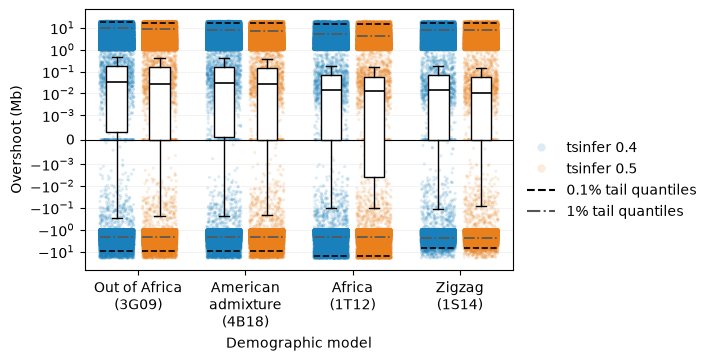

In [203]:
nb_plot.plot_demography_overshoot_box(
    demography_comparisons,
    demography_labels,
    config=config,
    figure_folder=figure_folder,
    conf=0.001,
    conf_secondary=0.01,
    figsize=(7, 3.5),
    y_log=True,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    jitter_alpha=0.15,
    jitter_max_points=1500,
    jitter_sample_interval_mb=(-1, 1),
    jitter_seed=42,
    jitter_size=5,
    jitter_width=0.32,
    overshoot_box_size=(8.5, 3.5),
    overshoot_box_width_ratio=0.6,
    overshoot_linthresh_bp=1000,
    phase_ser_decimals=2,
    quantile_line_style="--",
    quantile_line_width=1.2,
    quantile_secondary_color="#555555",
    quantile_secondary_line_style="-.",
    version_colors=("#1a80bb", "#ea801c"),
)

The thesis uses a separate two-column quantile summary: medians and IQRs
on a central kb axis, and extreme quantiles on a full-range Mb axis.
Each demographic model has its own row, with the usual version colours.

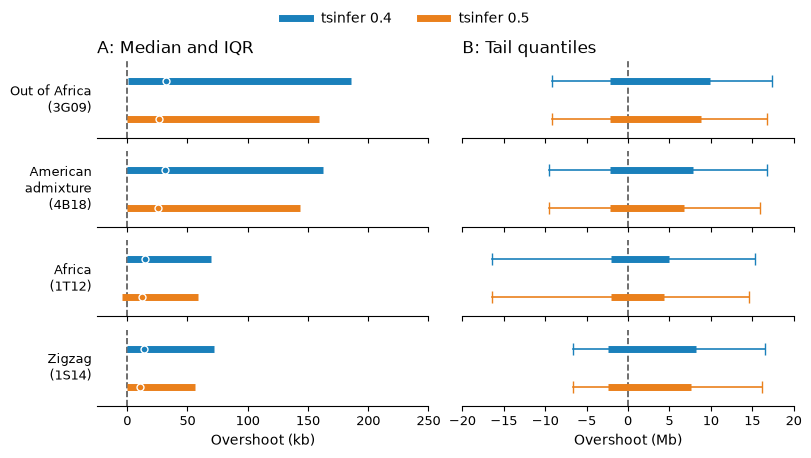

Prepared thesis export: demography_overshoot_quantiles.png


In [3]:
nb_plot.plot_demography_overshoot_quantiles(
    demography_comparisons,
    demography_labels,
    config=config,
    figure_folder=figure_folder,
    figsize=(8, 4.5),
    demography_quantile_cap_size=8,
    demography_quantile_center_limits_kb=(-25, 250),
    demography_quantile_interval_width=5,
    demography_quantile_label_fontsize=9,
    demography_quantile_marker_size=5,
    demography_quantile_probabilities=(0.001, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999),
    demography_quantile_size=(8, 4.5),
    demography_quantile_tail_limits_mb=(-20, 20),
    dpi=300,
    quantile_line_style="--",
    quantile_line_width=1.2,
    version_colors=("#1a80bb", "#ea801c"),
    zero_color="#555555",
)

#### Verification: IQRs and tail quantiles used in the text

These checks use exactly the error-free observations in the boxplot above:
both sides of every focal-site comparison, with no frequency bins or
deduplication of sites that share an ancestor. IDs are local to each model.
Quantiles use linear interpolation on the untransformed overshoots in bp.
IQR = Q75 - Q25; divide by 1,000 for kb. The common upper bound is the
ceiling of the largest IQR in kb across all four models and both versions.

In [181]:
# Cross-check the grouped pandas results against the NumPy call used by the plot.
demography_check_settings = {
    "bp_per_kb": 1000,
    "primary_tail_probability": 0.001,
    "secondary_tail_probability": 0.01,
    "quantiles": [0.001, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999],
}
demography_site_keys = ["model", "version", "replicate", "true_focal_site"]
demography_side_keys = demography_site_keys + ["side"]
assert not demography_comparisons.duplicated(demography_side_keys).any()
assert set(demography_comparisons.side) == {"left", "right"}
demography_sides_per_site = demography_comparisons.groupby(demography_site_keys).size()
assert demography_sides_per_site.eq(2).all()
demography_group_order = pd.MultiIndex.from_product(
    [demography_labels, config.versions], names=["model", "version"]
)
demography_overshoot_groups = demography_comparisons.groupby(["model", "version"])
demography_quantiles_bp = demography_overshoot_groups.overshoot.quantile(
    demography_check_settings["quantiles"], interpolation="linear"
).unstack()
demography_quantiles_bp = demography_quantiles_bp.reindex(demography_group_order)
for group, frame in demography_overshoot_groups:
    numpy_quantiles = np.quantile(
        frame.overshoot, demography_check_settings["quantiles"]
    )
    np.testing.assert_allclose(
        numpy_quantiles, demography_quantiles_bp.loc[group].to_numpy()
    )
demography_iqr_table = pd.DataFrame(index=demography_group_order)
demography_iqr_table["num_focal_site_sides"] = demography_overshoot_groups.size()
demography_iqr_table["q25_kb"] = (
    demography_quantiles_bp[0.25] / demography_check_settings["bp_per_kb"]
)
demography_iqr_table["median_kb"] = (
    demography_quantiles_bp[0.5] / demography_check_settings["bp_per_kb"]
)
demography_iqr_table["q75_kb"] = (
    demography_quantiles_bp[0.75] / demography_check_settings["bp_per_kb"]
)
demography_iqr_table["iqr_kb"] = (
    demography_iqr_table.q75_kb - demography_iqr_table.q25_kb
)
demography_largest_iqr = demography_iqr_table.iqr_kb.idxmax()
demography_max_iqr_kb = demography_iqr_table.iqr_kb.max()
demography_iqr_bound_kb = int(np.ceil(demography_max_iqr_kb))
assert demography_iqr_table.iqr_kb.lt(demography_iqr_bound_kb).all()
ipd.display(
    demography_iqr_table.style.format(
        {
            "num_focal_site_sides": "{:,.0f}",
            "q25_kb": "{:.3f}",
            "median_kb": "{:.3f}",
            "q75_kb": "{:.3f}",
            "iqr_kb": "{:.3f}",
        }
    ).set_caption("Quartiles, median and IQR (Q75 - Q25) for every model and version")
)
demography_iqr_bound_table = pd.DataFrame(
    [
        {
            "worst_model": demography_largest_iqr[0],
            "worst_version": demography_largest_iqr[1],
            "max_iqr_kb": demography_max_iqr_kb,
            "ceil_max_iqr_kb": demography_iqr_bound_kb,
        }
    ]
)
ipd.display(
    demography_iqr_bound_table.style.format({"max_iqr_kb": "{:.3f}"}).set_caption(
        "Text bound: ceil(maximum IQR in kb)"
    )
)

,worst_model,worst_version,max_iqr_kb,ceil_max_iqr_kb
0,OutOfAfrica_3G09,0.4.1,185.467,186


The primary caps mark Q0.001 and Q0.999 (0.1st and 99.9th percentiles),
so each nominal tail contains 0.1% of **focal-site-side observations**.
They do not denote 0.05% of ancestors. The secondary caps mark Q0.01 and
Q0.99. The counts below use a strict inequality; ties can make the empirical
lower-tail percentage slightly smaller than its nominal value.

In [182]:
demography_primary_tail = demography_check_settings["primary_tail_probability"]
demography_secondary_tail = demography_check_settings["secondary_tail_probability"]
demography_tail_table = pd.DataFrame(index=demography_group_order)
demography_tail_table["lower_0_1_pct_mb"] = (
    demography_quantiles_bp[demography_primary_tail] / config.bp_per_mb
)
demography_tail_table["upper_99_9_pct_mb"] = (
    demography_quantiles_bp[1 - demography_primary_tail] / config.bp_per_mb
)
demography_tail_table["lower_1_pct_mb"] = (
    demography_quantiles_bp[demography_secondary_tail] / config.bp_per_mb
)
demography_tail_table["upper_99_pct_mb"] = (
    demography_quantiles_bp[1 - demography_secondary_tail] / config.bp_per_mb
)
demography_lower_tail_counts = []
for group, frame in demography_overshoot_groups:
    threshold = demography_quantiles_bp.loc[group, demography_primary_tail]
    num_below = int((frame.overshoot < threshold).sum())
    demography_lower_tail_counts.append(
        {
            "model": group[0],
            "version": group[1],
            "num_sides": len(frame),
            "num_below_primary_lower_quantile": num_below,
            "observed_lower_tail_pct": 100 * num_below / len(frame),
        }
    )
ipd.display(
    demography_tail_table.style.format("{:.5f}").set_caption(
        "Signed tail cutoffs in Mb; round to two decimals for the text"
    )
)
demography_lower_tail_count_table = pd.DataFrame(demography_lower_tail_counts)
demography_lower_tail_count_table = demography_lower_tail_count_table.set_index(
    ["model", "version"]
)
demography_lower_tail_count_table = demography_lower_tail_count_table.reindex(
    demography_group_order
)
ipd.display(
    demography_lower_tail_count_table.style.format(
        {
            "num_sides": "{:,.0f}",
            "num_below_primary_lower_quantile": "{:,.0f}",
            "observed_lower_tail_pct": "{:.5f}",
        }
    ).set_caption(
        "Tail check: 100 × count(overshoot < lower primary quantile) / number of sides"
    )
)

Pair versions **within each model** before averaging. A positive lower-tail
change means the tsinfer 0.5 cutoff is less negative:
`(Q0.001_0.5 - Q0.001_0.4) / 1,000` kb. Each of the four models receives
equal weight; this is not a quantile of pooled observations. Positive upper
reductions mean `Q0.999_0.4 - Q0.999_0.5` is positive. The same calculation
is shown for the secondary lower quantile to distinguish the two cap pairs.

In [183]:
demography_old_version, demography_new_version = config.versions
demography_lower_primary = demography_quantiles_bp[demography_primary_tail].unstack(
    "version"
)
demography_upper_primary = demography_quantiles_bp[1 - demography_primary_tail].unstack(
    "version"
)
demography_lower_secondary = demography_quantiles_bp[demography_secondary_tail].unstack(
    "version"
)
demography_tail_changes = pd.DataFrame(index=list(demography_labels))
demography_tail_changes.index.name = "model"
demography_tail_changes["lower_0_4_mb"] = (
    demography_lower_primary[demography_old_version] / config.bp_per_mb
)
demography_tail_changes["lower_0_5_mb"] = (
    demography_lower_primary[demography_new_version] / config.bp_per_mb
)
demography_tail_changes["lower_0_4_bp"] = demography_lower_primary[
    demography_old_version
]
demography_tail_changes["lower_0_5_bp"] = demography_lower_primary[
    demography_new_version
]
demography_tail_changes["primary_lower_change_bp"] = (
    demography_lower_primary[demography_new_version]
    - demography_lower_primary[demography_old_version]
)
demography_tail_changes["primary_lower_change_kb"] = (
    demography_tail_changes.primary_lower_change_bp
    / demography_check_settings["bp_per_kb"]
)
demography_tail_changes["upper_0_4_mb"] = (
    demography_upper_primary[demography_old_version] / config.bp_per_mb
)
demography_tail_changes["upper_0_5_mb"] = (
    demography_upper_primary[demography_new_version] / config.bp_per_mb
)
demography_tail_changes["upper_reduction_kb"] = (
    demography_upper_primary[demography_old_version]
    - demography_upper_primary[demography_new_version]
) / demography_check_settings["bp_per_kb"]
demography_tail_changes["secondary_lower_change_bp"] = (
    demography_lower_secondary[demography_new_version]
    - demography_lower_secondary[demography_old_version]
)
demography_tail_changes["secondary_lower_change_kb"] = (
    demography_tail_changes.secondary_lower_change_bp
    / demography_check_settings["bp_per_kb"]
)
assert demography_tail_changes.upper_reduction_kb.gt(0).all()
ipd.display(
    demography_tail_changes.style.format("{:.5f}").set_caption(
        "Paired changes: positive lower change = less negative; positive upper reduction = shorter upper tail"
    )
)
demography_lower_change_sum_bp = demography_tail_changes.primary_lower_change_bp.sum()
demography_lower_change_sum_kb = demography_tail_changes.primary_lower_change_kb.sum()
demography_num_models = len(demography_tail_changes)
demography_mean_lower_change_bp = demography_lower_change_sum_bp / demography_num_models
demography_mean_lower_change_kb = demography_lower_change_sum_kb / demography_num_models
demography_lower_change_working = pd.DataFrame(
    [
        {
            "sum_of_primary_lower_changes_bp": demography_lower_change_sum_bp,
            "sum_of_primary_lower_changes_kb": demography_lower_change_sum_kb,
            "num_equally_weighted_models": demography_num_models,
            "mean_primary_lower_change_bp": demography_mean_lower_change_bp,
            "mean_primary_lower_change_kb": demography_mean_lower_change_kb,
            "mean_secondary_lower_change_bp": demography_tail_changes.secondary_lower_change_bp.mean(),
        }
    ]
)
ipd.display(
    demography_lower_change_working.style.format(
        {
            "sum_of_primary_lower_changes_bp": "{:.5f}",
            "mean_primary_lower_change_bp": "{:.5f}",
            "sum_of_primary_lower_changes_kb": "{:.5f}",
            "mean_primary_lower_change_kb": "{:.5f}",
            "mean_secondary_lower_change_bp": "{:.5f}",
        }
    ).set_caption("Working for the text: sum of four paired lower-tail changes / 4")
)

,lower_0_4_mb,lower_0_5_mb,lower_0_4_bp,lower_0_5_bp,primary_lower_change_bp,primary_lower_change_kb,upper_0_4_mb,upper_0_5_mb,upper_reduction_kb,secondary_lower_change_bp,secondary_lower_change_kb
model,,,,,,,,,,,
OutOfAfrica_3G09,-9.21230,-9.21230,-9212299.00000,-9212299.00000,0.00000,0.00000,17.43028,16.82673,603.55124,-2748.79000,-2.74879
AmericanAdmixture_4B18,-9.48886,-9.48886,-9488857.23100,-9488857.23100,0.00000,0.00000,16.83398,15.99487,839.10612,0.00000,0.00000
Africa_1T12,-16.44240,-16.44240,-16442395.00000,-16442395.00000,0.00000,0.00000,15.30906,14.57055,738.50700,-420.06000,-0.42006
Zigzag_1S14,-6.59499,-6.59499,-6594987.61900,-6594987.61900,0.00000,0.00000,16.59217,16.14087,451.29745,-45.87000,-0.04587


,sum_of_primary_lower_changes_bp,sum_of_primary_lower_changes_kb,num_equally_weighted_models,mean_primary_lower_change_bp,mean_primary_lower_change_kb,mean_secondary_lower_change_bp
0,0.00000,0.00000,4,0.00000,0.00000,-803.68000


**Citation check.** The [stdpopsim catalog](https://github.com/popsim-consortium/stdpopsim/blob/main/stdpopsim/catalog/HomSap/demographic_models.py)
identifies Zigzag_1S14 as a validation model with periodic growth and decline,
citing Schiffels and Durbin (2014), [doi:10.1038/ng.3015](https://doi.org/10.1038/ng.3015).
This matches the existing thesis bibliography key `schiffels2014inferring`.

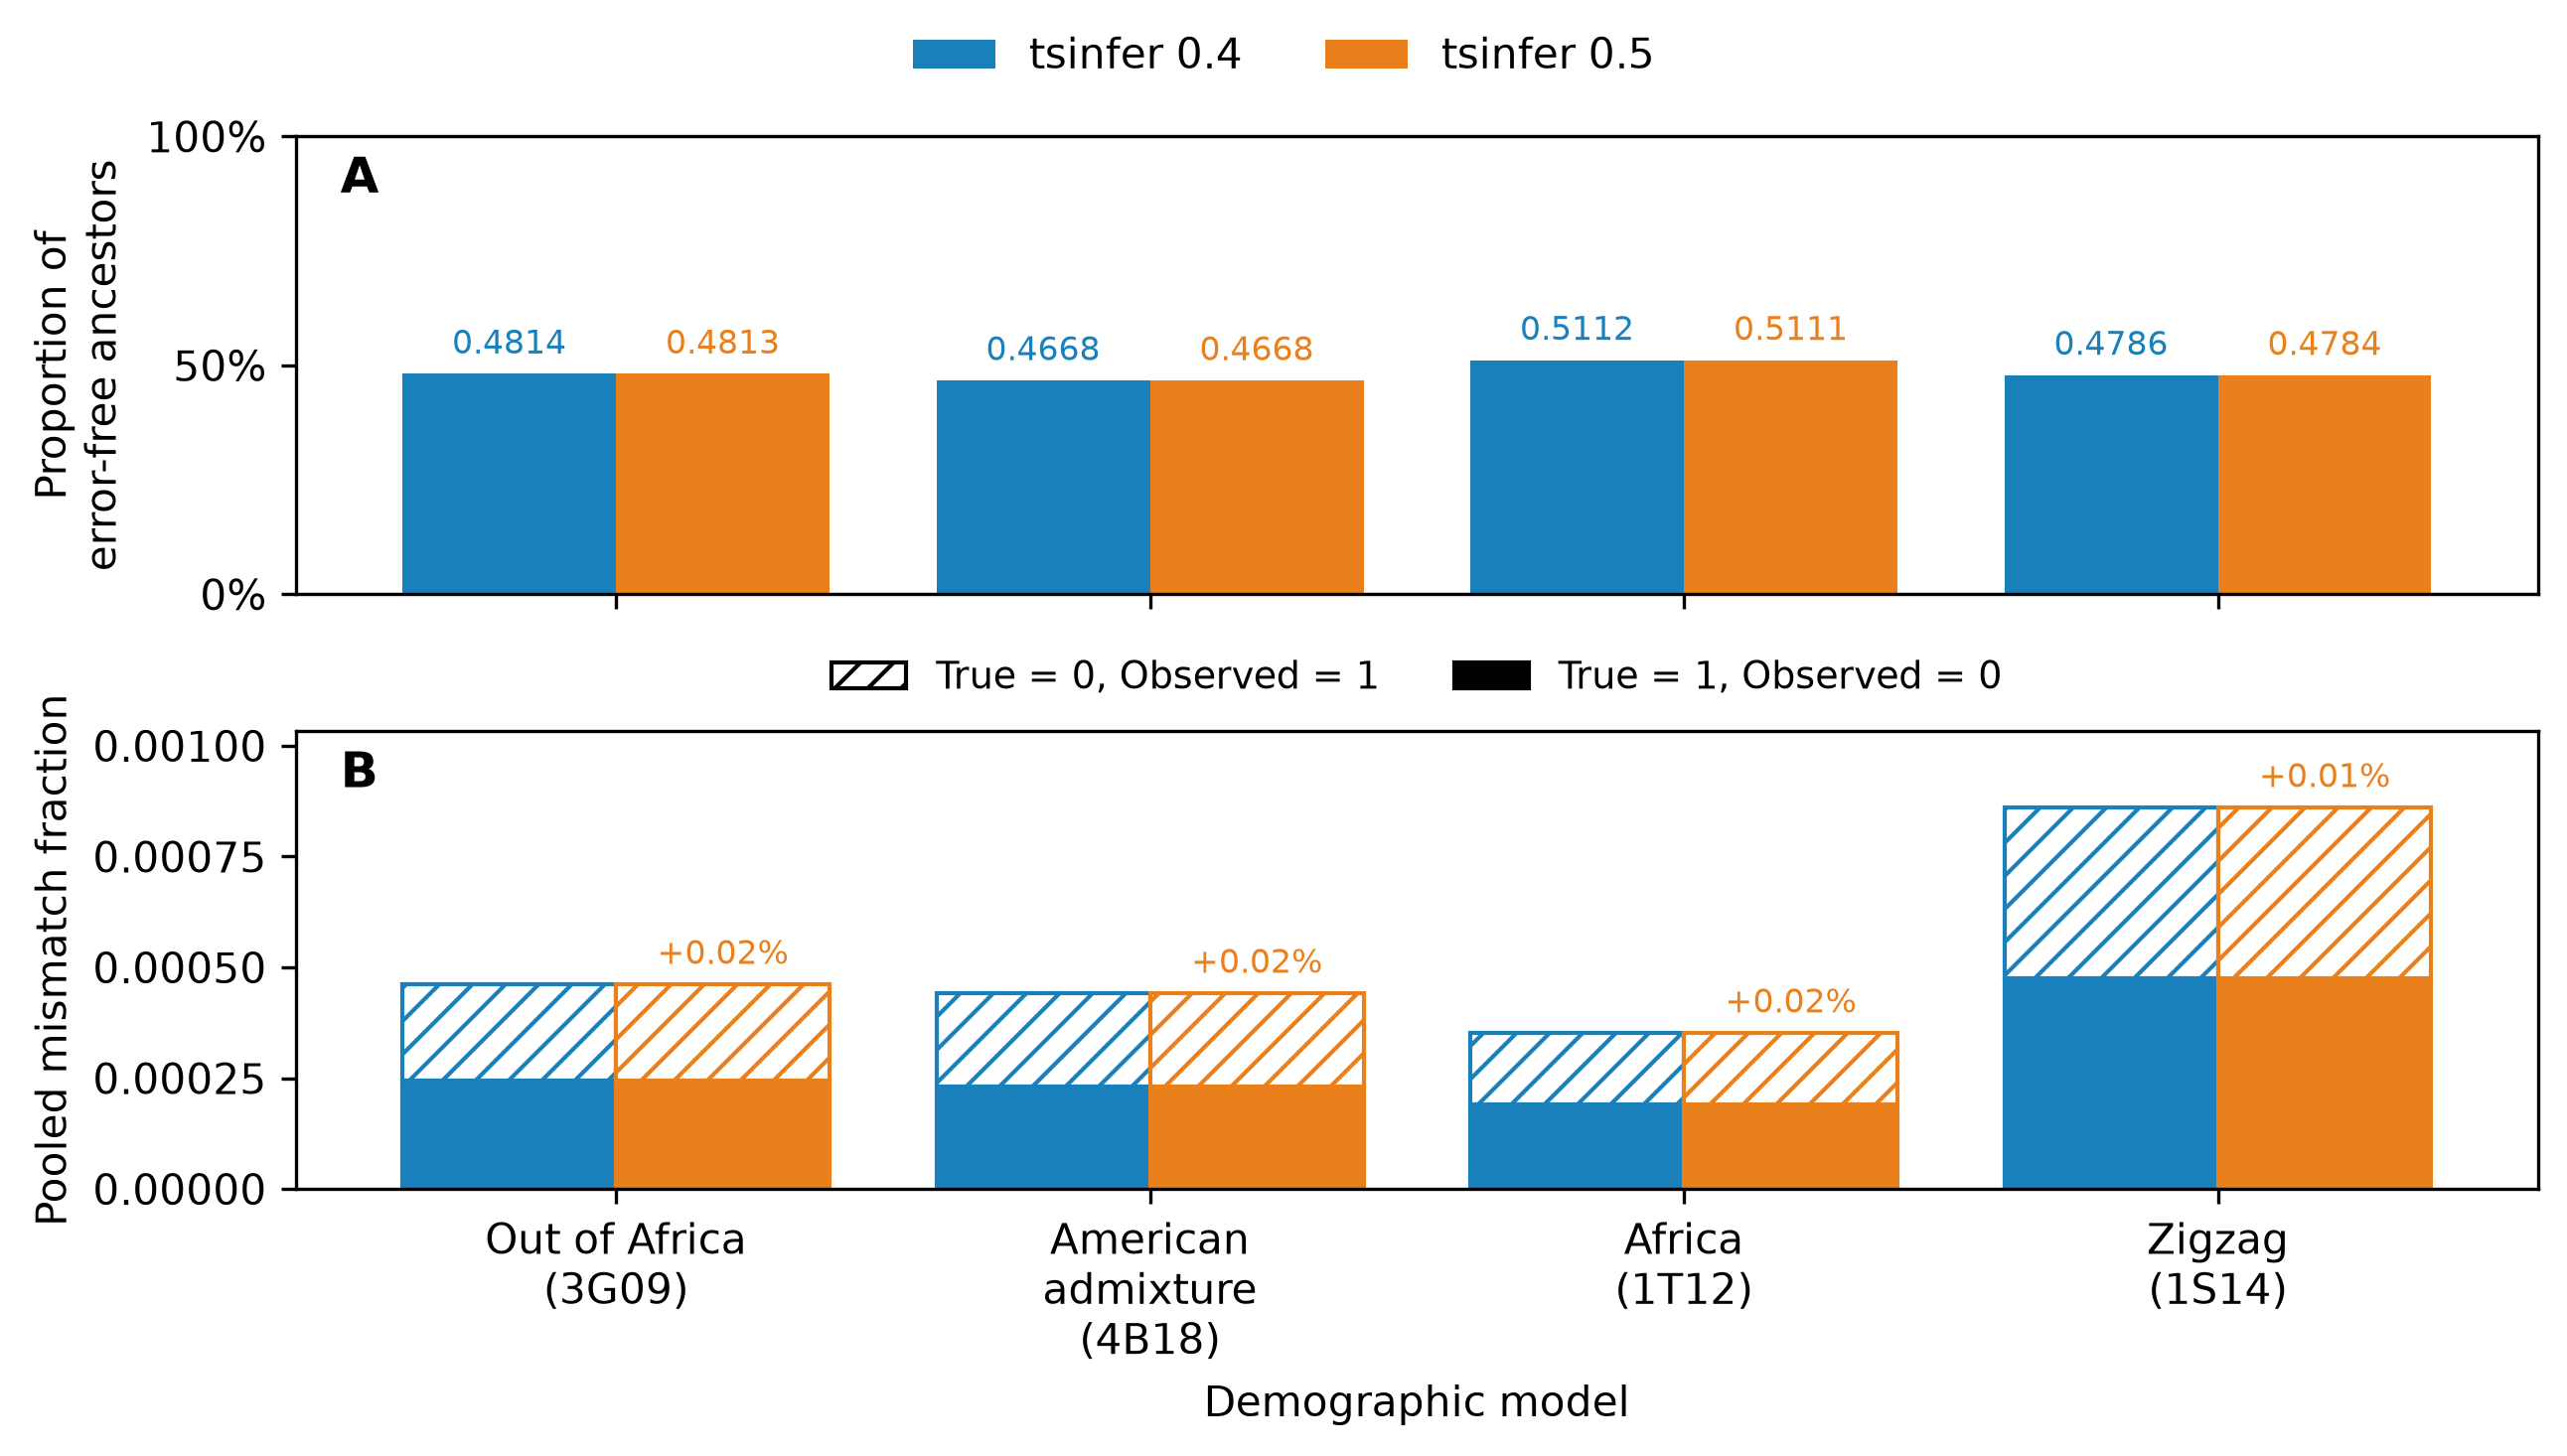

In [ ]:
demography_error_summary = nb_utils.summarise_demography_overlap_errors(
    demography_comparisons
)
nb_plot.plot_ancestor_overlap_errors(
    demography_error_summary,
    config=dataclasses.replace(
        config, ancestor_error_label_decimals=4, ancestor_error_y_log=False
    ),
    figsize=(8.5, 4.8),
    figure_folder=figure_folder,
    group_by="model",
    group_labels=demography_labels,
    show_counts=False,
    name="demography_overlap_errors",
    show_mismatch_change=True,
    panel_labels=("A", "B"),
    ancestor_error_change_decimals=2,
    ancestor_error_count_margin=0.4,
    ancestor_error_hatch="///",
    ancestor_error_height_ratios=(1, 1, 0.6),
    ancestor_error_label_decimals=3,
    ancestor_error_label_fontsize=8,
    ancestor_error_label_padding=3,
    ancestor_error_legend_fontsize=9,
    ancestor_error_log_numticks=6,
    ancestor_error_log_subs=(1, 2, 5),
    ancestor_error_size=(7, 5.4),
    ancestor_error_type_labels=("True = 0, Observed = 1", "True = 1, Observed = 0"),
    ancestor_error_y_log=True,
    ancestor_mismatch_fraction_label_margin=0.2,
    dpi=300,
    mean_bar_group_width=0.8,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    version_colors=("#1a80bb", "#ea801c"),
)

#### Verification: error-containing comparisons and pooled mismatch fraction

The whole-overlap error counts and lengths are duplicated on left/right
rows. Keep only the **left** row, once per model, version, replicate and
focal site. Comparisons sharing an ancestor remain separate.
`error-containing fraction = count(num_errors > 0) / number of comparisons`;
`pooled mismatch fraction = sum(num_errors) / sum(overlap_site_span)`.
The increase in the fraction containing errors is reported in **percentage
points**, separately from the relative percentage increase.

In [ ]:
demography_whole_overlaps = demography_comparisons.loc[
    demography_comparisons.side == "left"
].copy()
assert not demography_whole_overlaps.duplicated(demography_site_keys).any()
demography_whole_overlaps["contains_error"] = demography_whole_overlaps.num_errors > 0
demography_error_checks = demography_whole_overlaps.groupby(["model", "version"]).agg(
    num_comparisons=("true_focal_site", "size"),
    num_with_errors=("contains_error", "sum"),
    total_errors=("num_errors", "sum"),
    total_overlap_bp=("overlap_span", "sum"),
    total_overlap_sites=("overlap_site_span", "sum"),
    true_0_observed_1_errors=("num_should_be_1", "sum"),
    true_1_observed_0_errors=("num_should_be_0", "sum"),
)
demography_error_checks = demography_error_checks.reindex(demography_group_order)
demography_error_checks["num_error_free"] = (
    demography_error_checks.num_comparisons - demography_error_checks.num_with_errors
)
demography_error_checks["fraction_with_errors"] = (
    demography_error_checks.num_with_errors / demography_error_checks.num_comparisons
)
demography_error_checks["pooled_mismatch_fraction"] = (
    demography_error_checks.total_errors / demography_error_checks.total_overlap_sites
)
demography_plotted_error_summary = demography_error_summary.set_index(
    ["model", "version"]
)
demography_plotted_error_summary = demography_plotted_error_summary.reindex(
    demography_group_order
)
np.testing.assert_array_equal(
    demography_error_checks.num_comparisons,
    demography_plotted_error_summary.num_ancestors,
)
np.testing.assert_array_equal(
    demography_error_checks.num_error_free,
    demography_plotted_error_summary.num_error_free,
)
np.testing.assert_allclose(
    demography_error_checks.pooled_mismatch_fraction,
    demography_plotted_error_summary.mismatch_fraction,
)
ipd.display(
    demography_error_checks[
        [
            "num_comparisons",
            "num_error_free",
            "num_with_errors",
            "fraction_with_errors",
            "total_errors",
            "total_overlap_sites",
            "pooled_mismatch_fraction",
        ]
    ]
    .style.format(
        {
            "num_comparisons": "{:,.0f}",
            "num_error_free": "{:,.0f}",
            "num_with_errors": "{:,.0f}",
            "fraction_with_errors": "{:.6f}",
            "total_errors": "{:,.0f}",
            "total_overlap_sites": "{:,.0f}",
            "pooled_mismatch_fraction": "{:.8e}",
        }
    )
    .set_caption(
        "Numerators and denominators: count of error-containing comparisons, and ratio-of-sums mismatch fraction"
    )
)

In [186]:
# Reproduce the relative percentage changes labelled on the pooled-mismatch-fraction bars.
demography_error_fractions = demography_error_checks.fraction_with_errors.unstack(
    "version"
)
demography_error_changes = pd.DataFrame(index=list(demography_labels))
demography_error_changes.index.name = "model"
demography_error_changes["with_errors_0_4_pct"] = (
    100 * demography_error_fractions[demography_old_version]
)
demography_error_changes["with_errors_0_5_pct"] = (
    100 * demography_error_fractions[demography_new_version]
)
demography_error_changes["increase_percentage_points"] = (
    demography_error_changes.with_errors_0_5_pct
    - demography_error_changes.with_errors_0_4_pct
)
demography_error_changes["relative_increase_pct"] = 100 * (
    demography_error_fractions[demography_new_version]
    / demography_error_fractions[demography_old_version]
    - 1
)
ipd.display(
    demography_error_changes.style.format("{:.5f}").set_caption(
        "Version comparison: absolute percentage-point change versus relative percentage increase"
    )
)
demography_mismatch_fractions = (
    demography_error_checks.pooled_mismatch_fraction.unstack("version")
)
demography_error_totals = demography_error_checks.total_errors.unstack("version")
demography_overlap_totals = demography_error_checks.total_overlap_sites.unstack(
    "version"
)
demography_error_counts = demography_error_checks.num_with_errors.unstack("version")
demography_mismatch_changes = pd.DataFrame(index=list(demography_labels))
demography_mismatch_changes.index.name = "model"
demography_mismatch_changes["change_in_comparisons_with_errors"] = (
    demography_error_counts[demography_new_version]
    - demography_error_counts[demography_old_version]
)
demography_mismatch_changes["change_in_total_errors"] = (
    demography_error_totals[demography_new_version]
    - demography_error_totals[demography_old_version]
)
demography_mismatch_changes["change_in_total_overlap_sites"] = (
    demography_overlap_totals[demography_new_version]
    - demography_overlap_totals[demography_old_version]
)
demography_mismatch_changes["relative_mismatch_increase_pct"] = 100 * (
    demography_mismatch_fractions[demography_new_version]
    / demography_mismatch_fractions[demography_old_version]
    - 1
)
demography_plot_mismatch_fractions = (
    demography_plotted_error_summary.mismatch_fraction.unstack("version")
)
demography_plot_mismatch_changes = 100 * (
    demography_plot_mismatch_fractions[demography_new_version]
    / demography_plot_mismatch_fractions[demography_old_version]
    - 1
)
np.testing.assert_allclose(
    demography_mismatch_changes.relative_mismatch_increase_pct,
    demography_plot_mismatch_changes.reindex(demography_labels),
)
demography_mismatch_changes["plot_label"] = (
    demography_mismatch_changes.relative_mismatch_increase_pct.map(
        f"{{:+.{2}f}}%".format
    )
)
ipd.display(
    demography_mismatch_changes.style.format(
        {
            "change_in_comparisons_with_errors": "{:+,.0f}",
            "change_in_total_errors": "{:+,.0f}",
            "change_in_total_overlap_sites": "{:+,.0f}",
            "relative_mismatch_increase_pct": "{:+.8f}",
        }
    ).set_caption(
        "Pooled mismatch fraction: 100 × [(total errors / total compared inference sites) in 0.5 / that in 0.4 − 1]"
    )
)

,with_errors_0_4_pct,with_errors_0_5_pct,increase_percentage_points,relative_increase_pct
model,,,,
OutOfAfrica_3G09,51.86346,51.87379,0.01033,0.01991
AmericanAdmixture_4B18,53.31750,53.32373,0.00623,0.01168
Africa_1T12,48.88048,48.89466,0.01417,0.02900
Zigzag_1S14,52.13700,52.16180,0.02480,0.04756


,change_in_comparisons_with_errors,change_in_total_errors,change_in_total_overlap_bp,relative_burden_increase_pct,plot_label
model,,,,,
OutOfAfrica_3G09,+37,"+1,005",+0,+0.01845569,+0.02%
AmericanAdmixture_4B18,+24,"+1,191",+0,+0.02349931,+0.02%
Africa_1T12,+50,+529,+0,+0.01977692,+0.02%
Zigzag_1S14,+46,+222,+0,+0.00922327,+0.01%


**Error-direction check.** The aggregate writer's names are reversed:
`num_should_be_0` counts true 1 / observed 0, and `num_should_be_1` counts
true 0 / observed 1 (see `lib/utils.py` in tsinfer-anc-eval). Match the plot's
mapping explicitly below and verify that the two directions sum to all
errors. Calculate direction shares from the counts; the apparent segment
heights on a logarithmic stacked-bar axis do not represent these shares.

In [187]:
demography_direction_checks = demography_error_checks[
    ["true_0_observed_1_errors", "true_1_observed_0_errors", "total_errors"]
].copy()
np.testing.assert_array_equal(
    demography_direction_checks.true_0_observed_1_errors
    + demography_direction_checks.true_1_observed_0_errors,
    demography_direction_checks.total_errors,
)
demography_direction_checks["true_0_error_share_pct"] = (
    100
    * demography_direction_checks.true_0_observed_1_errors
    / demography_direction_checks.total_errors
)
demography_direction_checks["true_1_error_share_pct"] = (
    100
    * demography_direction_checks.true_1_observed_0_errors
    / demography_direction_checks.total_errors
)
demography_direction_checks["true_0_mismatch_fraction"] = (
    demography_direction_checks.true_0_observed_1_errors
    / demography_error_checks.total_overlap_sites
)
demography_direction_checks["true_1_mismatch_fraction"] = (
    demography_direction_checks.true_1_observed_0_errors
    / demography_error_checks.total_overlap_sites
)
assert demography_direction_checks.true_1_error_share_pct.gt(50).all()
demography_derived_mismatch_fractions = (
    demography_direction_checks.true_1_mismatch_fraction.unstack("version")
)
for version in config.versions:
    african_fraction = demography_derived_mismatch_fractions.loc["Africa_1T12", version]
    other_fractions = demography_derived_mismatch_fractions.drop(index="Africa_1T12")[
        version
    ]
    assert other_fractions.gt(african_fraction).all()
ipd.display(
    demography_direction_checks.style.format(
        {
            "true_0_observed_1_errors": "{:,.0f}",
            "true_1_observed_0_errors": "{:,.0f}",
            "total_errors": "{:,.0f}",
            "true_0_error_share_pct": "{:.3f}",
            "true_1_error_share_pct": "{:.3f}",
            "true_0_mismatch_fraction": "{:.8e}",
            "true_1_mismatch_fraction": "{:.8e}",
        }
    ).set_caption(
        "Direction counts, shares and mismatch fractions; true 1 errors are the majority in every model/version"
    )
)

### Direction of ancestral-state errors in tsinfer 0.5

Split the error-free tsinfer 0.5 focal-site comparisons into 20 fixed-width
DAF bins, each covering 5 percentage points. Plot rates at bin midpoints,
pooling each error type over the bin's total compared inference sites. Include DAF 1
in the final bin; empty bins have undefined rates.
The aggregate writer's names are reversed: `num_should_be_0` counts true 1
inferred as 0, and `num_should_be_1` counts true 0 inferred as 1. Legend labels
describe the true and observed states of each error direction.
Colours match the genotype-transition plot; zero mismatch fractions are gaps on the log
scale. This exploratory figure is saved in dphil-analysis/figures/ch3.

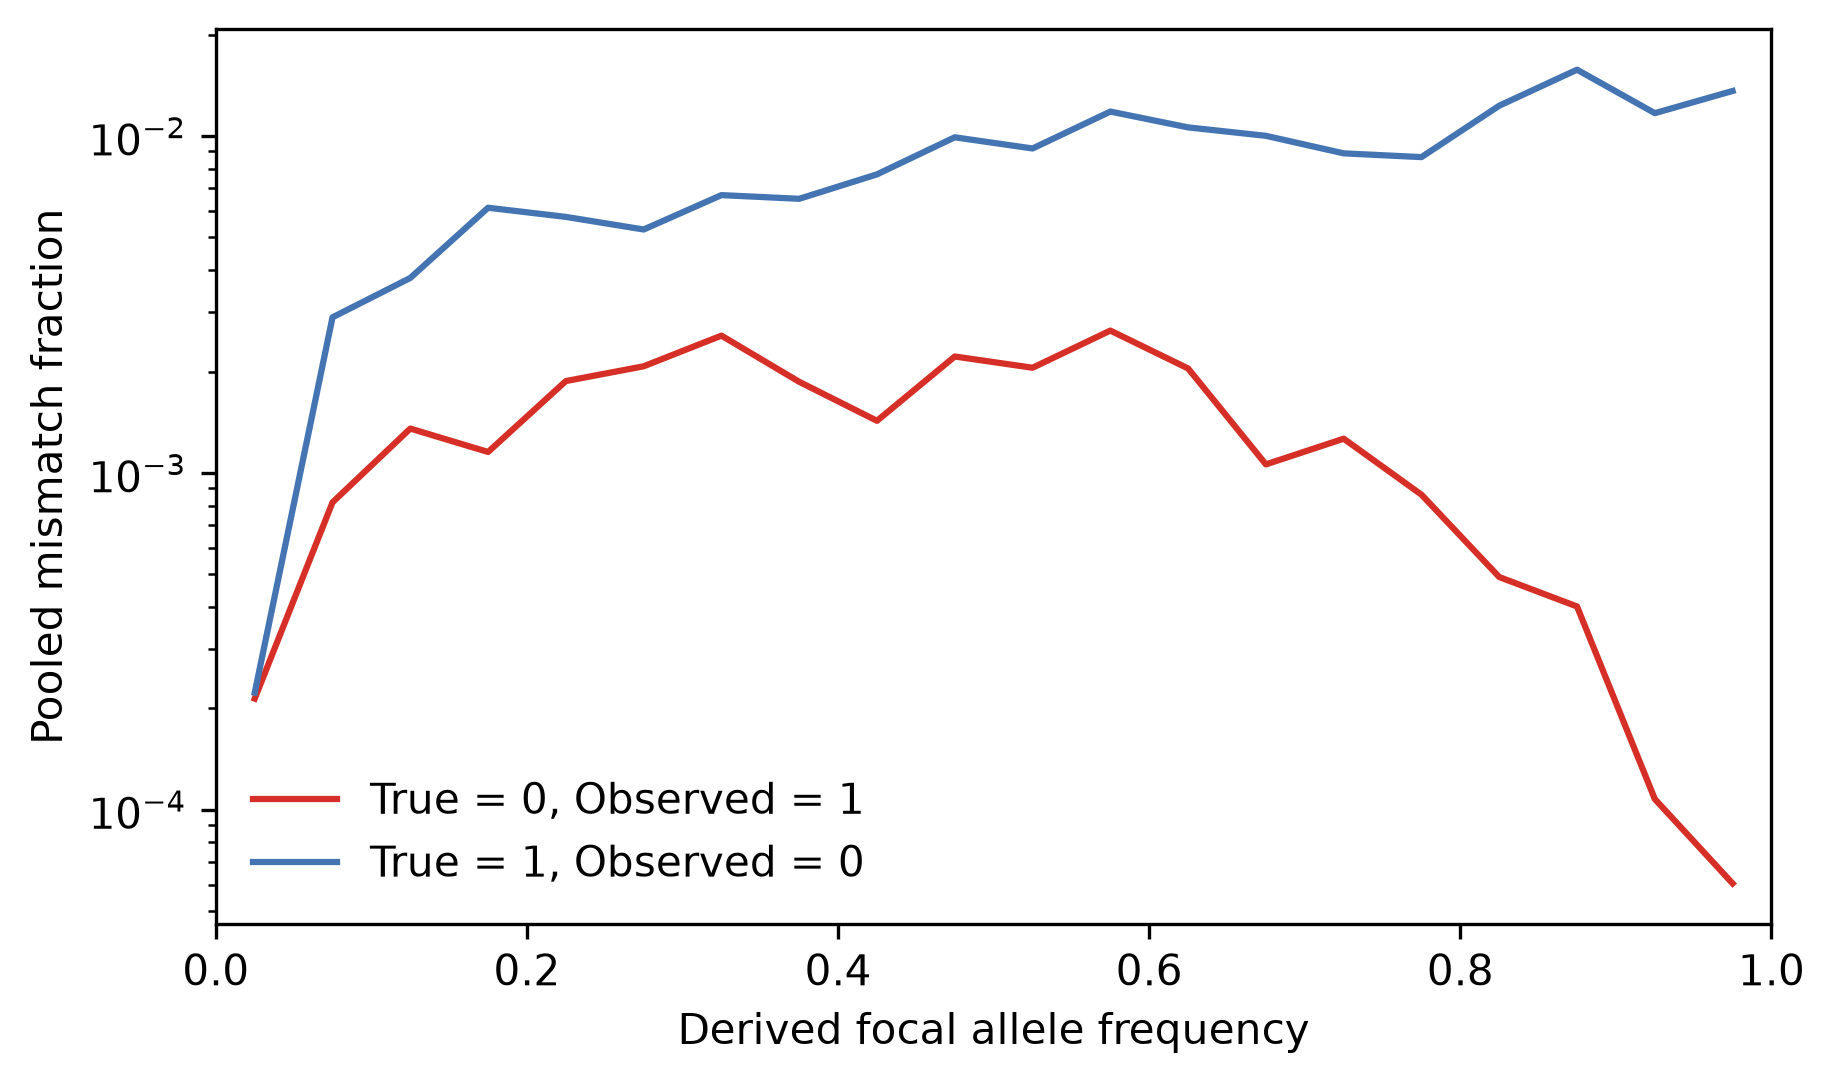

In [ ]:
# don't include
ancestor_error_types = nb_utils.summarise_ancestor_error_types(
    ancestor_overlap_errors,
    config=config,
    ancestor_error_bins=20,
    ancestor_error_version="0.5.1",
)
nb_plot.plot_ancestor_error_types(
    ancestor_error_types,
    figure_folder=figure_folder,
    config=config,
    figsize=(6, 3.5),
    ancestor_error_type_labels=("True = 0, Observed = 1", "True = 1, Observed = 0"),
    curve_size=(6, 3.5),
    dpi=300,
    genotype_color_positions=(0.1, 0.9),
    genotype_transition_cmap="RdYlBu",
)

## Genotype errors

Compare `call_genotype` in each pure genotype-error profile with the error-free
store during HPC extraction. A diploid error changes genotype dosage (00, 01/10,
or 11). Exported counts pool changed calls and denominators across replicates.
The dashed curve scales the observed 1× rate linearly; both axes are logged.

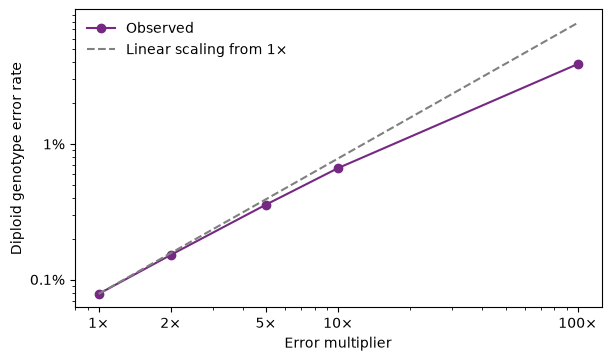

In [189]:
genotype_summary = nb_utils.summarise_genotype_errors(data, transition_bins=40)
nb_plot.plot_genotype_error_scaling(
    genotype_summary,
    figure_folder=figure_folder,
    config=config,
    figsize=(6, 3.5),
    curve_points=256,
    curve_size=(6, 3.5),
    dpi=300,
    genotype_color_positions=(0.1, 0.9),
    genotype_scaling_cmap="PRGn",
    genotype_scaling_reference_color="gray",
)

### Published genotype error benchmarks: working for the thesis requests

Count a dosage mismatch once per diploid genotype and pool numerators and
denominators across replicates. Use **true** frequencies, as in the extraction
code. DAF and MAF are different: MAF = min(DAF, 1 - DAF), so Masaki's
MAF > 0.001 restriction also excludes DAF >= 0.999. Retain the requested DAF
split and calculate the matching MAF split separately. Include all stored
sites in the unstratified rate, including sites monomorphic in this sample.

Published inputs checked against the original articles:

- Masaki, Browning & Browning (2024), [doi:10.1371/journal.pgen.1011297](https://doi.org/10.1371/journal.pgen.1011297):
  UKB WGS, MAF > 0.001, total genotype error probability 0.00032 (0.032%;
  90% CI 0.028-0.062%). This **includes** errors attributed to uncalled
  deletions; it is not the residual rate after subtracting their 77% share.
- 1000 Genomes Project Consortium (2015), [doi:10.1038/nature15393](https://doi.org/10.1038/nature15393):
  SNP heterozygous-genotype accuracy 99.4%, giving 0.6% error. The exported
  simulation counts do not identify all errors conditional on a true
  heterozygote, so an exactly matched simulation denominator is unavailable.
- Browning & Browning (2022), [doi:10.1016/j.ajhg.2022.04.019](https://doi.org/10.1016/j.ajhg.2022.04.019):
  UKB SNP-array genotype error 0.060%, estimated using all autosomal markers
  and 1,064 trios, without marker filtering. This is a per-genotype estimate,
  distinct from the 0.13% duplicate discordance reported by Bycroft et al.
- Baes et al. (2014), [doi:10.1186/1471-2164-15-948](https://doi.org/10.1186/1471-2164-15-948):
  65 Swiss dairy cattle; average WGS-versus-array genotype concordance 99.2%
  at correctly identified SNVs, giving 0.8% discordance. Both assay errors
  and ascertainment can contribute, so this is a nominal stress-test target.

The review misattributes *Genotype and SNP calling from next-generation
sequencing data* (doi:10.1038/nrg2986) to Li; its first author is Nielsen.

For a published target r between measured simulation rates r_a and r_b at
multipliers a and b, interpolate on the original probability scale:
lambda = a + (r - r_a) * (b - a) / (r_b - r_a).
Include (0, 0) explicitly. This differs from the small-error approximation
lambda = r / r_1; calculate both below. Use the matching MAF stratum for
Masaki and the unstratified simulation for unstratified studies. Matching
the numerical 1000GP and cattle targets does not match their denominators
or establish equivalent error processes. The cattle interpolation spans
the wide interval 10-100 and should be treated as coarse.

In [190]:
# Classify using integer allele counts to include both boundary counts exactly.
genotype_benchmark_settings = {
    "frequency_cutoff": 0.001,
    "multipliers": (1, 2, 5, 10, 100),
    "percent": 100,
    "bp_per_kb": 1000,
    "benchmarks": [
        {
            "study": "UKB WGS (Masaki 2024)",
            "published_rate": 0.00032,
            "simulation_stratum": "MAF > 0.001",
            "nominal_only": False,
        },
        {
            "study": "1000GP SNP heterozygotes (2015)",
            "published_rate": 0.006,
            "simulation_stratum": "All sites",
            "nominal_only": True,
        },
        {
            "study": "UKB SNP arrays (Browning 2022)",
            "published_rate": 0.0006,
            "simulation_stratum": "All sites",
            "nominal_only": False,
        },
        {
            "study": "Dairy cattle WGS vs array (Baes 2014)",
            "published_rate": 0.008,
            "simulation_stratum": "All sites",
            "nominal_only": True,
        },
    ],
}
genotype_benchmark_counts = data.zarr_data.loc[
    (data.zarr_data.record_type == "genotype")
    & (data.zarr_data.phase_ser == 0)
    & (data.zarr_data.mispol_rate == 0)
    & data.zarr_data.geno_multiplier.isin(genotype_benchmark_settings["multipliers"])
].copy()
genotype_benchmark_count_columns = [
    "changed",
    "total",
    "homozygous_0",
    "homozygous_2",
    "to_heterozygous_0",
    "to_heterozygous_2",
]
genotype_benchmark_counts[genotype_benchmark_count_columns] = genotype_benchmark_counts[
    genotype_benchmark_count_columns
].astype("int64")
assert not genotype_benchmark_counts.duplicated(
    ["replicate", "geno_multiplier", "derived_count"]
).any()
genotype_benchmark_counts["daf"] = (
    genotype_benchmark_counts.derived_count / genotype_benchmark_counts.num_alleles
)
genotype_minor_counts = np.minimum(
    genotype_benchmark_counts.derived_count,
    genotype_benchmark_counts.num_alleles - genotype_benchmark_counts.derived_count,
)
genotype_frequency_boundary = (
    genotype_benchmark_settings["frequency_cutoff"]
    * genotype_benchmark_counts.num_alleles
)
genotype_benchmark_masks = {
    "All sites": genotype_benchmark_counts.total > 0,
    "DAF <= 0.001": genotype_benchmark_counts.derived_count
    <= genotype_frequency_boundary,
    "DAF > 0.001": genotype_benchmark_counts.derived_count
    > genotype_frequency_boundary,
    "MAF <= 0.001": genotype_minor_counts <= genotype_frequency_boundary,
    "MAF > 0.001": genotype_minor_counts > genotype_frequency_boundary,
}
genotype_frequency_tables = []
for stratum, mask in genotype_benchmark_masks.items():
    stratum_counts = genotype_benchmark_counts.loc[mask]
    pooled = stratum_counts.groupby("geno_multiplier")[
        genotype_benchmark_count_columns
    ].sum()
    pooled["stratum"] = stratum
    pooled["error_rate"] = pooled.changed / pooled.total
    pooled["error_pct"] = genotype_benchmark_settings["percent"] * pooled.error_rate
    genotype_frequency_tables.append(pooled.reset_index())
genotype_frequency_checks = pd.concat(genotype_frequency_tables, ignore_index=True)
genotype_frequency_checks = genotype_frequency_checks.rename(
    columns={"geno_multiplier": "multiplier"}
)
genotype_frequency_checks["homozygous_0_fraction"] = (
    genotype_frequency_checks.homozygous_0 / genotype_frequency_checks.total
)
for frequency_type in ["DAF", "MAF"]:
    partition = (
        genotype_frequency_checks.loc[
            genotype_frequency_checks.stratum.isin(
                [f"{frequency_type} <= 0.001", f"{frequency_type} > 0.001"]
            )
        ]
        .groupby("multiplier")[["changed", "total"]]
        .sum()
    )
    unstratified = genotype_frequency_checks.loc[
        genotype_frequency_checks.stratum == "All sites"
    ].set_index("multiplier")[["changed", "total"]]
    pd.testing.assert_frame_equal(partition, unstratified)
genotype_baseline_checks = genotype_frequency_checks.loc[
    genotype_frequency_checks.multiplier == 1
].set_index("stratum")
ipd.display(
    genotype_baseline_checks[["changed", "total", "error_pct", "homozygous_0_fraction"]]
)

,changed,total,error_pct,homozygous_0_fraction
stratum,,,,
All sites,2310116,2951658000,0.078265,0.955445
DAF <= 0.001,170288,1956828000,0.008702,0.999475
DAF > 0.001,2139828,994830000,0.215095,0.868837
MAF <= 0.001,170597,1957290000,0.008716,0.999239
MAF > 0.001,2139519,994368000,0.215164,0.869241


In [191]:
genotype_benchmark_rows = []
for benchmark in genotype_benchmark_settings["benchmarks"]:
    stratum_rates = genotype_frequency_checks.loc[
        genotype_frequency_checks.stratum == benchmark["simulation_stratum"]
    ].sort_values("multiplier")
    interpolation_rates = np.r_[0, stratum_rates.error_rate.to_numpy()]
    interpolation_multipliers = np.r_[0, stratum_rates.multiplier.to_numpy()]
    assert np.all(np.diff(interpolation_rates) > 0)
    target_rate = benchmark["published_rate"]
    assert interpolation_rates[0] <= target_rate <= interpolation_rates[-1]
    upper_index = np.searchsorted(interpolation_rates, target_rate, side="left")
    lower_index = upper_index - 1
    lower_rate = interpolation_rates[lower_index]
    upper_rate = interpolation_rates[upper_index]
    lower_multiplier = interpolation_multipliers[lower_index]
    upper_multiplier = interpolation_multipliers[upper_index]
    interpolation_fraction = (target_rate - lower_rate) / (upper_rate - lower_rate)
    interpolated_multiplier = lower_multiplier + interpolation_fraction * (
        upper_multiplier - lower_multiplier
    )
    baseline_rate = genotype_baseline_checks.loc[
        benchmark["simulation_stratum"], "error_rate"
    ]
    genotype_benchmark_rows.append(
        {
            **benchmark,
            "published_pct": genotype_benchmark_settings["percent"] * target_rate,
            "simulation_1x_pct": genotype_benchmark_settings["percent"] * baseline_rate,
            "lower_multiplier": lower_multiplier,
            "upper_multiplier": upper_multiplier,
            "lower_error_pct": genotype_benchmark_settings["percent"] * lower_rate,
            "upper_error_pct": genotype_benchmark_settings["percent"] * upper_rate,
            "interpolation_fraction": interpolation_fraction,
            "interpolated_multiplier": interpolated_multiplier,
            "linear_from_1x_multiplier": target_rate / baseline_rate,
        }
    )
genotype_benchmark_checks = pd.DataFrame(genotype_benchmark_rows)
ipd.display(genotype_benchmark_checks)

,study,published_rate,simulation_stratum,nominal_only,published_pct,simulation_1x_pct,lower_multiplier,upper_multiplier,lower_error_pct,upper_error_pct,interpolation_fraction,interpolated_multiplier,linear_from_1x_multiplier
0,UKB WGS (Masaki 2024),0.00032,MAF > 0.001,False,0.032,0.215164,0.0,1.0,0.000000,0.215164,0.148724,0.148724,0.148724
1,1000GP SNP heterozygotes (2015),0.00600,All sites,True,0.600,0.078265,5.0,10.0,0.357068,0.664225,0.790904,8.954521,7.666259
2,UKB SNP arrays (Browning 2022),0.00060,All sites,False,0.060,0.078265,0.0,1.0,0.000000,0.078265,0.766626,0.766626,0.766626
3,Dairy cattle WGS vs array (Baes 2014),0.00800,All sites,True,0.800,0.078265,10.0,100.0,0.664225,3.887168,0.042128,13.791481,10.221679


The existing comparison sentence explicitly refers to DAF > 0.001, so its
percentage contrasts below use that stratum throughout. The table uses
MAF > 0.001 for Masaki and all sites for the other studies. These are relative
percentage differences, 100 * (simulation / published - 1), rather than
percentage-point differences. In particular, the 1000GP heterozygote-only
and unstratified UKB-array comparisons do not establish an accuracy ranking
for matched genotypes. MAF > 0.001 gives a nearly identical, but distinct,
Masaki comparison; retain the exact calculation below.

The low DAF-bin aggregate error rate is compatible with higher conditional
error rates for rare non-reference genotypes: almost all diploid calls in
this bin are ancestral homozygotes. Changes in genotype composition and the
empirical frequency-dependent error probabilities both affect the aggregate.

In [192]:
genotype_daf_comparison_rate = genotype_baseline_checks.loc["DAF > 0.001", "error_rate"]
genotype_comparison_checks = genotype_benchmark_checks[
    ["study", "published_rate", "published_pct"]
].copy()
genotype_comparison_checks["daf_gt_0_001_simulation_pct"] = (
    genotype_benchmark_settings["percent"] * genotype_daf_comparison_rate
)
genotype_comparison_checks["relative_difference_pct"] = genotype_benchmark_settings[
    "percent"
] * (genotype_daf_comparison_rate / genotype_comparison_checks.published_rate - 1)
genotype_comparison_checks["difference_percentage_points"] = (
    genotype_comparison_checks.daf_gt_0_001_simulation_pct
    - genotype_comparison_checks.published_pct
)
genotype_masaki_target = genotype_benchmark_settings["benchmarks"][0]["published_rate"]
genotype_masaki_maf_relative_difference_pct = genotype_benchmark_settings["percent"] * (
    genotype_baseline_checks.loc["MAF > 0.001", "error_rate"] / genotype_masaki_target
    - 1
)
ipd.display(genotype_comparison_checks)
print(
    f"MAF-matched relative difference from Masaki: {genotype_masaki_maf_relative_difference_pct:.6f}%"
)

,study,published_rate,published_pct,daf_gt_0_001_simulation_pct,relative_difference_pct,difference_percentage_points
0,UKB WGS (Masaki 2024),0.00032,0.032,0.215095,572.171376,0.183095
1,1000GP SNP heterozygotes (2015),0.00600,0.600,0.215095,-64.150860,-0.384905
2,UKB SNP arrays (Browning 2022),0.00060,0.060,0.215095,258.491401,0.155095
3,Dairy cattle WGS vs array (Baes 2014),0.00800,0.800,0.215095,-73.113145,-0.584905


MAF-matched relative difference from Masaki: 572.386569%


Transition rates divide 00 → 01/10 and 11 → 01/10 counts by the number of
original 00 and 11 calls, respectively, in each true DAF bin. Empty denominator
bins are gaps in the curves. The panels share a logarithmic vertical scale.

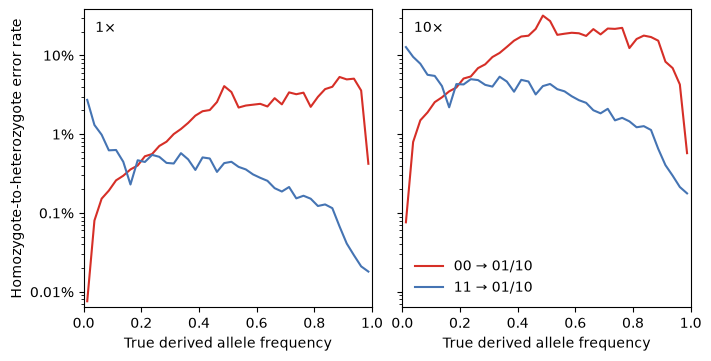

In [193]:
nb_plot.plot_genotype_error_transitions(
    genotype_summary,
    figure_folder=figure_folder,
    config=config,
    figsize=(7, 3.5),
    dpi=300,
    genotype_color_positions=(0.1, 0.9),
    genotype_transition_cmap="RdYlBu",
    transition_multipliers=(1, 10),
    transition_size=(7, 3.5),
)

Confirmation histogram layout: tsinfer 0.4 above, 0.5 below, mirrored
logarithmic counts and common physical overshoot bins. Negative overshoot
means stopping within the true ancestor. Colours run from 0× to 10×.
Each histogram is followed by a separate grouped boxplot. White boxes with
black borders and whiskers overlay sampled jitter within -1 to +1 Mb and
all points outside that interval.
Every point has the same opacity, coloured by version. Dashed caps show the
conf and 1-conf quantiles; the solid black line marks zero. Each comparison
also has two tail panels with separate x ranges for negative and positive
overshoot magnitudes. Each focal site contributes its larger negative and
positive side magnitudes, floored at zero. Fractions count focal sites strictly
above the magnitude cutoff by default. Set fraction_above=False for fractions
at or below the cutoff. All focal sites, including those with zero overshoots,
supply the denominator.

### Genotype-error overshoot summary

Pool both signed focal-site sides for each version and tested multiplier.
A shows the median and IQR; B shows the fraction strictly below -10 Mb.

In [194]:
genotype_overshoot_config = dataclasses.replace(
    config, genotype_multipliers=(0, 1, 2, 5, 10)
)
genotype_overshoot_data = dataclasses.replace(data, config=genotype_overshoot_config)
genotype_summary_multipliers = genotype_overshoot_config.genotype_multipliers
genotype_overshoot_summary = nb_utils.summarise_overshoots(
    nb_utils._genotype_overshoots(data),
    "geno_multiplier",
    genotype_summary_multipliers,
    config,
)

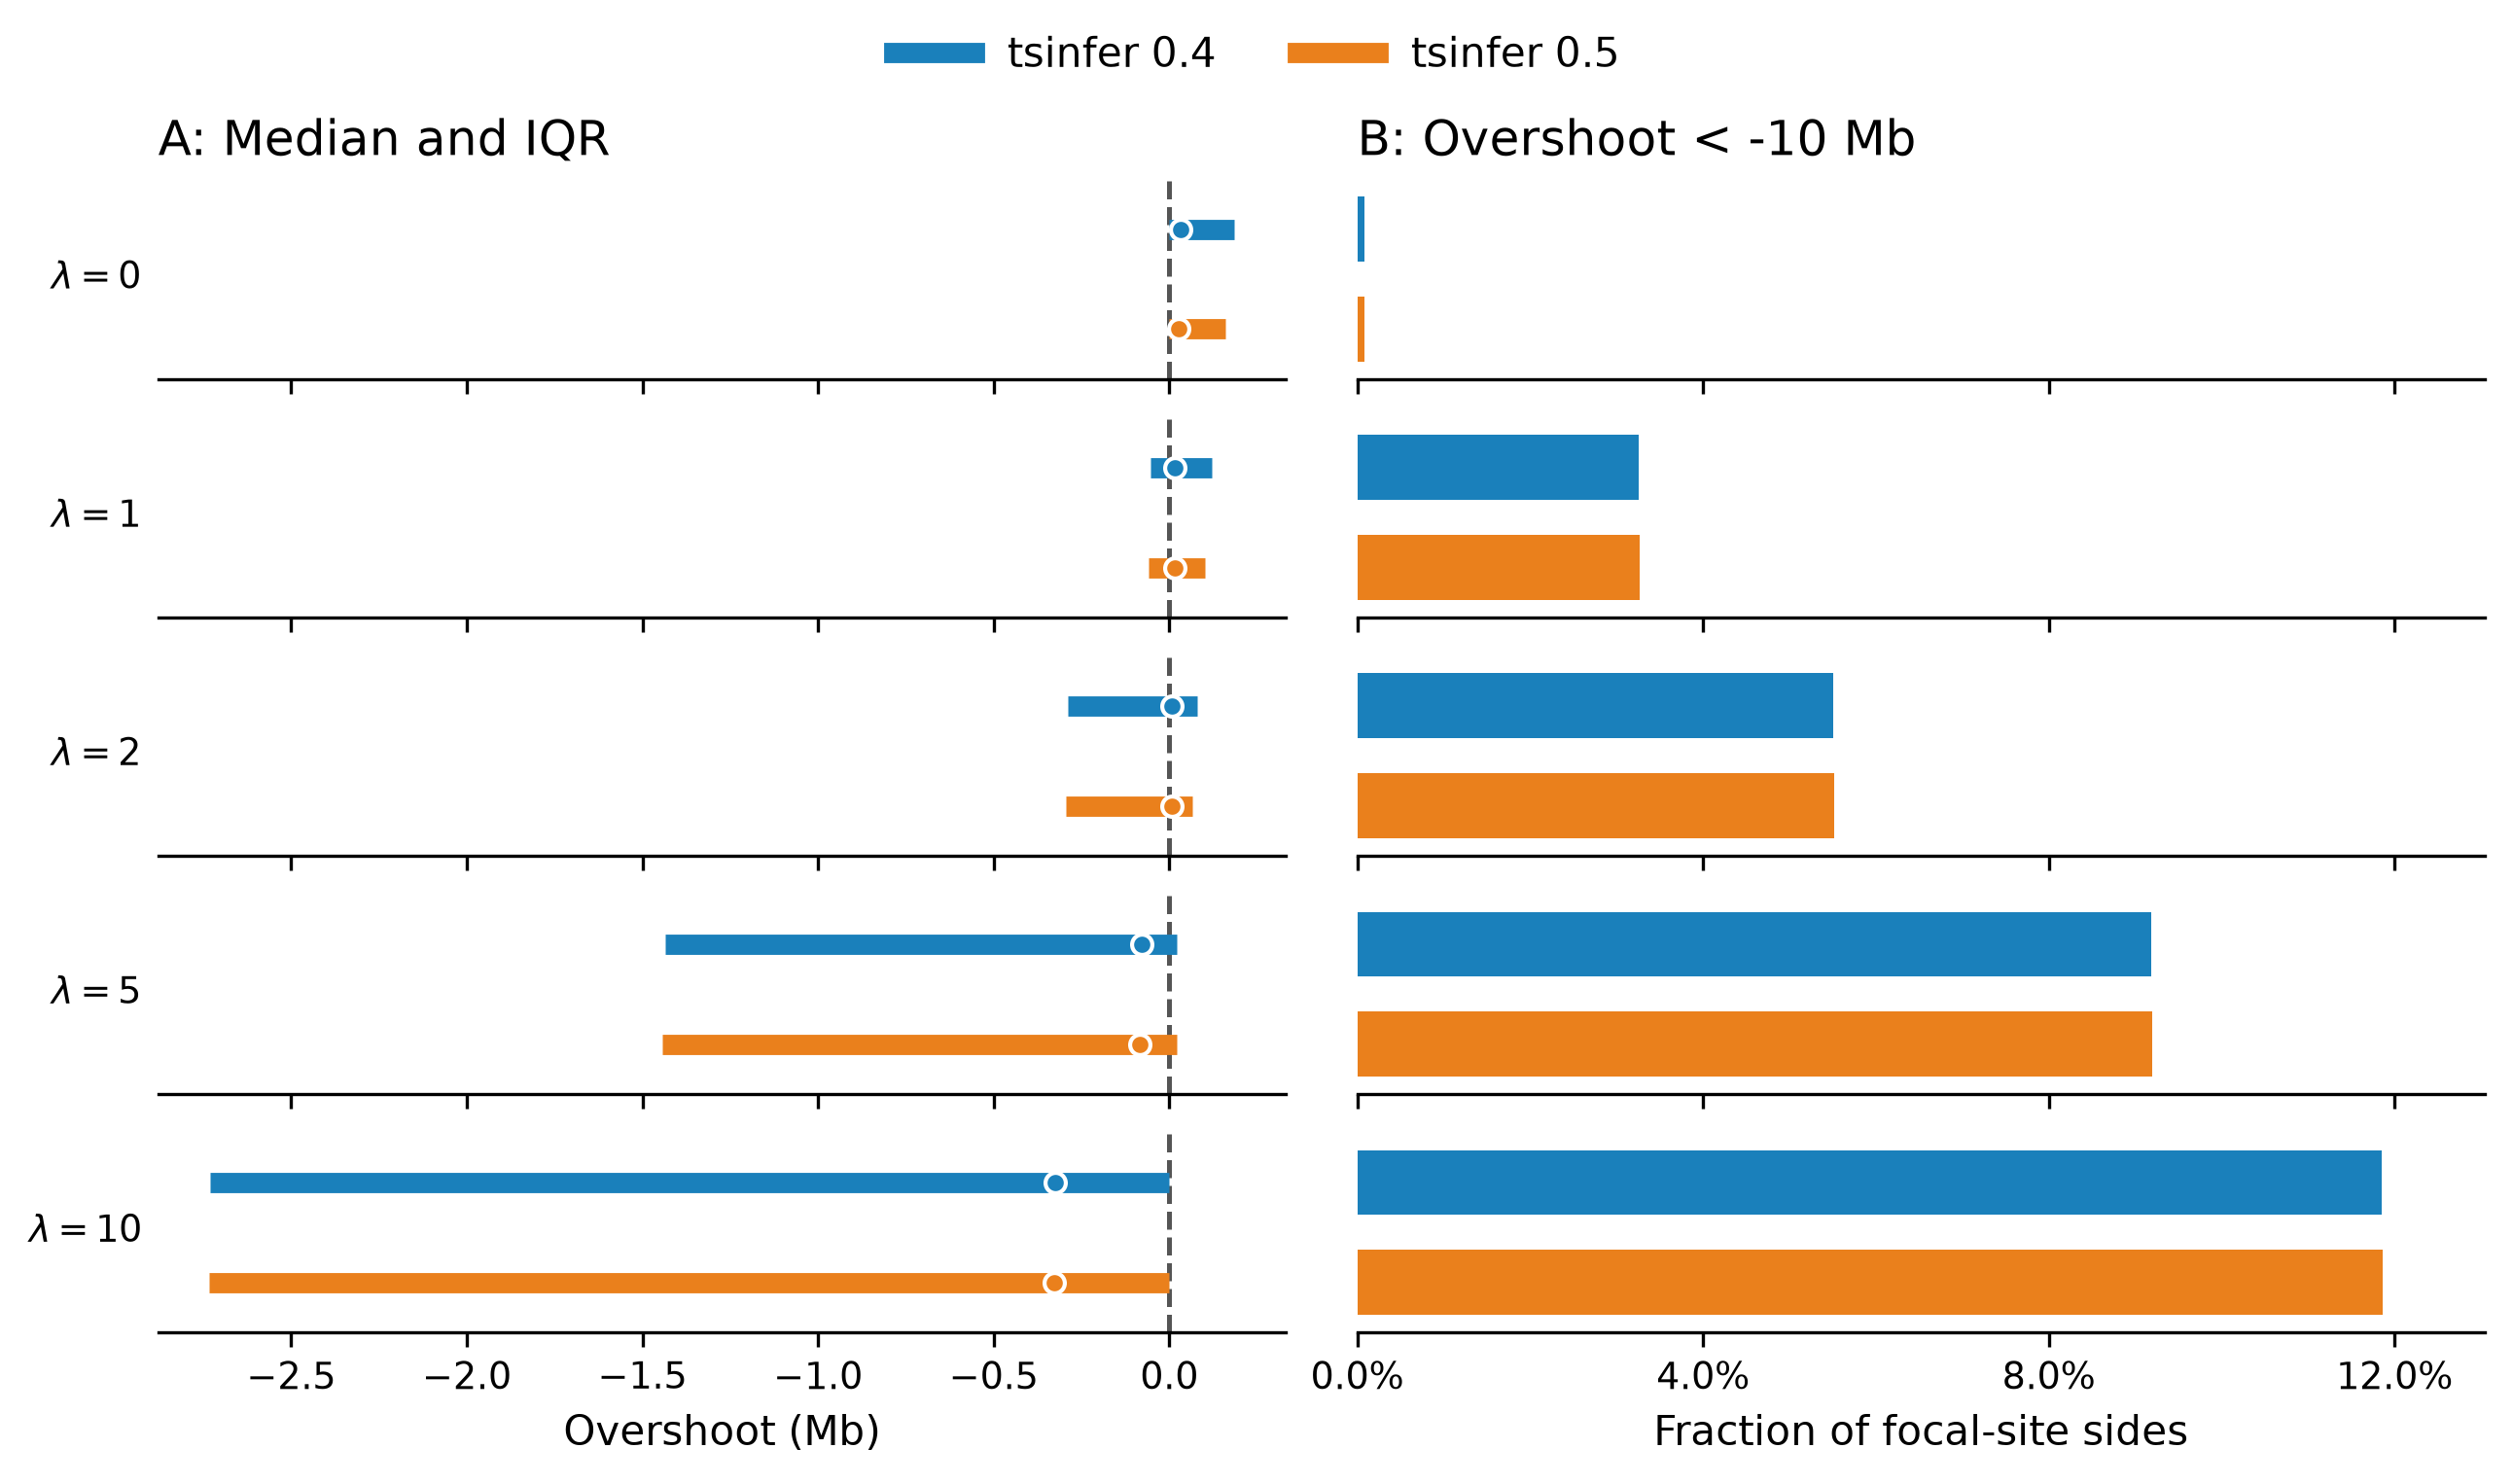

In [ ]:
nb_plot.plot_overshoot_summary(
    genotype_overshoot_summary,
    "geno_multiplier",
    genotype_summary_multipliers,
    {rate: f"$\\lambda = {rate:g}$" for rate in genotype_summary_multipliers},
    "genotype_error_overshoot_summary",
    figure_folder=figure_folder,
    config=config,
    dpi=300,
    overshoot_summary_bar_height=0.65,
    overshoot_summary_fraction_margin=0.1,
    overshoot_summary_fraction_ticks=4,
    overshoot_summary_interval_width=5,
    overshoot_summary_label_fontsize=9,
    overshoot_summary_marker_size=5,
    overshoot_summary_percent_decimals=1,
    overshoot_summary_size=(8.5, 5),
    quantile_line_style="--",
    quantile_line_width=1.2,
    version_colors=("#1a80bb", "#ea801c"),
    zero_color="#555555",
)

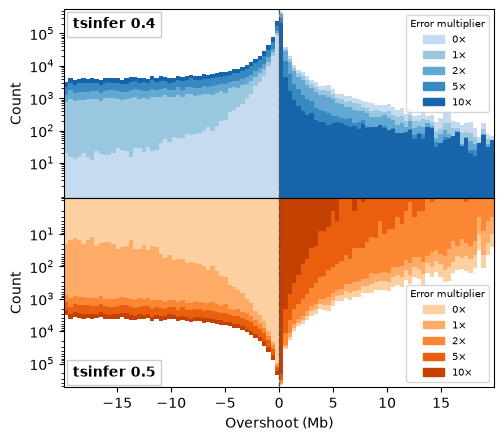

In [196]:
nb_plot.plot_genotype_overshoot_hist(
    genotype_overshoot_data,
    figure_folder=figure_folder,
    figsize=(5, 4.5),
    legend_fontsize=7.5,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    histogram_bins=100,
    histogram_labelled_legend_anchors=((0.04, 1), (0.98, 1)),
    histogram_line_width=1.2,
    histogram_size=(7, 4.5),
    overshoot_cmaps=("Blues", "Oranges"),
    overshoot_diff_panel_gap=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    phase_ser_decimals=2,
    zero_color="#555555",
)

### Overshoot count differences

Top step lines show tsinfer 0.4 counts. Bottom step lines show `100 × (count_0.5 − count_0.4) / count_0.4` on shared bins across versions and error profiles, using the histogram binning
method. Each call explicitly sets `num_bins`; change that argument to tune a particular plot. Panels have equal heights and both increase upwards. The count panel uses a log scale; the signed percentage panel uses symmetric log (linear within ±1%) to retain decreases and zeros. Bins with zero 0.4 count have undefined percentage changes and appear as gaps. Each error profile is counted separately, retaining both focal-site sides. All count-difference plots use equally spaced viridis colours from 0 to 0.8
for their ordered error settings, shared between panels A and B, with a legend
on the right. The genotype and all-frequency mispolarisation comparisons are
exported to the thesis.

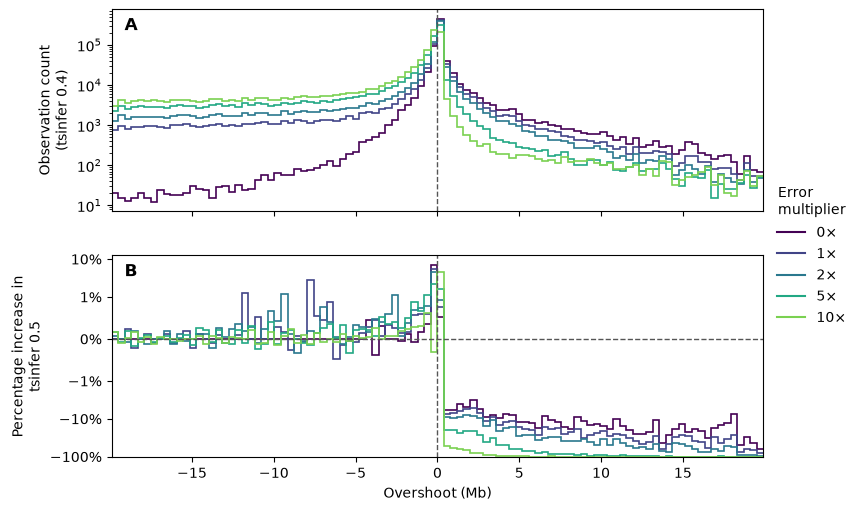

In [199]:
nb_plot.plot_genotype_overshoot_diff(
    genotype_overshoot_data,
    figure_folder=figure_folder,
    num_bins=100,
    figsize=(8.5, 5),
    legend_fontsize=10,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_legend_labels=("No errors", "Combined\nerrors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    histogram_bins=100,
    overshoot_diff_cmap="viridis",
    overshoot_diff_color_range=(0, 0.8),
    overshoot_diff_legend_fontsize=10,
    overshoot_diff_line_width=1.2,
    overshoot_diff_linthresh_pct=1,
    overshoot_diff_panel_gap=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    overshoot_diff_size=(8.5, 5),
    phase_ser_decimals=2,
    zero_color="#555555",
)

### Extreme negative histogram bin

Reconstruct the shared edges from the same selected profiles and bin count
as each histogram. Counts include both sides per focal site. The leftmost
bin includes its left edge and excludes its right edge. Percentages use all
focal-site sides in the same error profile and version as the denominator.

In [200]:
genotype_leftmost_bin = nb_utils.summarise_leftmost_overshoot_bin(
    nb_utils._genotype_overshoots(genotype_overshoot_data),
    "geno_multiplier",
    genotype_overshoot_config.genotype_multipliers,
    config=config,
    histogram_bins=100,
)
ipd.display(genotype_leftmost_bin)
genotype_leftmost_bin_comparison = genotype_leftmost_bin[
    ["num_sides_in_leftmost_bin", "percentage_in_leftmost_bin"]
].unstack("version")
ipd.display(
    genotype_leftmost_bin_comparison.style.format(
        {
            ("num_sides_in_leftmost_bin", version): "{:,.0f}"
            for version in config.versions
        }
    ).format(
        {
            ("percentage_in_leftmost_bin", version): "{:.6f}%"
            for version in config.versions
        }
    )
)

left_edge_bp  right_edge_bp  bin_width_bp  \
geno_multiplier version                                              
0               0.4.1     -19916367.0   -19518057.38     398309.62   
                0.5.1     -19916367.0   -19518057.38     398309.62   
1               0.4.1     -19916367.0   -19518057.38     398309.62   
                0.5.1     -19916367.0   -19518057.38     398309.62   
2               0.4.1     -19916367.0   -19518057.38     398309.62   
                0.5.1     -19916367.0   -19518057.38     398309.62   
5               0.4.1     -19916367.0   -19518057.38     398309.62   
                0.5.1     -19916367.0   -19518057.38     398309.62   
10              0.4.1     -19916367.0   -19518057.38     398309.62   
                0.5.1     -19916367.0   -19518057.38     398309.62   

                         num_sides_in_leftmost_bin  total_num_sides  \
geno_multiplier version                                               
0               0.4.1                           20           716570   
                0.5.1                           20           716570   
1               0.4.1                          757           745458   
                0.5.1                          757           745458   
2               0.4.1                         1291           767652   
                0.5.1                         1292           767652   
5               0.4.1                         2261           812202   
                0.5.1                         2265           812202   
10              0.4.1                         3086           867948   
                0.5.1                         3091           867948   

                         percentage_in_leftmost_bin  
geno_multiplier version                              
0               0.4.1                      0.002791  
                0.5.1                      0.002791  
1               0.4.1                      0.101548  
                0.5.1                      0.101548  
2               0.4.1                      0.168175  
                0.5.1                      0.168305  
5               0.4.1                      0.278379  
                0.5.1                      0.278872  
10              0.4.1                      0.355551  
                0.5.1                      0.356127

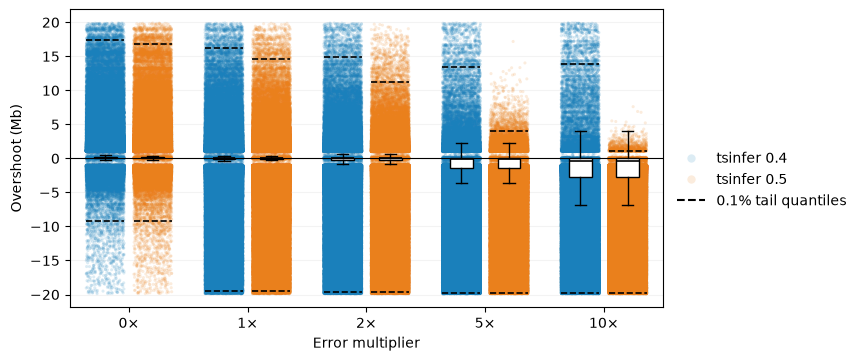

In [201]:
nb_plot.plot_genotype_overshoot_box(
    genotype_overshoot_data,
    figure_folder=figure_folder,
    conf=0.001,
    figsize=(8.5, 3.5),
    y_log=False,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    jitter_alpha=0.15,
    jitter_max_points=1500,
    jitter_sample_interval_mb=(-1, 1),
    jitter_seed=42,
    jitter_size=5,
    jitter_width=0.32,
    overshoot_box_size=(8.5, 3.5),
    overshoot_box_width_ratio=0.6,
    overshoot_linthresh_bp=1000,
    phase_ser_decimals=2,
    quantile_line_style="--",
    quantile_line_width=1.2,
    quantile_secondary_color="#555555",
    quantile_secondary_line_style="-.",
    version_colors=("#1a80bb", "#ea801c"),
)

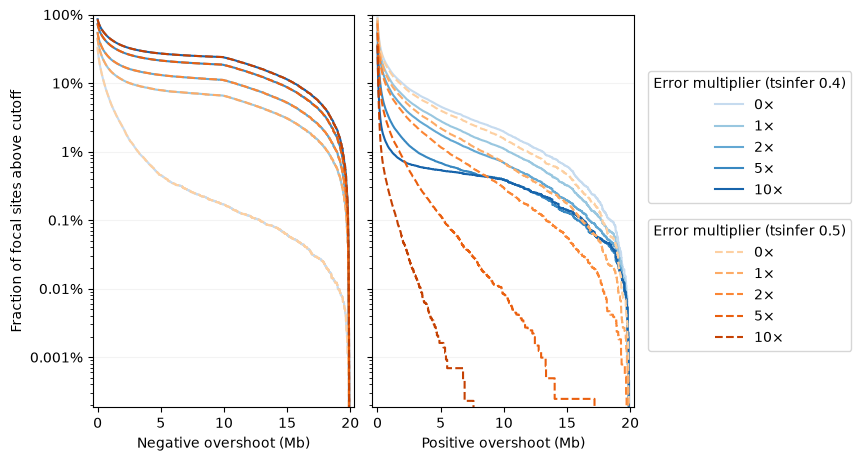

In [202]:
nb_plot.plot_genotype_overshoot_tails(
    genotype_overshoot_data,
    figure_folder=figure_folder,
    figsize=(8.5, 4.5),
    fraction_above=True,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    mean_bar_group_width=0.8,
    overshoot_cmaps=("Blues", "Oranges"),
    overshoot_tail_size=(8.5, 4.5),
    phase_ser_decimals=2,
    tail_count_height_ratio=0.28,
    tail_legend_gap=0.04,
    tail_legend_width_ratio=0.75,
    version_colors=("#1a80bb", "#ea801c"),
    version_line_styles=("-", "--"),
)

## Mispolarisation errors

DAF is flipped at sites whose `variant_mispolarisation_mask` is False. Curves
show absolute site counts in 200 equal-width bins, smoothed by a Gaussian
kernel with a one-bin standard deviation. This keeps regeneration practical
for larger datasets. Counts are pooled across replicates.
Singletons are included and eligible for mispolarisation. Reconstruct the
segregating-site spectrum from current focal records and exported truth counts.
Simulation and empirical curves share one set of axes, bins and smoothing.
Counts are absolute: the simulation pools replicates and has 12,000 haplotypes;
TGP has 6,404 haplotypes from all 3,202 individuals.

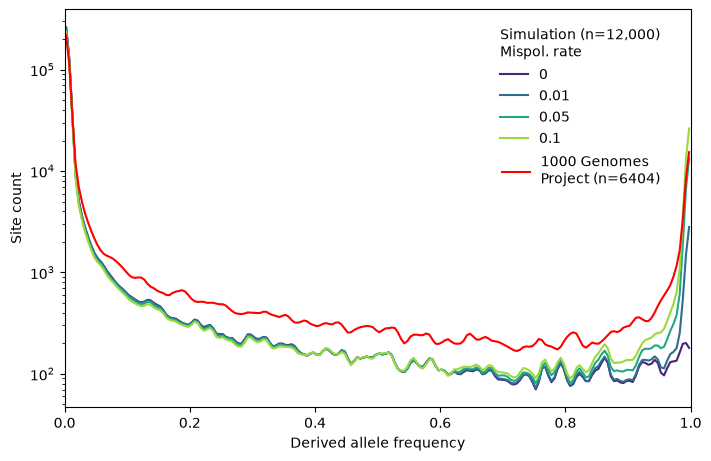

Prepared thesis export: mispolarisation_daf.png


In [2]:
simulation_daf_counts = nb_utils.mispolarisation_daf_counts(data)
tgp_variants = nb_utils.load_tgp_daf(tgp_zarr_path, config=config)
nb_plot.plot_mispolarisation_daf(
    data,
    frequencies=simulation_daf_counts,
    figure_folder=figure_folder,
    tgp_variants=tgp_variants,
    figsize=(7, 4.5),
    combined_daf_legend_fontsize=10,
    combined_daf_legend_x=0.96,
    combined_daf_simulation_legend_y=0.97,
    combined_daf_size=(7, 4.5),
    combined_daf_tgp_legend_y=0.65,
    combined_tgp_legend_label="1000 Genomes\nProject (n=6404)",
    daf_bins=200,
    daf_size=(5, 4.5),
    daf_smoothing_bins=1,
    dpi=300,
    simulation_daf_legend_label="Simulation (n=12,000)",
    tgp_color="red",
)

### TGP: first 20 Mbp of chromosome 20

No variant filters or masks are applied within the region. Stored all-sample
derived counts are already polarised; divide by ancestral plus derived counts
to use called alleles as the denominator.
This is the recorded TGP spectrum, with no additional simulated mispolarisation.

In [4]:
tgp_variants = nb_utils.load_tgp_daf(tgp_zarr_path, config=config)
print(f"TGP variants in region: {len(tgp_variants):,}")
print(f"Retained derived singletons: {(tgp_variants.derived_count == 1).sum():,}")

TGP variants in region: 507,063
Retained derived singletons: 0


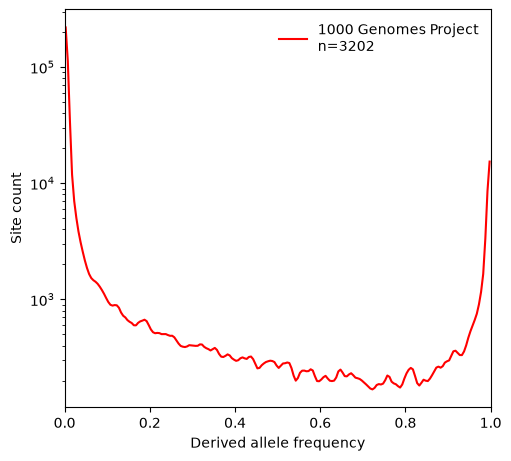

Prepared thesis export: tgp_daf.png


In [5]:
# Standalone empirical diagnostic; the thesis uses the combined axes above.
nb_plot.plot_tgp_daf(
    tgp_variants,
    figure_folder=figure_folder,
    config=config,
    figsize=(5, 4.5),
    daf_bins=200,
    daf_size=(5, 4.5),
    daf_smoothing_bins=1,
    dpi=300,
    tgp_color="red",
    tgp_legend_label="1000 Genomes Project\nn=3202",
)

Overshoot plots use true focal DAF from the error-free variant store, with
0.5 included only in the high-frequency figure. The all-frequency plots pool
high and low DAFs. Pure mispolarisation profiles include the error-free
reference; mixed error profiles are excluded. The exported all-frequency diff
uses only correctly polarised focal sites. The second exported histogram uses
all mispolarised focal sites without a DAF or derived-count filter. Exported
filenames distinguish correctly polarised and flipped focal sites.

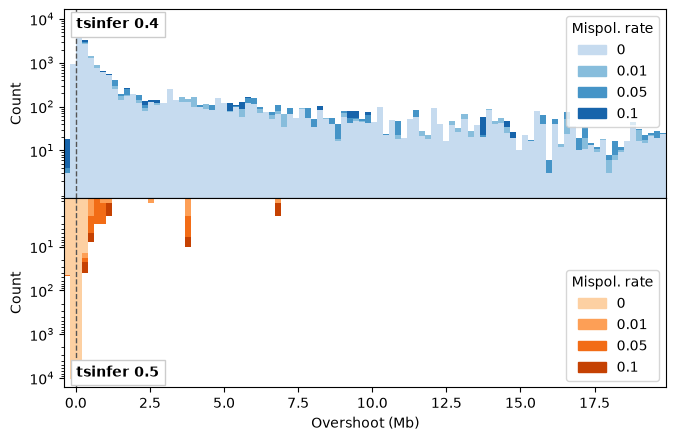

In [3]:
nb_plot.plot_mispolarisation_overshoot_hist(
    data,
    figure_folder=figure_folder,
    frequency="high",
    figsize=(7, 4.5),
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    histogram_bins=100,
    histogram_labelled_legend_anchors=((0.04, 1), (0.98, 1)),
    histogram_line_width=1.2,
    histogram_size=(7, 4.5),
    overshoot_cmaps=("Blues", "Oranges"),
    overshoot_diff_panel_gap=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    phase_ser_decimals=2,
    zero_color="#555555",
)

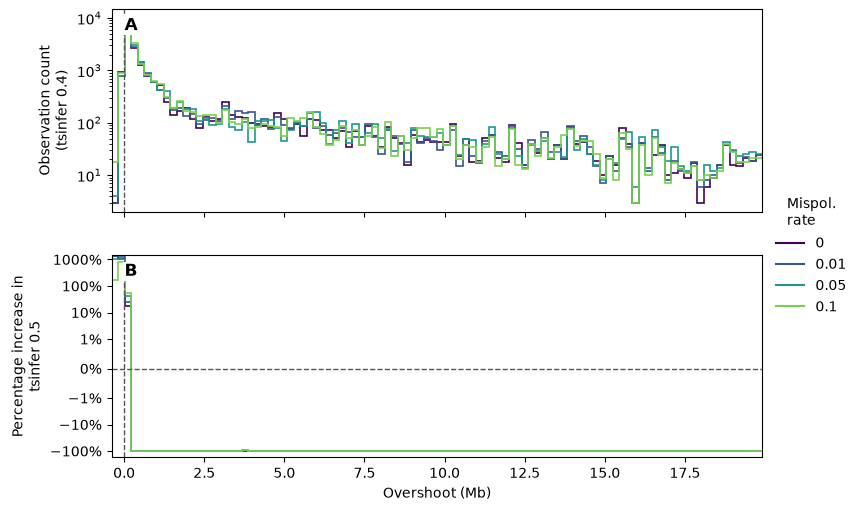

In [6]:
nb_plot.plot_mispolarisation_overshoot_diff(
    data,
    figure_folder=figure_folder,
    num_bins=100,
    frequency="high",
    figsize=(8.5, 5),
    legend_fontsize=10,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_legend_labels=("No errors", "Combined\nerrors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    histogram_bins=100,
    overshoot_diff_cmap="viridis",
    overshoot_diff_color_range=(0, 0.8),
    overshoot_diff_legend_fontsize=10,
    overshoot_diff_line_width=1.2,
    overshoot_diff_linthresh_pct=1,
    overshoot_diff_panel_gap=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    overshoot_diff_size=(8.5, 5),
    phase_ser_decimals=2,
    zero_color="#555555",
)

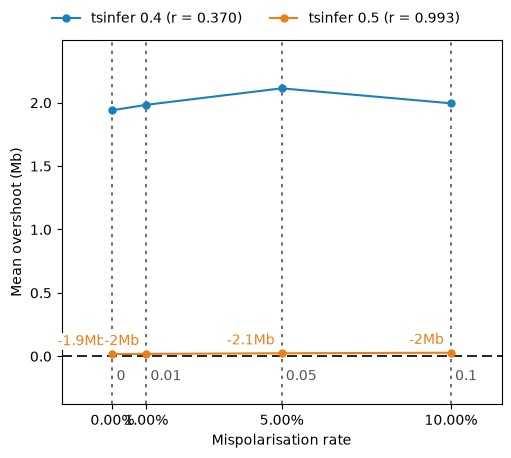

In [3]:
nb_plot.plot_mispolarisation_overshoot_scatter(
    data,
    figure_folder=figure_folder,
    frequency="high",
    figsize=(5, 4.5),
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    genotype_scatter_connector_width=0.8,
    genotype_scatter_error_change_offset=(-5, -4),
    mean_change_decimals=1,
    overshoot_diff_line_width=1.2,
    overshoot_scatter_change_fontsize=10,
    overshoot_scatter_change_offset=(-5, 4),
    overshoot_scatter_correlation_decimals=3,
    overshoot_scatter_guide_depth=0.05,
    overshoot_scatter_label_fontsize=10,
    overshoot_scatter_label_padding=3,
    overshoot_scatter_marker_size=5,
    overshoot_scatter_size=(5, 4.5),
    overshoot_scatter_tick_decimals=2,
    overshoot_scatter_vertical_dash=(0, (2, 3)),
    overshoot_scatter_x_margin=0.15,
    overshoot_scatter_y_margin=0.18,
    overshoot_scatter_zero_dash=(0, (6, 3)),
    phase_scatter_change_offset=(-5, 4),
    phase_scatter_guide_depth=0.2,
    phase_ser_decimals=2,
    version_colors=("#1a80bb", "#ea801c"),
    zero_color="#555555",
)

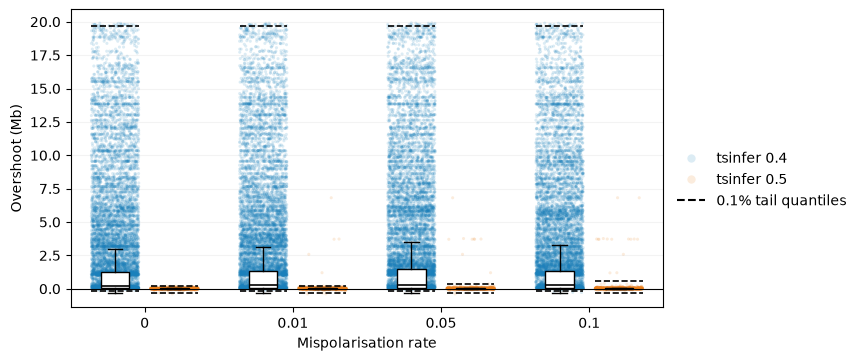

In [6]:
nb_plot.plot_mispolarisation_overshoot_box(
    data,
    figure_folder=figure_folder,
    frequency="high",
    conf=0.001,
    figsize=(8.5, 3.5),
    y_log=False,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    jitter_alpha=0.15,
    jitter_max_points=1500,
    jitter_sample_interval_mb=(-1, 1),
    jitter_seed=42,
    jitter_size=5,
    jitter_width=0.32,
    overshoot_box_size=(8.5, 3.5),
    overshoot_box_width_ratio=0.6,
    overshoot_linthresh_bp=1000,
    phase_ser_decimals=2,
    quantile_line_style="--",
    quantile_line_width=1.2,
    quantile_secondary_color="#555555",
    quantile_secondary_line_style="-.",
    version_colors=("#1a80bb", "#ea801c"),
)

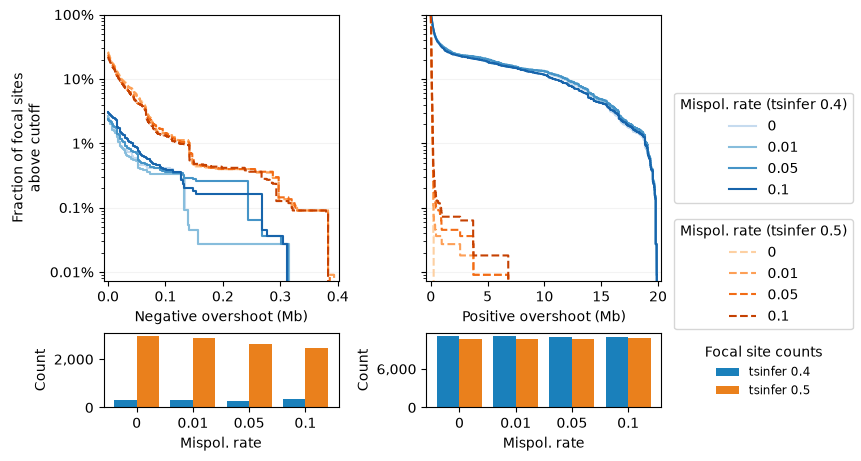

In [79]:
nb_plot.plot_mispolarisation_overshoot_tails(
    data,
    figure_folder=figure_folder,
    frequency="high",
    figsize=(8.5, 4.5),
    show_counts=True,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    mean_bar_group_width=0.8,
    overshoot_cmaps=("Blues", "Oranges"),
    overshoot_tail_size=(8.5, 4.5),
    phase_ser_decimals=2,
    tail_count_height_ratio=0.28,
    tail_legend_gap=0.04,
    tail_legend_width_ratio=0.75,
    version_colors=("#1a80bb", "#ea801c"),
    version_line_styles=("-", "--"),
)

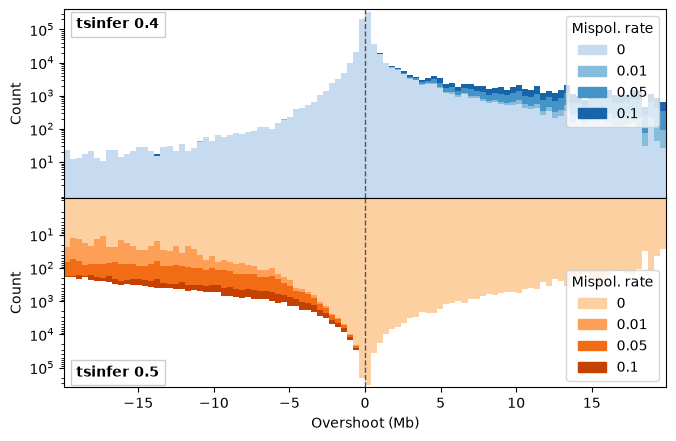

In [4]:
nb_plot.plot_mispolarisation_overshoot_hist(
    data,
    figure_folder=figure_folder,
    frequency="low",
    figsize=(7, 4.5),
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    histogram_bins=100,
    histogram_labelled_legend_anchors=((0.04, 1), (0.98, 1)),
    histogram_line_width=1.2,
    histogram_size=(7, 4.5),
    overshoot_cmaps=("Blues", "Oranges"),
    overshoot_diff_panel_gap=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    phase_ser_decimals=2,
    zero_color="#555555",
)

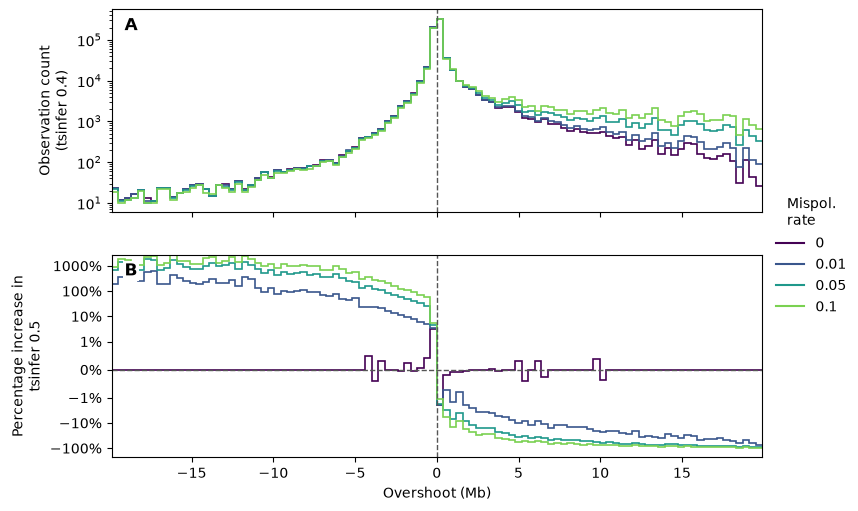

In [7]:
nb_plot.plot_mispolarisation_overshoot_diff(
    data,
    figure_folder=figure_folder,
    num_bins=100,
    frequency="low",
    figsize=(8.5, 5),
    legend_fontsize=10,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_legend_labels=("No errors", "Combined\nerrors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    histogram_bins=100,
    overshoot_diff_cmap="viridis",
    overshoot_diff_color_range=(0, 0.8),
    overshoot_diff_legend_fontsize=10,
    overshoot_diff_line_width=1.2,
    overshoot_diff_linthresh_pct=1,
    overshoot_diff_panel_gap=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    overshoot_diff_size=(8.5, 5),
    phase_ser_decimals=2,
    zero_color="#555555",
)

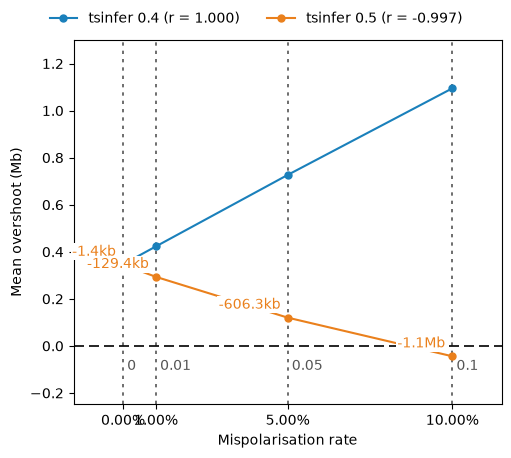

In [4]:
nb_plot.plot_mispolarisation_overshoot_scatter(
    data,
    figure_folder=figure_folder,
    frequency="low",
    figsize=(5, 4.5),
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    genotype_scatter_connector_width=0.8,
    genotype_scatter_error_change_offset=(-5, -4),
    mean_change_decimals=1,
    overshoot_diff_line_width=1.2,
    overshoot_scatter_change_fontsize=10,
    overshoot_scatter_change_offset=(-5, 4),
    overshoot_scatter_correlation_decimals=3,
    overshoot_scatter_guide_depth=0.05,
    overshoot_scatter_label_fontsize=10,
    overshoot_scatter_label_padding=3,
    overshoot_scatter_marker_size=5,
    overshoot_scatter_size=(5, 4.5),
    overshoot_scatter_tick_decimals=2,
    overshoot_scatter_vertical_dash=(0, (2, 3)),
    overshoot_scatter_x_margin=0.15,
    overshoot_scatter_y_margin=0.18,
    overshoot_scatter_zero_dash=(0, (6, 3)),
    phase_scatter_change_offset=(-5, 4),
    phase_scatter_guide_depth=0.2,
    phase_ser_decimals=2,
    version_colors=("#1a80bb", "#ea801c"),
    zero_color="#555555",
)

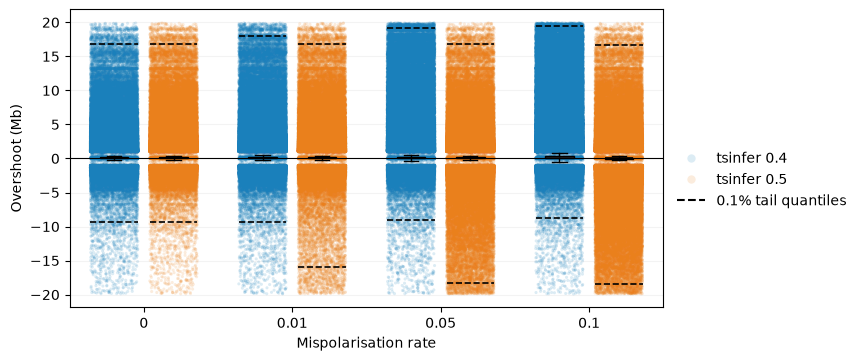

In [7]:
nb_plot.plot_mispolarisation_overshoot_box(
    data,
    figure_folder=figure_folder,
    frequency="low",
    conf=0.001,
    figsize=(8.5, 3.5),
    y_log=False,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    jitter_alpha=0.15,
    jitter_max_points=1500,
    jitter_sample_interval_mb=(-1, 1),
    jitter_seed=42,
    jitter_size=5,
    jitter_width=0.32,
    overshoot_box_size=(8.5, 3.5),
    overshoot_box_width_ratio=0.6,
    overshoot_linthresh_bp=1000,
    phase_ser_decimals=2,
    quantile_line_style="--",
    quantile_line_width=1.2,
    quantile_secondary_color="#555555",
    quantile_secondary_line_style="-.",
    version_colors=("#1a80bb", "#ea801c"),
)

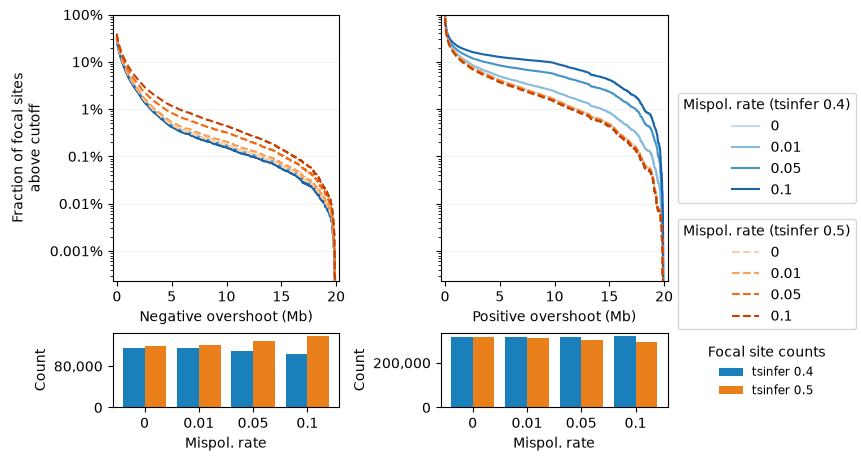

In [84]:
nb_plot.plot_mispolarisation_overshoot_tails(
    data,
    figure_folder=figure_folder,
    frequency="low",
    figsize=(8.5, 4.5),
    show_counts=True,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    mean_bar_group_width=0.8,
    overshoot_cmaps=("Blues", "Oranges"),
    overshoot_tail_size=(8.5, 4.5),
    phase_ser_decimals=2,
    tail_count_height_ratio=0.28,
    tail_legend_gap=0.04,
    tail_legend_width_ratio=0.75,
    version_colors=("#1a80bb", "#ea801c"),
    version_line_styles=("-", "--"),
)

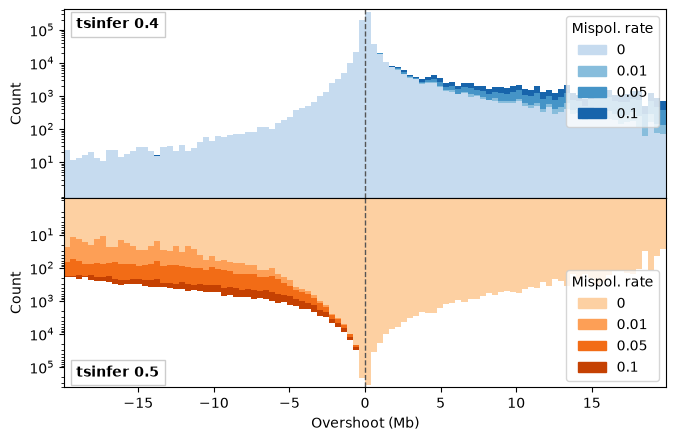

In [5]:
nb_plot.plot_mispolarisation_overshoot_hist(
    data,
    figure_folder=figure_folder,
    frequency="all",
    figsize=(7, 4.5),
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    histogram_bins=100,
    histogram_labelled_legend_anchors=((0.04, 1), (0.98, 1)),
    histogram_line_width=1.2,
    histogram_size=(7, 4.5),
    overshoot_cmaps=("Blues", "Oranges"),
    overshoot_diff_panel_gap=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    phase_ser_decimals=2,
    zero_color="#555555",
)

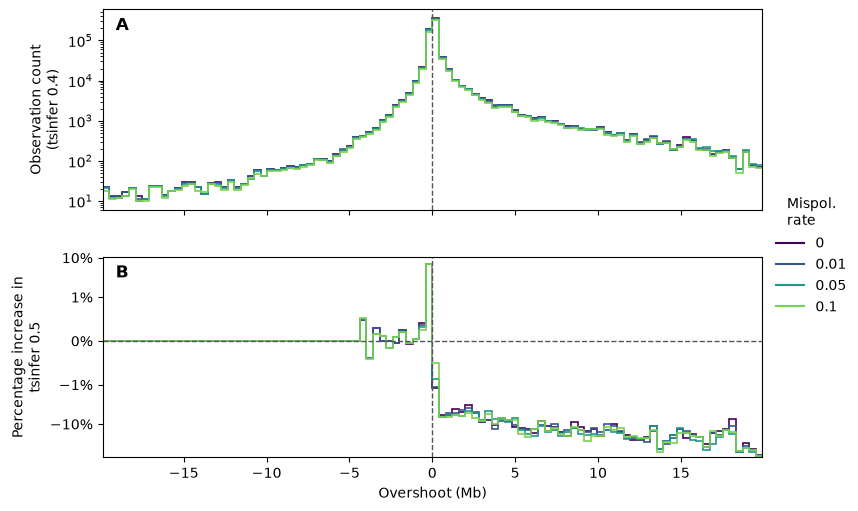

In [8]:
nb_plot.plot_mispolarisation_overshoot_diff(
    data,
    focal_site_mispolarised=False,
    figure_folder=figure_folder,
    num_bins=100,
    frequency="all",
    figsize=(8.5, 5),
    legend_fontsize=10,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_legend_labels=("No errors", "Combined\nerrors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    histogram_bins=100,
    overshoot_diff_cmap="viridis",
    overshoot_diff_color_range=(0, 0.8),
    overshoot_diff_legend_fontsize=10,
    overshoot_diff_line_width=1.2,
    overshoot_diff_linthresh_pct=1,
    overshoot_diff_panel_gap=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    overshoot_diff_size=(8.5, 5),
    phase_ser_decimals=2,
    zero_color="#555555",
)

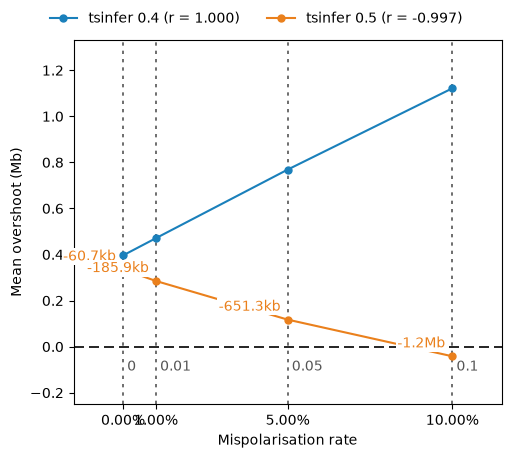

In [5]:
nb_plot.plot_mispolarisation_overshoot_scatter(
    data,
    figure_folder=figure_folder,
    frequency="all",
    figsize=(5, 4.5),
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    genotype_scatter_connector_width=0.8,
    genotype_scatter_error_change_offset=(-5, -4),
    mean_change_decimals=1,
    overshoot_diff_line_width=1.2,
    overshoot_scatter_change_fontsize=10,
    overshoot_scatter_change_offset=(-5, 4),
    overshoot_scatter_correlation_decimals=3,
    overshoot_scatter_guide_depth=0.05,
    overshoot_scatter_label_fontsize=10,
    overshoot_scatter_label_padding=3,
    overshoot_scatter_marker_size=5,
    overshoot_scatter_size=(5, 4.5),
    overshoot_scatter_tick_decimals=2,
    overshoot_scatter_vertical_dash=(0, (2, 3)),
    overshoot_scatter_x_margin=0.15,
    overshoot_scatter_y_margin=0.18,
    overshoot_scatter_zero_dash=(0, (6, 3)),
    phase_scatter_change_offset=(-5, 4),
    phase_scatter_guide_depth=0.2,
    phase_ser_decimals=2,
    version_colors=("#1a80bb", "#ea801c"),
    zero_color="#555555",
)

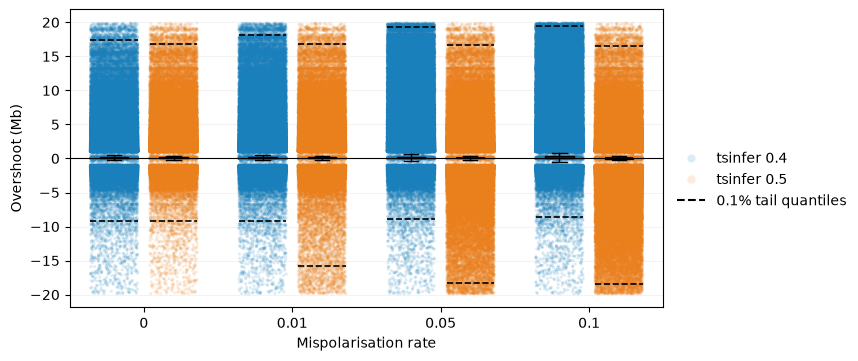

In [8]:
nb_plot.plot_mispolarisation_overshoot_box(
    data,
    figure_folder=figure_folder,
    frequency="all",
    conf=0.001,
    figsize=(8.5, 3.5),
    y_log=False,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    jitter_alpha=0.15,
    jitter_max_points=1500,
    jitter_sample_interval_mb=(-1, 1),
    jitter_seed=42,
    jitter_size=5,
    jitter_width=0.32,
    overshoot_box_size=(8.5, 3.5),
    overshoot_box_width_ratio=0.6,
    overshoot_linthresh_bp=1000,
    phase_ser_decimals=2,
    quantile_line_style="--",
    quantile_line_width=1.2,
    quantile_secondary_color="#555555",
    quantile_secondary_line_style="-.",
    version_colors=("#1a80bb", "#ea801c"),
)

### Mispolarisation overshoot across all frequencies

Combine variants without splitting by true DAF. Keep the same
negative/positive tail curves and focal-site count
bars, pooling the underlying observations across both frequency groups.
The all-frequency diff plot above is exported to the thesis; these tail curves remain local.

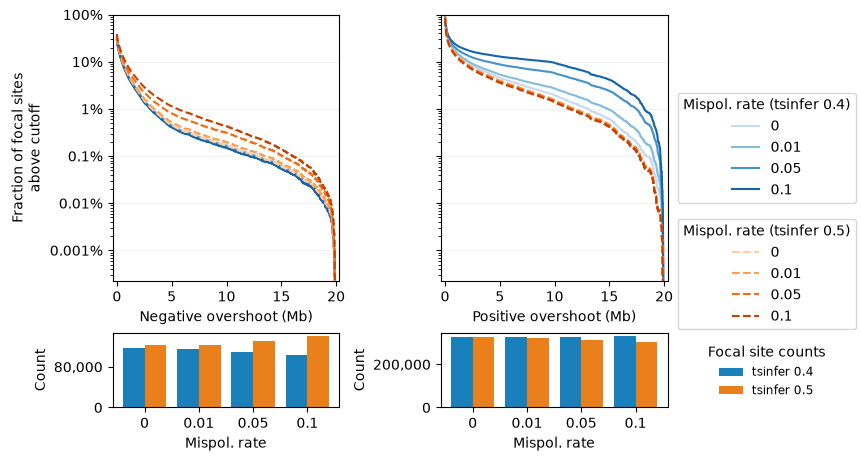

In [89]:
nb_plot.plot_mispolarisation_overshoot_tails(
    data,
    figure_folder=figure_folder,
    frequency="all",
    figsize=(8.5, 4.5),
    show_counts=True,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    mean_bar_group_width=0.8,
    overshoot_cmaps=("Blues", "Oranges"),
    overshoot_tail_size=(8.5, 4.5),
    phase_ser_decimals=2,
    tail_count_height_ratio=0.28,
    tail_legend_gap=0.04,
    tail_legend_width_ratio=0.75,
    version_colors=("#1a80bb", "#ea801c"),
    version_line_styles=("-", "--"),
)

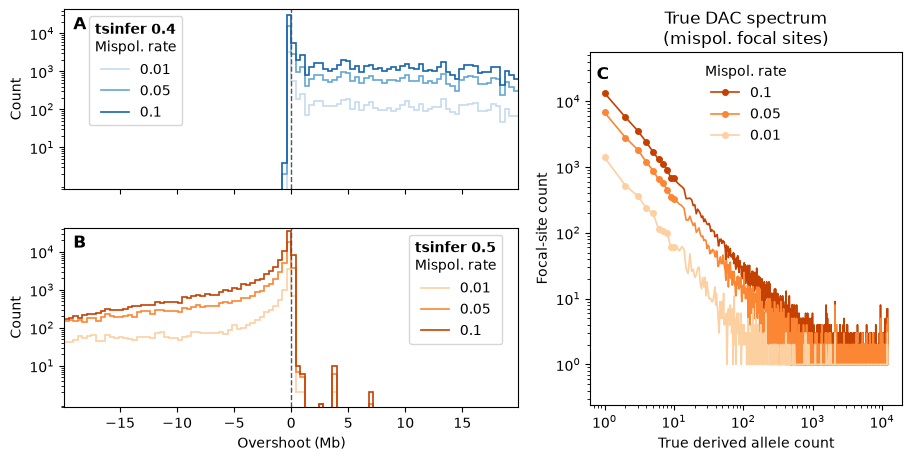

Prepared thesis export: mispolarisation_overshoot_flipped_focal_hist.png


In [2]:
# Narrow overshoot panels retain the blue/orange rate palettes. Panel C plots
# the full true DAC spectrum with straight lines joining occupied integer bins
# and markers only at AC 1–10, on log x and y axes using the tsinfer 0.5 palette.
# Rates are drawn largest first.
nb_plot.plot_mispolarised_focal_overshoot_hist(
    data,
    figure_folder=figure_folder,
    figsize=(9, 4.5),
    ancestor_error_version="0.5.1",
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    histogram_bins=100,
    histogram_labelled_legend_anchors=((0.04, 1), (0.98, 1)),
    histogram_line_width=1.2,
    histogram_size=(7, 4.5),
    mispolarised_focal_dac_marker="o",
    mispolarised_focal_dac_marker_max_count=10,
    mispolarised_focal_dac_marker_size=4,
    mispolarised_focal_dac_title="True DAC spectrum\n(mispol. focal sites)",
    mispolarised_focal_dac_y_margin=0.15,
    mispolarised_focal_size=(9, 4.5),
    mispolarised_focal_width_ratios=(0.58, 0.42),
    overshoot_cmaps=("Blues", "Oranges"),
    overshoot_diff_panel_gap=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    phase_ser_decimals=2,
    zero_color="#555555",
)

True singleton and doubleton counts among all mispolarised focal sites at
each rate, using the same tsinfer 0.5 cohort as panel C. Each focal is counted
once; proportions use all mispolarised focal sites at that rate as denominator.

In [3]:
mispolarised_focal_count_table = nb_utils.summarise_mispolarised_focal_counts(
    data, ancestor_error_version="0.5.1"
)
ipd.display(
    mispolarised_focal_count_table.style.format(
        {
            "mispol_rate": "{:g}",
            "num_mispol_focal_sites": "{:,.0f}",
            "num_true_singletons": "{:,.0f}",
            "num_true_doubletons": "{:,.0f}",
            "proportion_true_singletons": "{:.3%}",
            "proportion_true_doubletons": "{:.3%}",
        }
    )
)

,mispol_rate,num_mispol_focal_sites,num_true_singletons,proportion_true_singletons,num_true_doubletons,proportion_true_doubletons
0,0.01,"4,937","1,400",28.357%,524,10.614%
1,0.05,"24,735","6,772",27.378%,"2,810",11.360%
2,0.1,"49,266","13,362",27.122%,"5,726",11.623%


### Haplotype accuracy by focal-site polarisation

Use the usual whole-overlap error panels, comparing no mispolarisation with
rates 0.01 and 0.1, each split into non-mispolarised then mispolarised focal
sites, with each pair bracketed by its dataset mispolarisation rate. Each
focal site contributes one overlap; errors and compared inference sites are pooled before division.
Truth is already recoded to the observed polarisation by tsinfer-anc-eval.

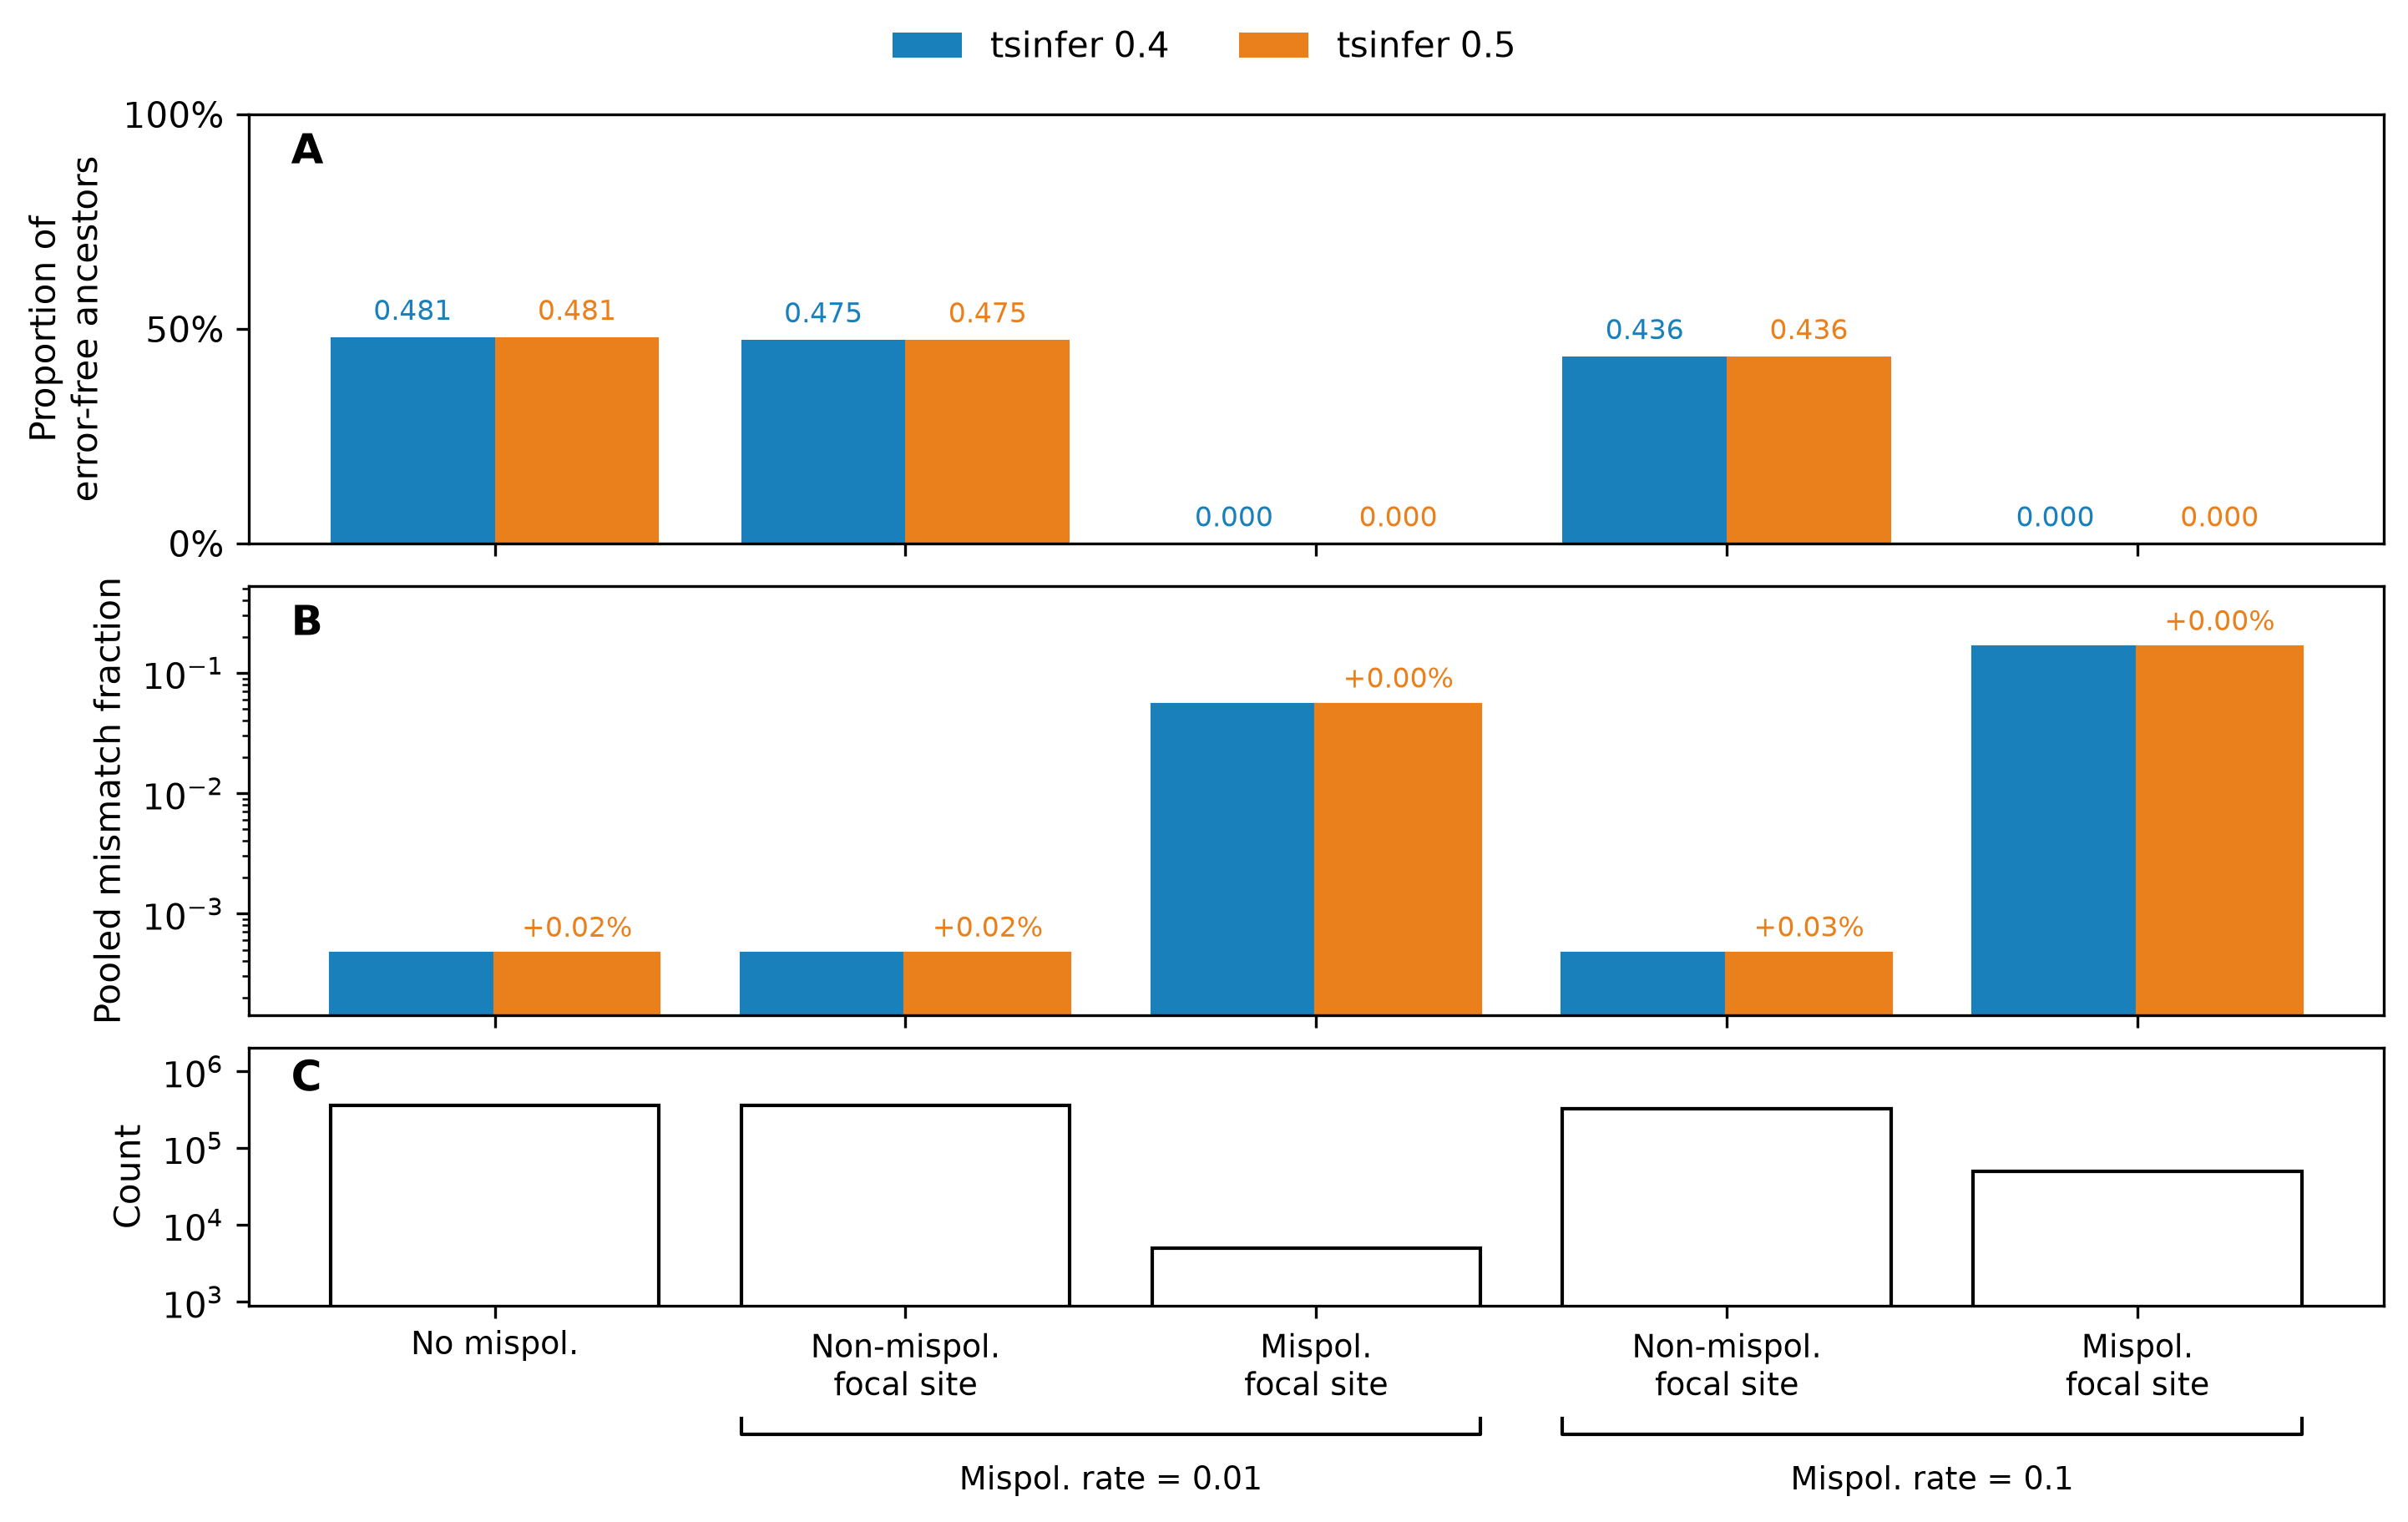

In [ ]:
mispolarisation_overlap_comparisons = nb_utils.load_mispolarisation_overlap_errors(
    aggregated_path, config=config, mispolarisation_error_rates=(0.01, 0.1)
)
mispolarisation_overlap_summary = nb_utils.summarise_mispolarisation_overlap_errors(
    mispolarisation_overlap_comparisons
)
nb_plot.plot_mispolarisation_overlap_errors(
    mispolarisation_overlap_summary,
    figure_folder=figure_folder,
    config=config,
    ancestor_error_change_decimals=2,
    ancestor_error_count_margin=0.4,
    ancestor_error_hatch="///",
    ancestor_error_height_ratios=(1, 1, 0.6),
    ancestor_error_label_decimals=3,
    ancestor_error_label_fontsize=8,
    ancestor_error_label_padding=3,
    ancestor_error_legend_fontsize=9,
    ancestor_error_log_numticks=6,
    ancestor_error_log_subs=(1, 2, 5),
    ancestor_error_size=(7, 5.4),
    ancestor_error_type_labels=("True = 0, Observed = 1", "True = 1, Observed = 0"),
    ancestor_error_y_log=True,
    ancestor_mismatch_fraction_label_margin=0.2,
    dpi=300,
    mean_bar_group_width=0.8,
    mispolarisation_error_bracket_depth=0.06,
    mispolarisation_error_bracket_y=-0.5,
    mispolarisation_error_group_fontsize=9,
    mispolarisation_error_log_subs=(1,),
    mispolarisation_error_rate_label_y=-0.62,
    mispolarisation_error_rates=(0.01, 0.1),
    mispolarisation_error_size=(9.5, 6),
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    version_colors=("#1a80bb", "#ea801c"),
)

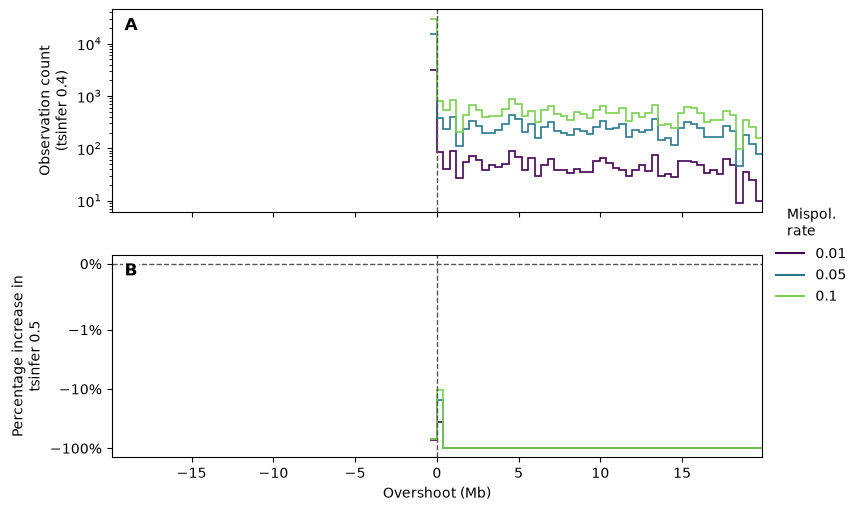

In [9]:
nb_plot.plot_mispolarisation_low_count_overshoot_diff(
    data,
    figure_folder=figure_folder,
    num_bins=100,
    figsize=(8.5, 5),
    legend_fontsize=10,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_legend_labels=("No errors", "Combined\nerrors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    histogram_bins=100,
    overshoot_diff_cmap="viridis",
    overshoot_diff_color_range=(0, 0.8),
    overshoot_diff_legend_fontsize=10,
    overshoot_diff_line_width=1.2,
    overshoot_diff_linthresh_pct=1,
    overshoot_diff_panel_gap=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    overshoot_diff_size=(8.5, 5),
    phase_ser_decimals=2,
    zero_color="#555555",
)

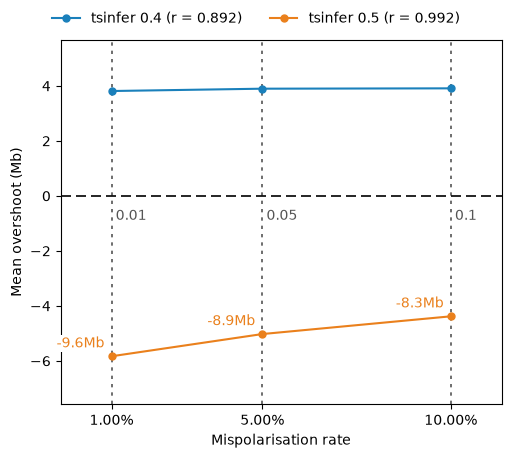

In [6]:
nb_plot.plot_mispolarisation_low_count_overshoot_scatter(
    data,
    figure_folder=figure_folder,
    figsize=(5, 4.5),
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    genotype_scatter_connector_width=0.8,
    genotype_scatter_error_change_offset=(-5, -4),
    mean_change_decimals=1,
    overshoot_diff_line_width=1.2,
    overshoot_scatter_change_fontsize=10,
    overshoot_scatter_change_offset=(-5, 4),
    overshoot_scatter_correlation_decimals=3,
    overshoot_scatter_guide_depth=0.05,
    overshoot_scatter_label_fontsize=10,
    overshoot_scatter_label_padding=3,
    overshoot_scatter_marker_size=5,
    overshoot_scatter_size=(5, 4.5),
    overshoot_scatter_tick_decimals=2,
    overshoot_scatter_vertical_dash=(0, (2, 3)),
    overshoot_scatter_x_margin=0.15,
    overshoot_scatter_y_margin=0.18,
    overshoot_scatter_zero_dash=(0, (6, 3)),
    phase_scatter_change_offset=(-5, 4),
    phase_scatter_guide_depth=0.2,
    phase_ser_decimals=2,
    version_colors=("#1a80bb", "#ea801c"),
    zero_color="#555555",
)

### DAF-stratified mismatch fraction by focal-site polarisation

For tsinfer 0.5, compare no error, mispolarised focal sites and non-mispolarised
focal sites, with both latter groups from the pure rate-0.1 simulation.
A: pooled errors / pooled overlapping inference sites in five equal-width
true-DAF bins . B: grouped focal-site counts
in the same bins. True DAFs come from exported error-free variants, including
true singletons absent from error-free inference sites. Both panels use log y;
set `y_scale="linear"` to change the mismatch-fraction axis.
This exploratory figure stays in the notebook and local figure folder.

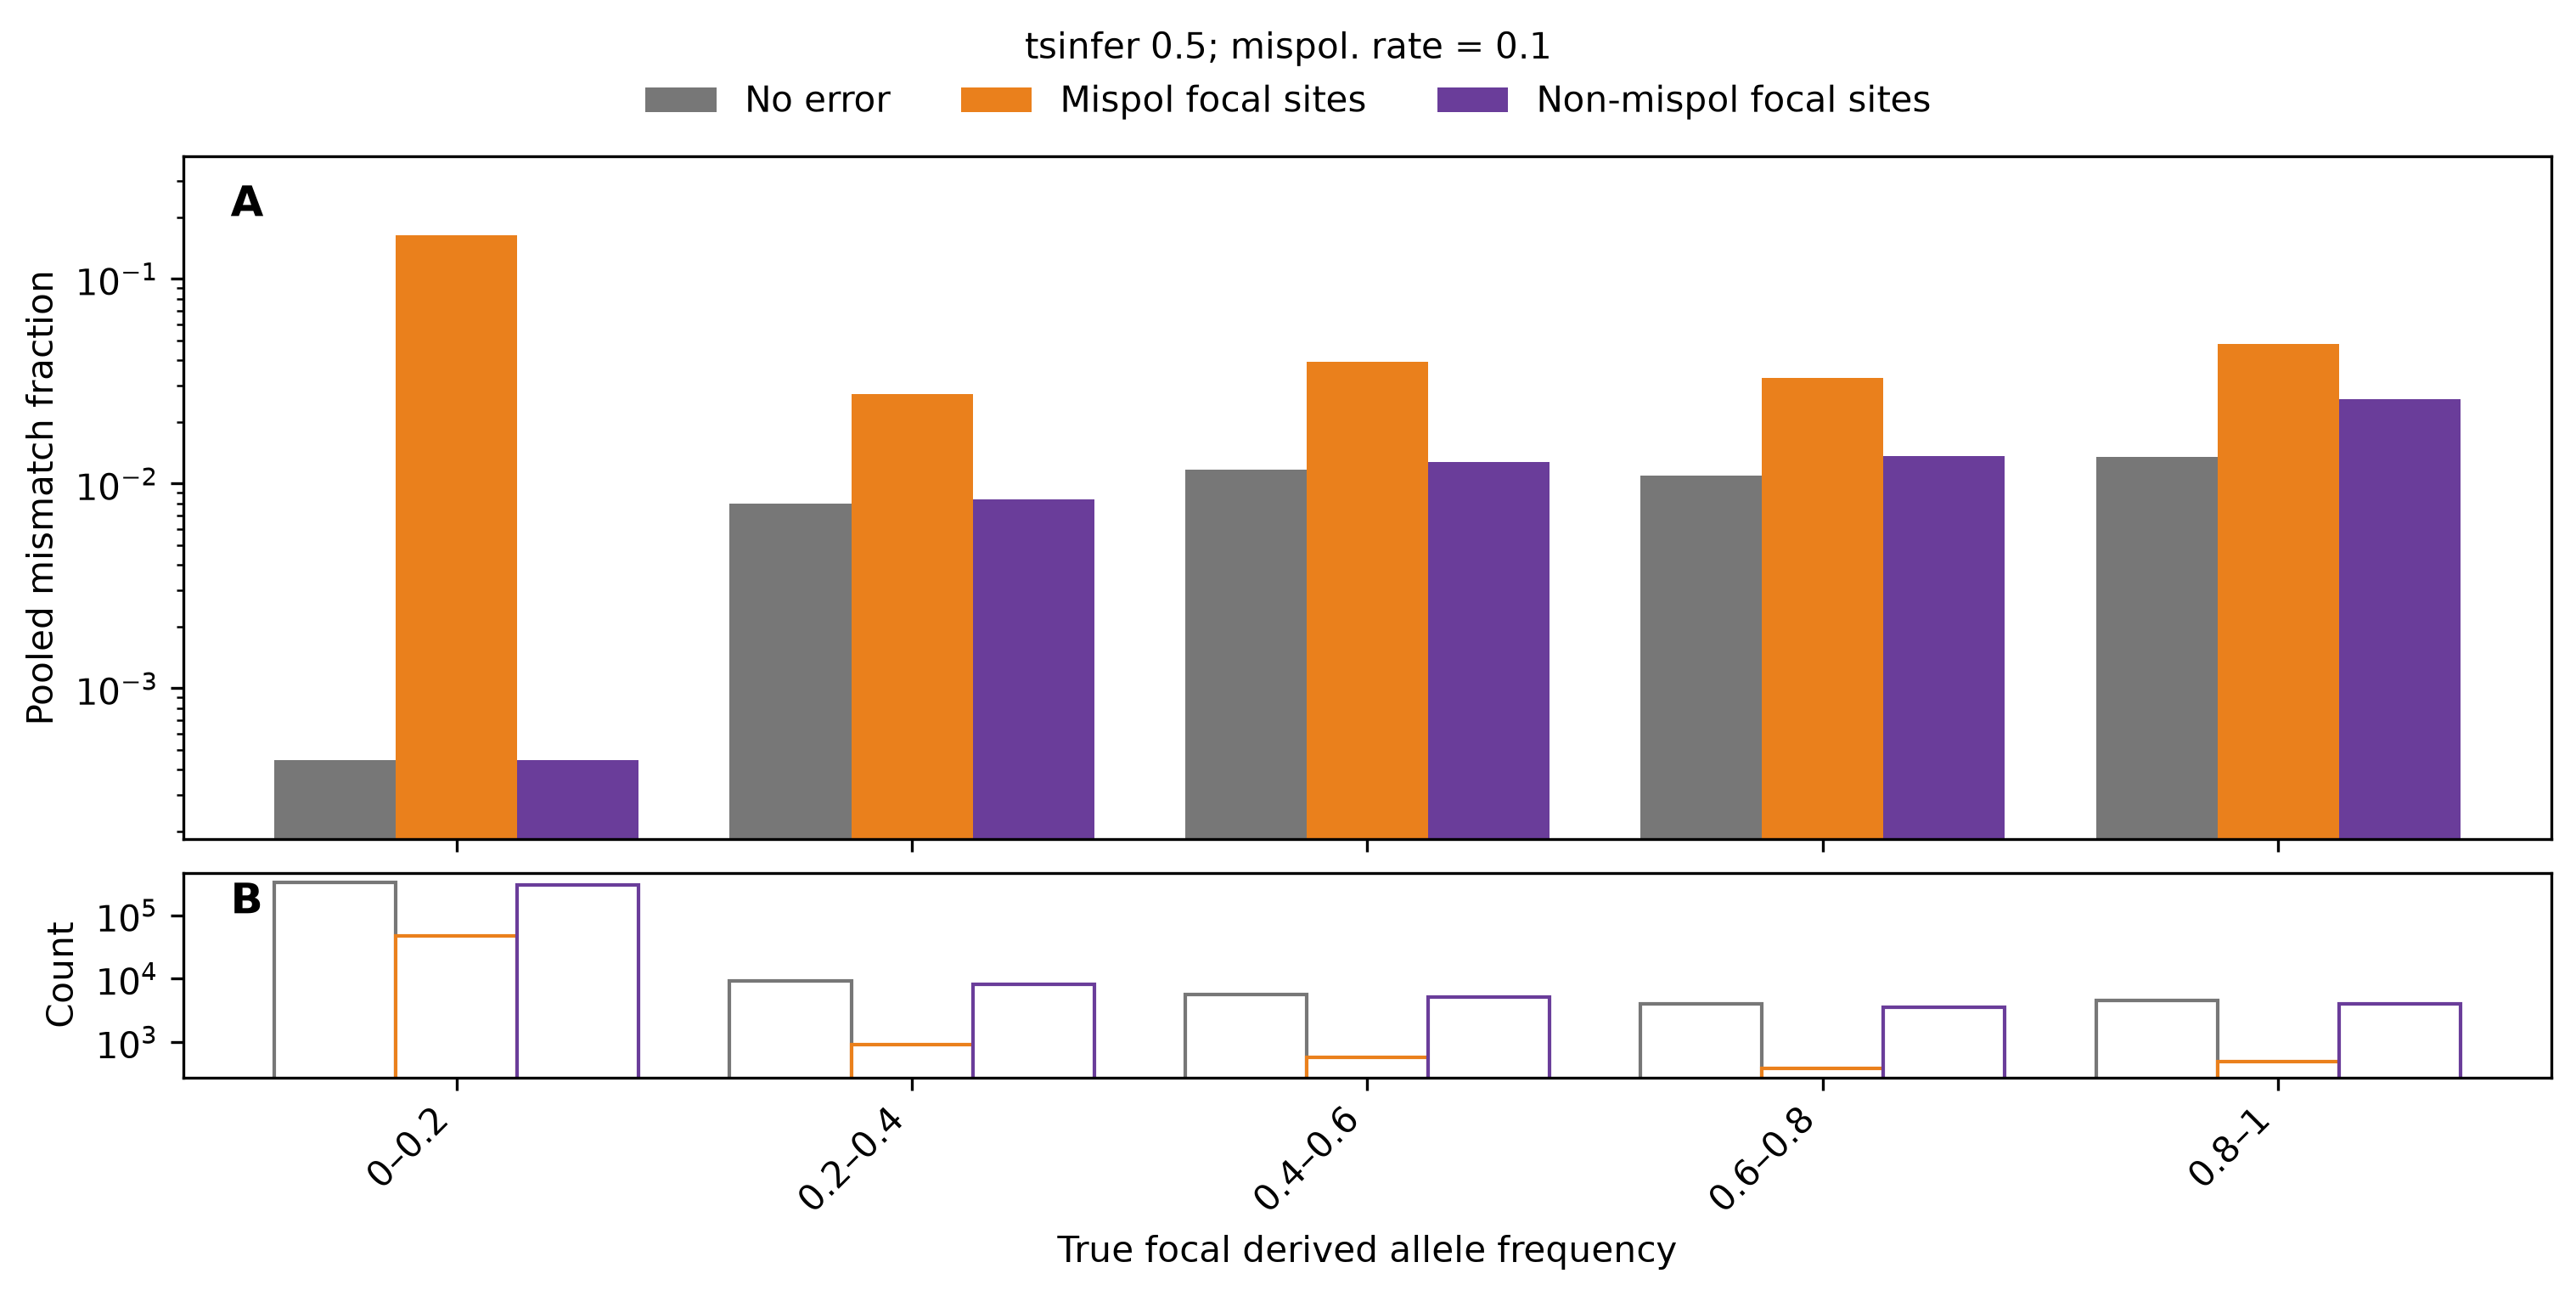

In [ ]:
mispolarisation_mismatch_comparisons = nb_utils.load_mispolarisation_overlap_errors(
    aggregated_path, config=config, mispolarisation_error_rates=(0.01, 0.1)
)
mispolarisation_mismatch_summary = nb_utils.summarise_mispolarisation_mismatch_by_daf(
    mispolarisation_mismatch_comparisons,
    true_frequencies=nb_utils._true_focal_frequencies(data.zarr_data),
    config=config,
    num_bins=5,
    ancestor_error_version="0.5.1",
    mispolarisation_mismatch_bins=10,
    mispolarisation_mismatch_groups=("none", "mispolarised", "correctly_polarised"),
    mispolarisation_mismatch_rate=0.1,
)
nb_plot.plot_mispolarisation_mismatch_by_daf(
    mispolarisation_mismatch_summary,
    figure_folder=figure_folder,
    config=config,
    y_scale="log",
    ancestor_error_version="0.5.1",
    dpi=300,
    mean_bar_group_width=0.8,
    mispolarisation_mismatch_colors=("#777777", "#ea801c", "#6a3d9a"),
    mispolarisation_mismatch_groups=("none", "mispolarised", "correctly_polarised"),
    mispolarisation_mismatch_height_ratios=(4, 1.2),
    mispolarisation_mismatch_labels=(
        "No error",
        "Mispol focal sites",
        "Non-mispol focal sites",
    ),
    mispolarisation_mismatch_rate=0.1,
    mispolarisation_mismatch_size=(10, 5),
    mispolarisation_mismatch_y_margin=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
)

## Phase-switch errors

All phase plots use the updated 20 Mb simulation. Each pair of illustration
rows shows the same two individuals at one target spacing (0.2, 2 or 20 Mb).
Colours follow the exported true haplotype identity, including homozygous sites.
The summary table includes the no-switch baseline and every tested spacing.

In [93]:
phase_settings = data.phase_settings.loc[
    lambda frame: frame.space_per_switch > 0
].copy()
phase_settings["mean_gap_mb"] = phase_settings.space_per_switch / config.bp_per_mb
phase_settings = phase_settings[["mean_gap_mb", "phase_ser"]]
ipd.display(phase_settings.style.format({"mean_gap_mb": "{:g}", "phase_ser": "{:.8g}"}))

,mean_gap_mb,phase_ser
4892256,0.2,0.0076505917
5608826,2,0.00076505917
6325396,20,7.6505917e-05


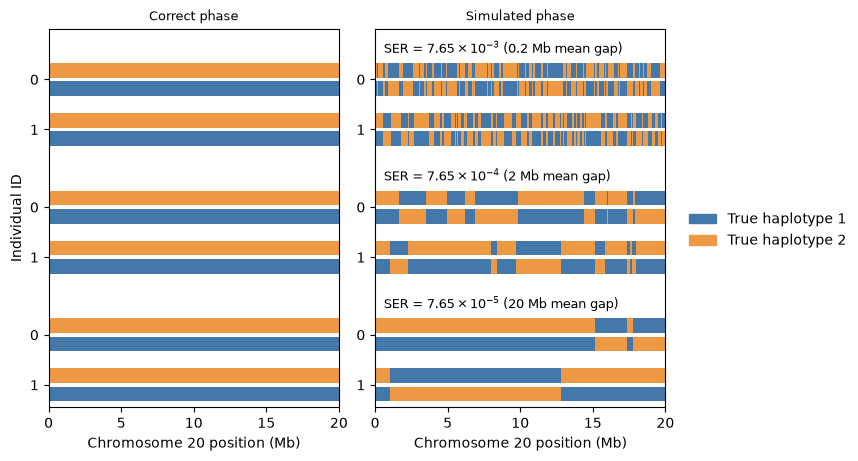

Prepared thesis export: phase_switch_illustration.png


In [2]:
nb_plot.plot_phase_switch_illustration(
    phase_runs_path,
    figure_folder=figure_folder,
    config=config,
    figsize=(8.5, 4.5),
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    phase_colors=("#4477aa", "#ee9944"),
    phase_group_gap=0.45,
    phase_label_fontsize=9,
    phase_right_mb=20,
    phase_row_spacing=0.82,
    phase_ser_decimals=2,
    phase_size=(8.5, 4.5),
)

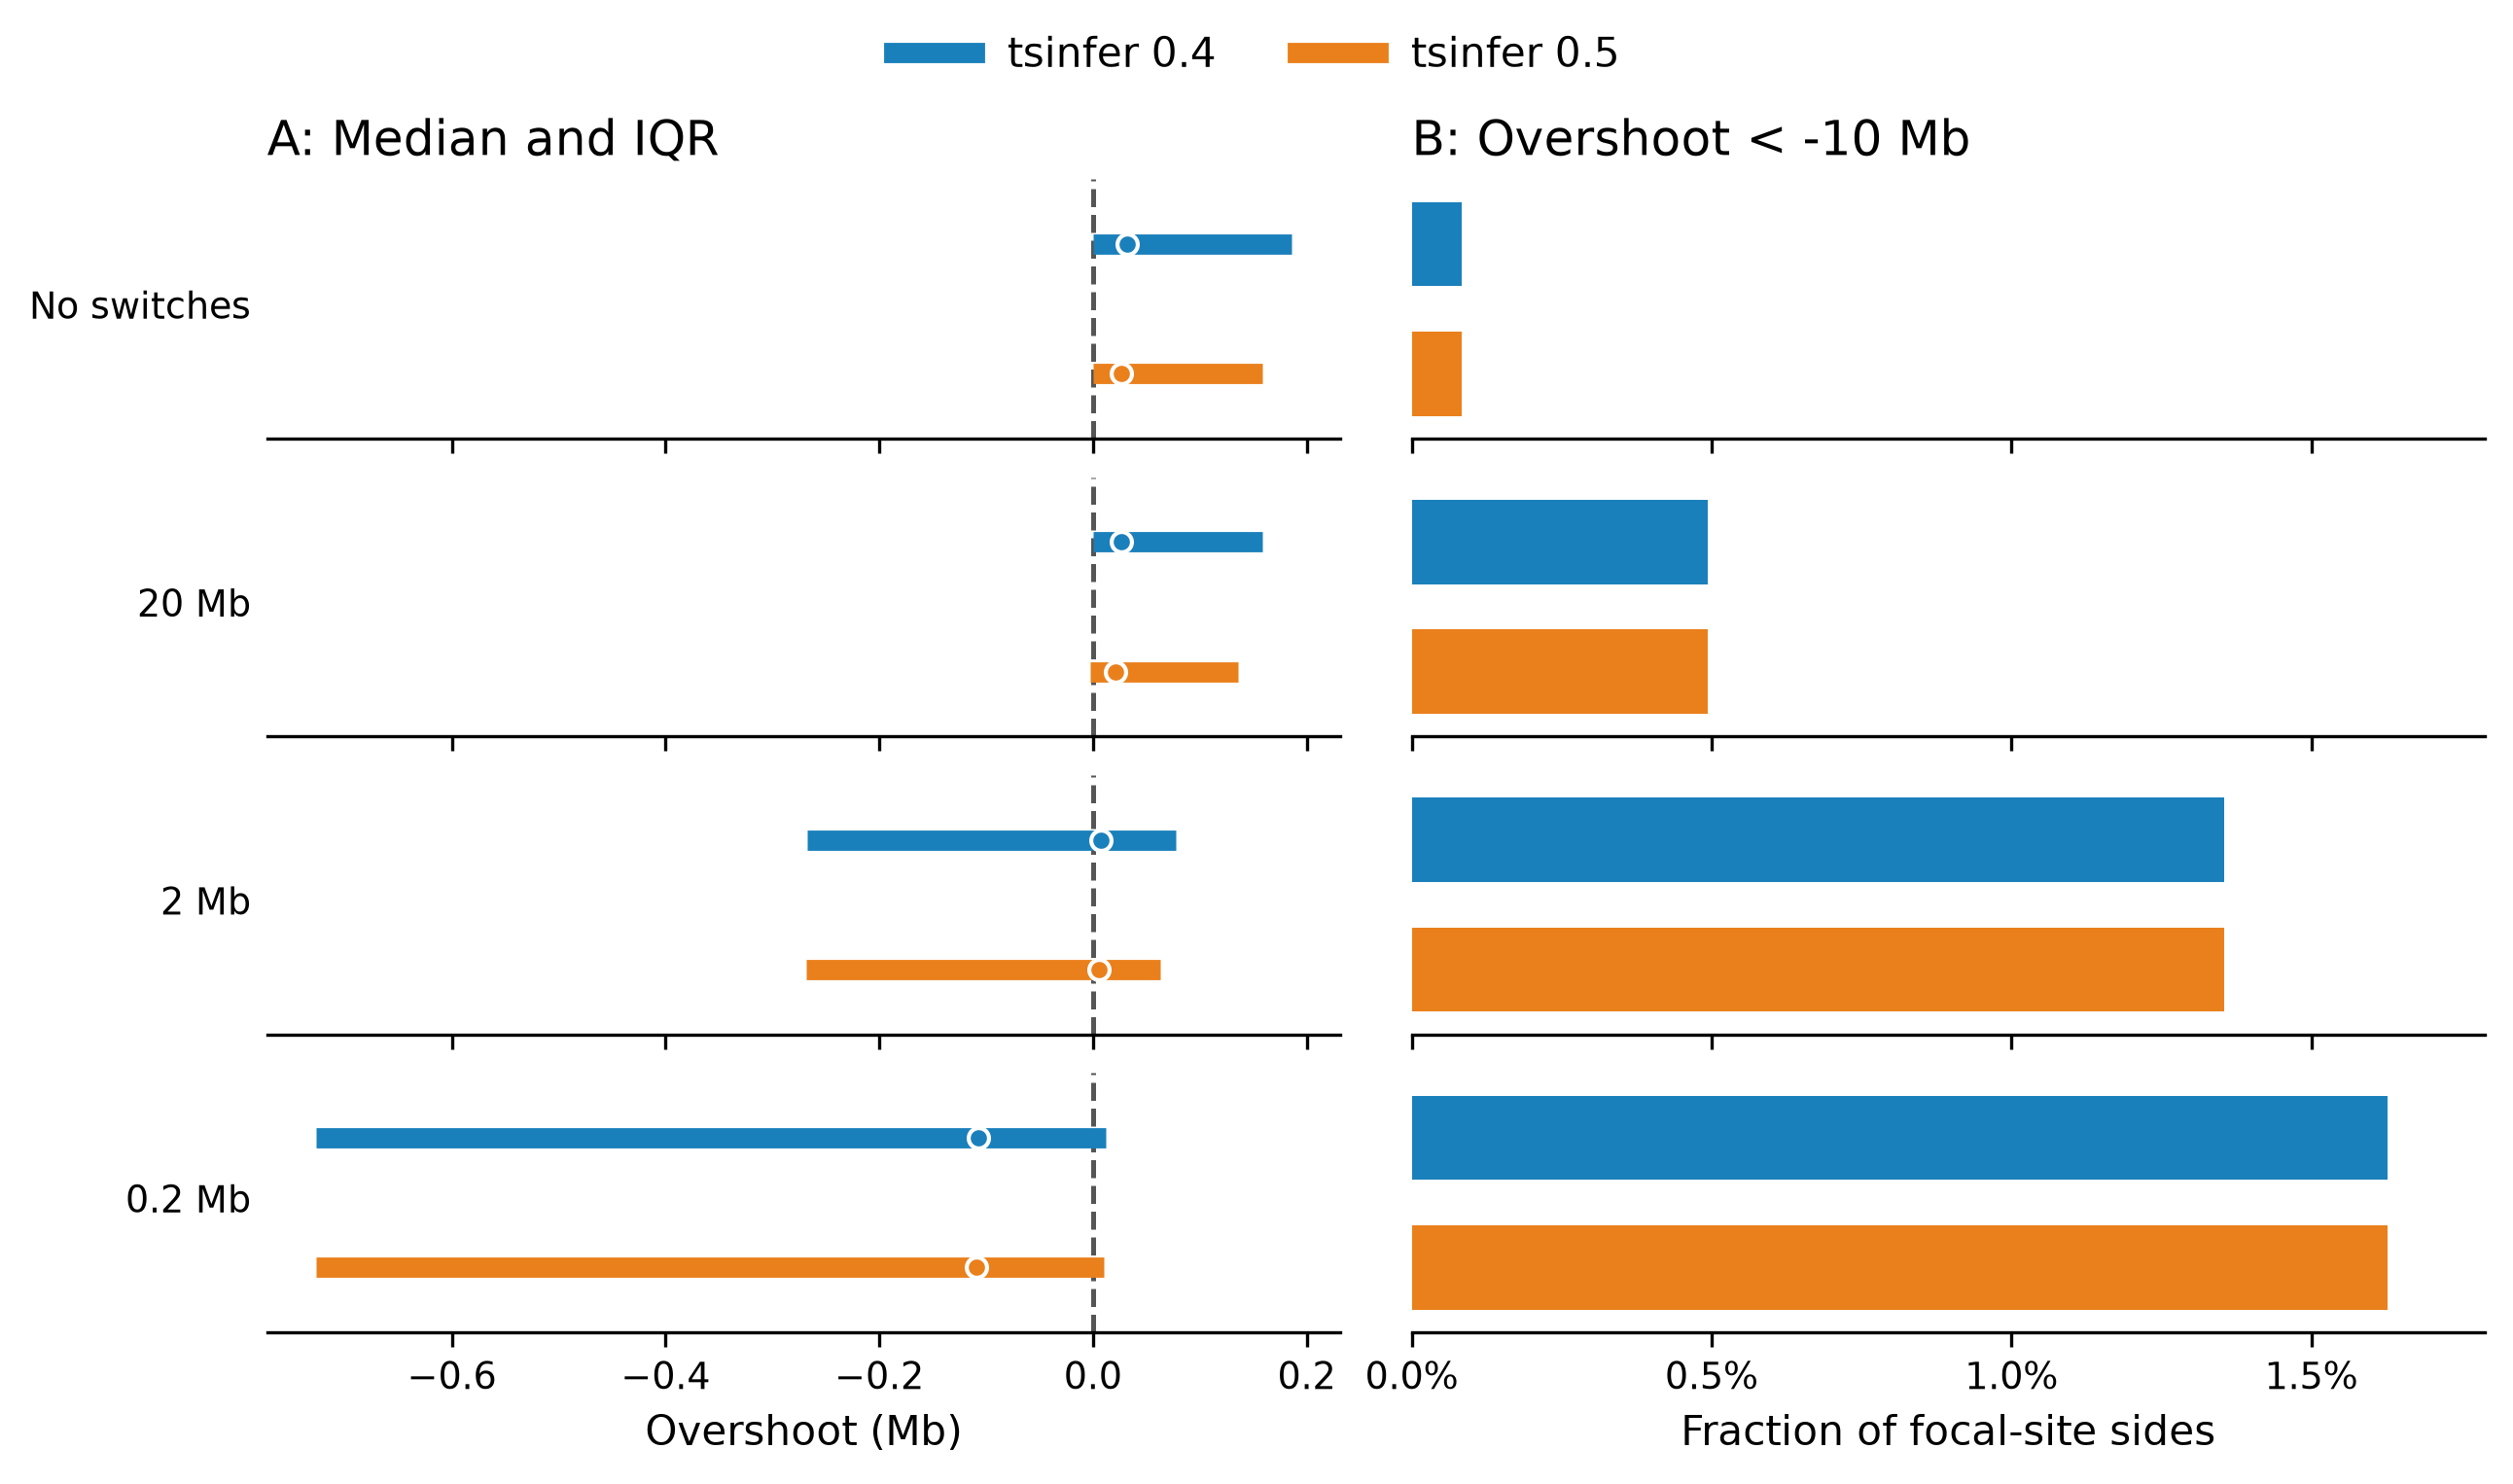

In [ ]:
phase_summary_spacings = (
    0,
    *sorted((gap for gap in config.phase_spacings if gap != 0))[::-1],
)
phasing_overshoot_summary = nb_utils.summarise_overshoots(
    nb_utils._phasing_overshoots(data),
    "space_per_switch",
    phase_summary_spacings,
    config,
)
phase_summary_labels = {
    gap: "No switches" if gap == 0 else f"{gap / config.bp_per_mb:g} Mb"
    for gap in phase_summary_spacings
}
nb_plot.plot_overshoot_summary(
    phasing_overshoot_summary,
    "space_per_switch",
    phase_summary_spacings,
    phase_summary_labels,
    "phasing_error_overshoot_summary",
    figure_folder=figure_folder,
    config=config,
    dpi=300,
    overshoot_summary_bar_height=0.65,
    overshoot_summary_fraction_margin=0.1,
    overshoot_summary_fraction_ticks=4,
    overshoot_summary_interval_width=5,
    overshoot_summary_label_fontsize=9,
    overshoot_summary_marker_size=5,
    overshoot_summary_percent_decimals=1,
    overshoot_summary_size=(8.5, 5),
    quantile_line_style="--",
    quantile_line_width=1.2,
    version_colors=("#1a80bb", "#ea801c"),
    zero_color="#555555",
)

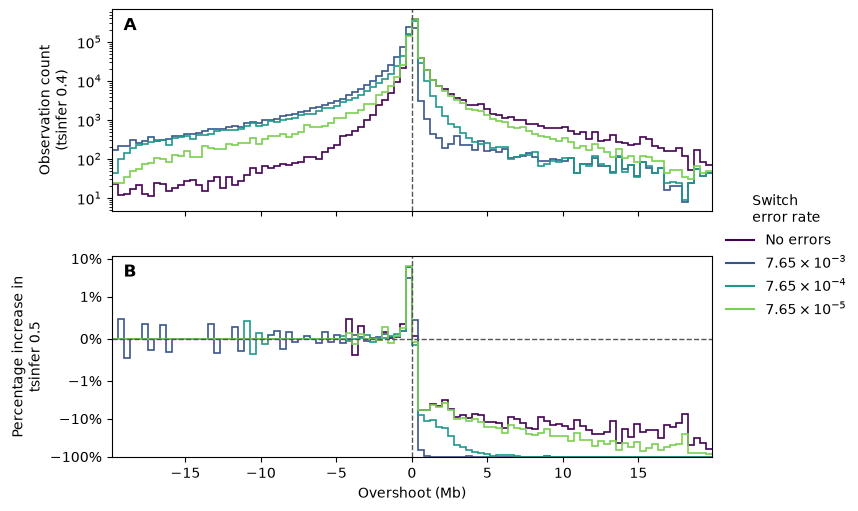

In [10]:
nb_plot.plot_phasing_overshoot_diff(
    data,
    figure_folder=figure_folder,
    num_bins=100,
    figsize=(8.5, 5),
    legend_fontsize=10,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_legend_labels=("No errors", "Combined\nerrors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    histogram_bins=100,
    overshoot_diff_cmap="viridis",
    overshoot_diff_color_range=(0, 0.8),
    overshoot_diff_legend_fontsize=10,
    overshoot_diff_line_width=1.2,
    overshoot_diff_linthresh_pct=1,
    overshoot_diff_panel_gap=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    overshoot_diff_size=(8.5, 5),
    phase_ser_decimals=2,
    zero_color="#555555",
)

### Additional phase plots (not exported to the thesis)

Histograms, boxes and tails use the same updated aggregate and label
settings by mean gap in Mb. The no-switch baseline is labelled "No errors".

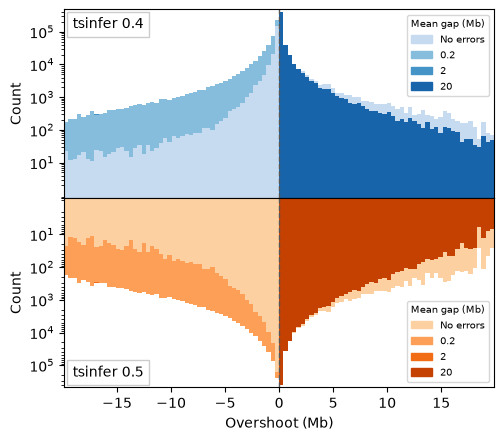

In [97]:
nb_plot.plot_phasing_overshoot_hist(
    data,
    figure_folder=figure_folder,
    figsize=(5, 4.5),
    legend_fontsize=7.5,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    histogram_bins=100,
    histogram_labelled_legend_anchors=((0.04, 1), (0.98, 1)),
    histogram_line_width=1.2,
    histogram_size=(7, 4.5),
    overshoot_cmaps=("Blues", "Oranges"),
    overshoot_diff_panel_gap=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    phase_ser_decimals=2,
    zero_color="#555555",
)

In [99]:
phasing_leftmost_bin = nb_utils.summarise_leftmost_overshoot_bin(
    nb_utils._phasing_overshoots(data),
    "space_per_switch",
    config.phase_spacings,
    config=config,
    histogram_bins=100,
)
ipd.display(phasing_leftmost_bin)
phasing_leftmost_bin_comparison = phasing_leftmost_bin[
    ["num_sides_in_leftmost_bin", "percentage_in_leftmost_bin"]
].unstack("version")
ipd.display(
    phasing_leftmost_bin_comparison.style.format(
        {
            ("num_sides_in_leftmost_bin", version): "{:,.0f}"
            for version in config.versions
        }
    ).format(
        {
            ("percentage_in_leftmost_bin", version): "{:.6f}%"
            for version in config.versions
        }
    )
)

left_edge_bp  right_edge_bp  bin_width_bp  \
space_per_switch version                                              
0.0              0.4.1     -19891917.0   -19494040.29     397876.71   
                 0.5.1     -19891917.0   -19494040.29     397876.71   
200000.0         0.4.1     -19891917.0   -19494040.29     397876.71   
                 0.5.1     -19891917.0   -19494040.29     397876.71   
2000000.0        0.4.1     -19891917.0   -19494040.29     397876.71   
                 0.5.1     -19891917.0   -19494040.29     397876.71   
20000000.0       0.4.1     -19891917.0   -19494040.29     397876.71   
                 0.5.1     -19891917.0   -19494040.29     397876.71   

                          num_sides_in_leftmost_bin  total_num_sides  \
space_per_switch version                                               
0.0              0.4.1                           23           716570   
                 0.5.1                           23           716570   
200000.0         0.4.1                          169           716570   
                 0.5.1                          169           716570   
2000000.0        0.4.1                           45           716570   
                 0.5.1                           45           716570   
20000000.0       0.4.1                           24           716570   
                 0.5.1                           24           716570   

                          percentage_in_leftmost_bin  
space_per_switch version                              
0.0              0.4.1                      0.003210  
                 0.5.1                      0.003210  
200000.0         0.4.1                      0.023585  
                 0.5.1                      0.023585  
2000000.0        0.4.1                      0.006280  
                 0.5.1                      0.006280  
20000000.0       0.4.1                      0.003349  
                 0.5.1                      0.003349

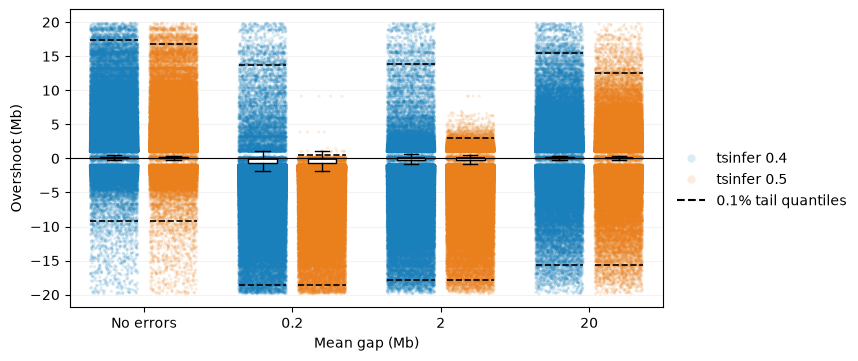

In [9]:
nb_plot.plot_phasing_overshoot_box(
    data,
    figure_folder=figure_folder,
    conf=0.001,
    figsize=(8.5, 3.5),
    y_log=False,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    jitter_alpha=0.15,
    jitter_max_points=1500,
    jitter_sample_interval_mb=(-1, 1),
    jitter_seed=42,
    jitter_size=5,
    jitter_width=0.32,
    overshoot_box_size=(8.5, 3.5),
    overshoot_box_width_ratio=0.6,
    overshoot_linthresh_bp=1000,
    phase_ser_decimals=2,
    quantile_line_style="--",
    quantile_line_width=1.2,
    quantile_secondary_color="#555555",
    quantile_secondary_line_style="-.",
    version_colors=("#1a80bb", "#ea801c"),
)

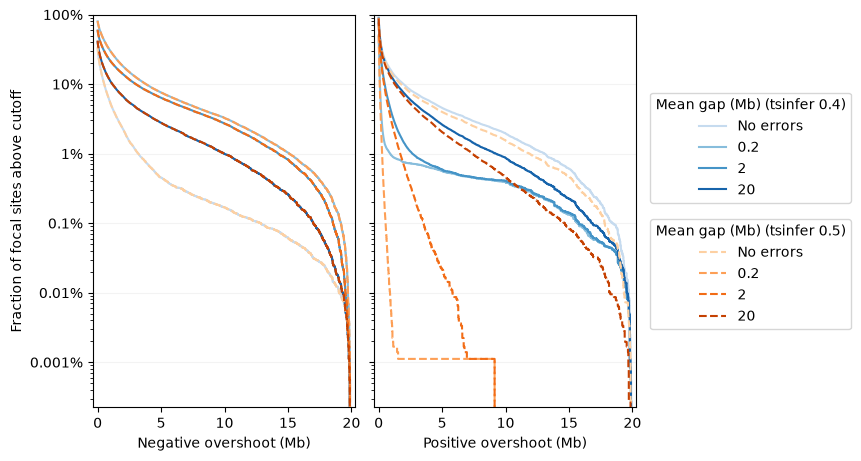

In [101]:
nb_plot.plot_phasing_overshoot_tails(
    data,
    figure_folder=figure_folder,
    figsize=(8.5, 4.5),
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    mean_bar_group_width=0.8,
    overshoot_cmaps=("Blues", "Oranges"),
    overshoot_tail_size=(8.5, 4.5),
    phase_ser_decimals=2,
    tail_count_height_ratio=0.28,
    tail_legend_gap=0.04,
    tail_legend_width_ratio=0.75,
    version_colors=("#1a80bb", "#ea801c"),
    version_line_styles=("-", "--"),
)

## Combined errors

Compare the aggregate's named `none` and `all` profiles, pooling every
available replicate. The `all` profile combines the 1× empirical genotype
error model, a 2 Mb mean phase-switch spacing, and 1% mispolarisation.
Display the stored switch error rate below: it differs slightly from the
phasing-only profile because the combined input also has genotype errors.
Accuracy uses one whole overlap per focal site (left rows only); mismatch fraction
divides summed errors by summed compared inference sites. Overshoot counts retain
both sides and use 100 shared physical bins across profiles and versions.
The standalone plots remain here; the thesis export combines A–B on the
left (40% width) and C–D on the right with the usual viridis endpoint colours.
All panels exclude mispolarised focal sites. Panel B uses a linear mismatch-fraction axis.

In [ ]:
combined_error_comparisons = nb_utils.load_combined_error_comparisons(
    aggregated_path, config=config, combined_error_profiles=("none", "all")
)
combined_error_parameters = (
    combined_error_comparisons[
        [
            "error_profile",
            "replicate",
            "geno_multiplier",
            "space_per_switch",
            "phase_ser",
            "mispol_rate",
        ]
    ]
    .drop_duplicates()
    .sort_values(["error_profile", "replicate"])
)
ipd.display(combined_error_parameters)
combined_error_summary = nb_utils.summarise_combined_overlap_errors(
    combined_error_comparisons
)
ipd.display(combined_error_summary)

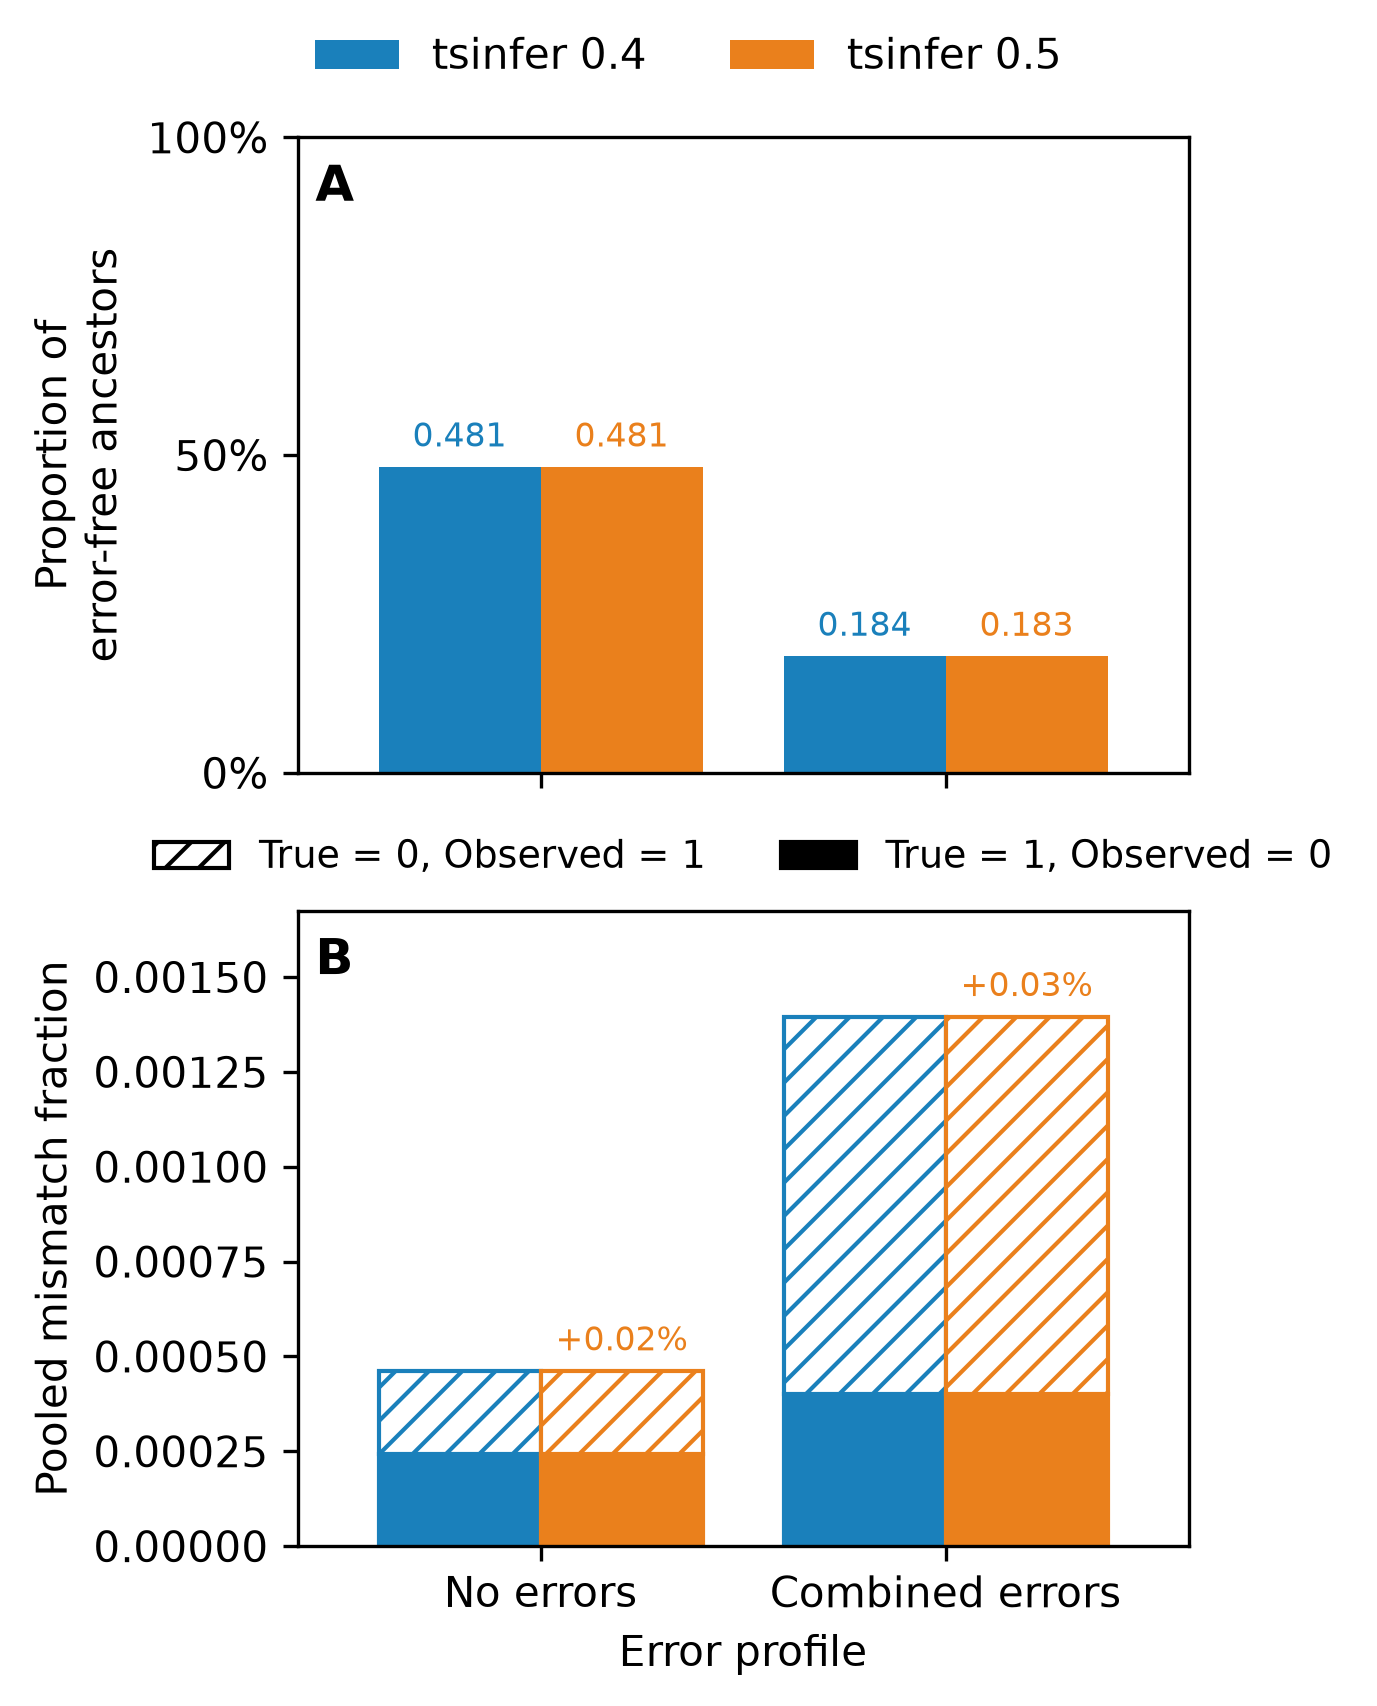

In [ ]:
nb_plot.plot_combined_overlap_errors(
    combined_error_summary,
    figure_folder=figure_folder,
    config=config,
    figsize=(4.4, 5.6),
    ancestor_error_change_decimals=2,
    ancestor_error_count_margin=0.4,
    ancestor_error_hatch="///",
    ancestor_error_height_ratios=(1, 1, 0.6),
    ancestor_error_label_decimals=3,
    ancestor_error_label_fontsize=8,
    ancestor_error_label_padding=3,
    ancestor_error_legend_fontsize=9,
    ancestor_error_log_numticks=6,
    ancestor_error_log_subs=(1, 2, 5),
    ancestor_error_size=(7, 5.4),
    ancestor_error_type_labels=("True = 0, Observed = 1", "True = 1, Observed = 0"),
    ancestor_error_y_log=True,
    ancestor_mismatch_fraction_label_margin=0.2,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    mean_bar_group_width=0.8,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    version_colors=("#1a80bb", "#ea801c"),
)

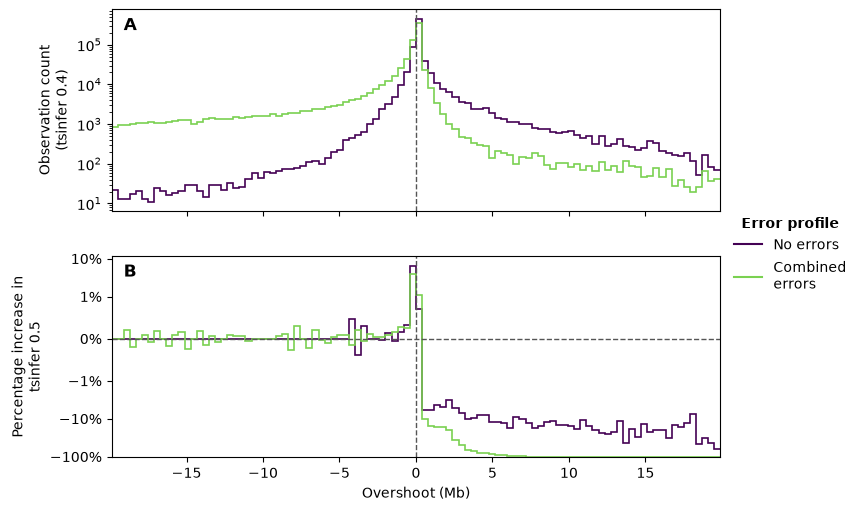

In [4]:
nb_plot.plot_combined_overshoot_diff(
    combined_error_comparisons,
    figure_folder=figure_folder,
    config=config,
    num_bins=100,
    figsize=(8.5, 5),
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_legend_labels=("No errors", "Combined\nerrors"),
    combined_error_profiles=("none", "all"),
    dpi=300,
    histogram_bins=100,
    legend_fontsize=10,
    overshoot_diff_cmap="viridis",
    overshoot_diff_color_range=(0, 0.8),
    overshoot_diff_legend_fontsize=10,
    overshoot_diff_line_width=1.2,
    overshoot_diff_linthresh_pct=1,
    overshoot_diff_panel_gap=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    overshoot_diff_size=(8.5, 5),
    phase_ser_decimals=2,
    zero_color="#555555",
)

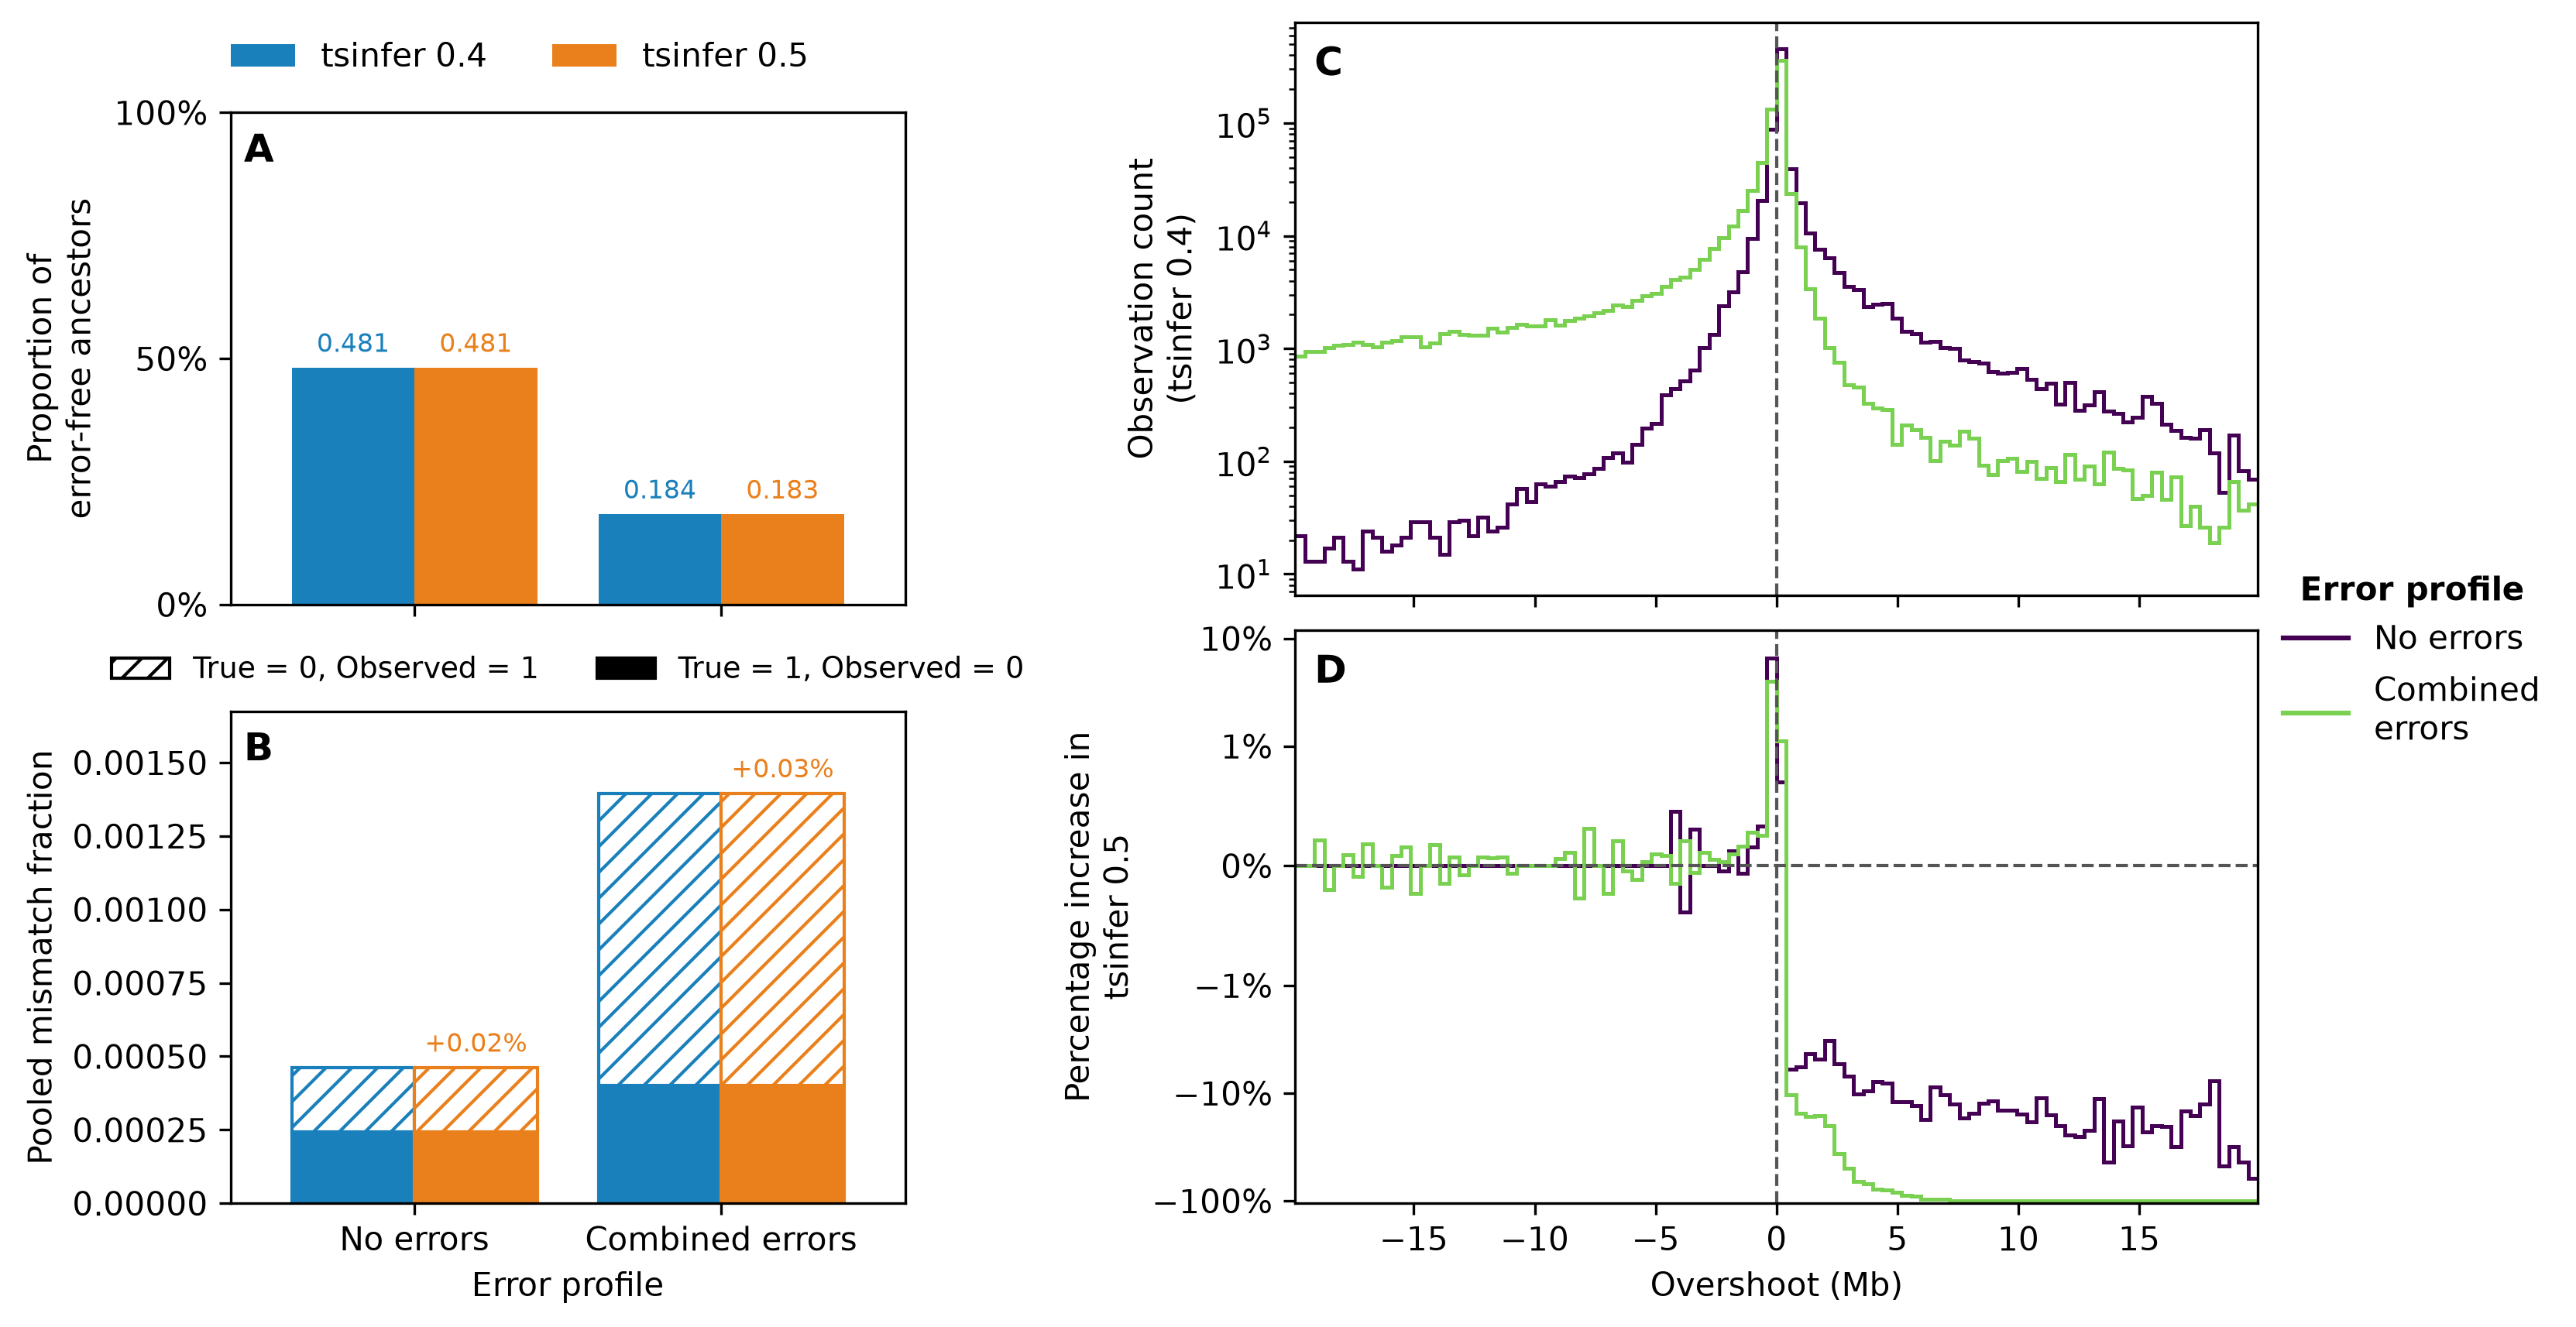

In [ ]:
nb_plot.plot_combined_errors(
    combined_error_comparisons,
    figure_folder=figure_folder,
    config=config,
    num_bins=100,
    ancestor_error_change_decimals=2,
    ancestor_error_count_margin=0.4,
    ancestor_error_hatch="///",
    ancestor_error_height_ratios=(1, 1, 0.6),
    ancestor_error_label_decimals=3,
    ancestor_error_label_fontsize=8,
    ancestor_error_label_padding=3,
    ancestor_error_legend_fontsize=9,
    ancestor_error_log_numticks=6,
    ancestor_error_log_subs=(1, 2, 5),
    ancestor_error_size=(7, 5.4),
    ancestor_error_type_labels=("True = 0, Observed = 1", "True = 1, Observed = 0"),
    ancestor_error_y_log=True,
    ancestor_mismatch_fraction_label_margin=0.2,
    combined_error_labels=("No errors", "Combined errors"),
    combined_error_legend_labels=("No errors", "Combined\nerrors"),
    combined_error_profiles=("none", "all"),
    combined_error_size=(11, 5.6),
    combined_error_width_ratios=(0.4, 0.6),
    dpi=300,
    histogram_bins=100,
    mean_bar_group_width=0.8,
    overshoot_diff_cmap="viridis",
    overshoot_diff_color_range=(0, 0.8),
    overshoot_diff_legend_fontsize=10,
    overshoot_diff_line_width=1.2,
    overshoot_diff_linthresh_pct=1,
    overshoot_diff_panel_gap=0.15,
    overshoot_diff_panel_label_fontsize=12,
    overshoot_diff_panel_label_position=(0.02, 0.96),
    overshoot_diff_panel_labels=("A", "B"),
    overshoot_diff_size=(8.5, 5),
    phase_ser_decimals=2,
    version_colors=("#1a80bb", "#ea801c"),
    zero_color="#555555",
)

## Inference performance: tsinfer 0.4 versus 0.5

These cells run independently of the simulation and Zarr analyses above.
All plots read the benchmark's data/dataframes/perf_combined.csv, retaining
rep0, rep1 and rep2 for n=100, n=1,000 and 1KGP; n=10,000 and n=100,000
have one run each. Repetitions rerun inference on the same fixed inputs,
using 196 configured threads on the same host. Simulations cover 28.1 Mb;
1KGP chr20p has 6,404 haplotypes and 504,149 filtered sites.
CSV labels 0.4 and 0.5 retain provenance versions 0.4.1 and 0.5.2.dev1.
Speedup bars show the mean of paired rep-wise elapsed_0.4 / elapsed_0.5,
with a jittered point for each rep. Values above 1 mean faster in 0.5.
Stacked bars show mean stage times; points at each cumulative boundary show
individual runs in the stage colour with black borders, with the same
horizontal jitter across stages within a run.
Parentheses show the mean paired total-time speedup; totals are mean minutes.
Each sample-size panel has its own linear y scale so smaller runs stay visible.

In [2]:
import pathlib

import IPython.display as ipdisplay
import pandas as pd

perf_config = nb_utils.PerformanceConfig(versions=("0.4", "0.5"))
perf_path = pathlib.Path(
    "~/work/tsinfer-perf-benchmark/data/dataframes/perf_combined.csv"
).expanduser()
perf_comparison_data = nb_utils.load_performance(perf_path, perf_config)
tgp_rows = perf_comparison_data.prefix.eq("1kgp-chr20-L0-R2.81e7")
perf_data = perf_comparison_data.loc[~tgp_rows]
tgp_perf_data = perf_comparison_data.loc[tgp_rows]

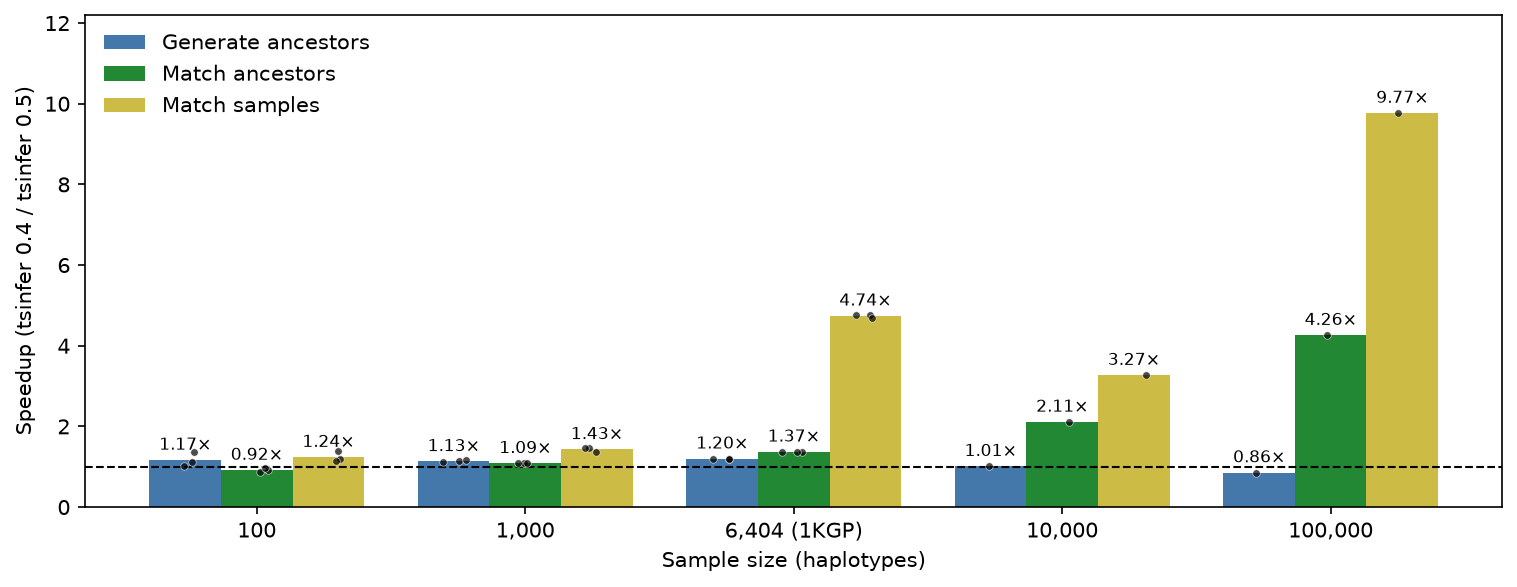

In [103]:
perf_speedup_figure = nb_plot.plot_speedup(
    perf_comparison_data,
    perf_config,
    dpi=150,
    group_width=0.8,
    jitter_seed=42,
    jitter_width=0.18,
    repetition_alpha=0.7,
    repetition_marker_size=13,
    sample_labels={6404: "6,404 (1KGP)"},
    speedup_figsize=(7.5, 3.5),
    speedup_top_margin=0.1,
    stage_colors=("#4477aa", "#228833", "#ccbb44"),
    stage_labels=("Generate ancestors", "Match ancestors", "Match samples"),
)
nb_plot.save_notebook_figure(
    perf_speedup_figure,
    figure_folder / "inference_performance_speedup.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
nb_plot.show_figure()

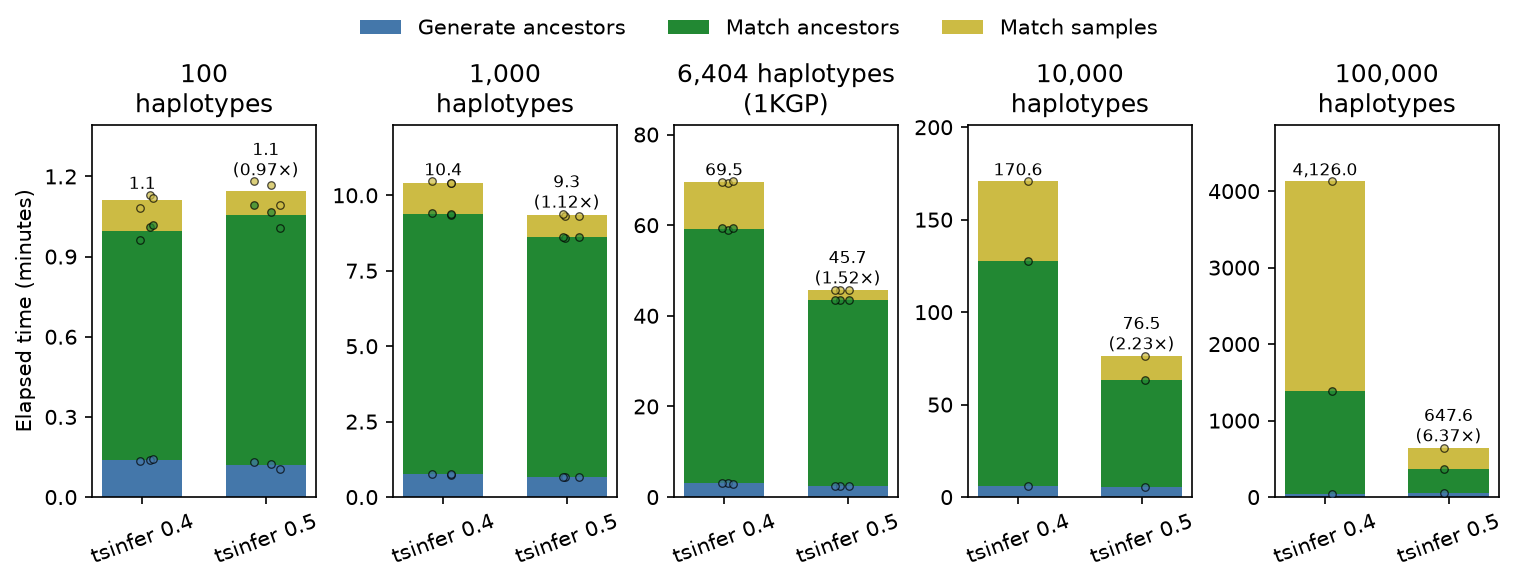

In [104]:
perf_elapsed_figure = nb_plot.plot_elapsed(
    perf_comparison_data,
    perf_config,
    dpi=150,
    elapsed_bar_width=0.65,
    figsize=(10, 3.8),
    jitter_seed=42,
    jitter_width=0.18,
    repetition_alpha=0.7,
    repetition_marker_size=13,
    sample_labels={6404: "6,404 (1KGP)"},
    sample_titles={6404: "6,404 haplotypes\n(1KGP)"},
    stage_colors=("#4477aa", "#228833", "#ccbb44"),
    stage_labels=("Generate ancestors", "Match ancestors", "Match samples"),
    version_labels=("tsinfer 0.4", "tsinfer 0.5"),
)
nb_plot.save_notebook_figure(
    perf_elapsed_figure,
    figure_folder / "inference_performance_elapsed.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
nb_plot.show_figure()

### Memory usage

Peak resident memory from each stage's provenance, converted from bytes to
GiB. Memory is not additive across stages. Each stage runs in a fresh process;
its high-water mark includes setup and input loading. Log-log axes show
scaling across the four simulation sample sizes, with shared stage limits.
Lines connect means across reps; small jittered points retain individual runs.
Triangles mark mean 1KGP chr20p values, with its individual reps also shown.

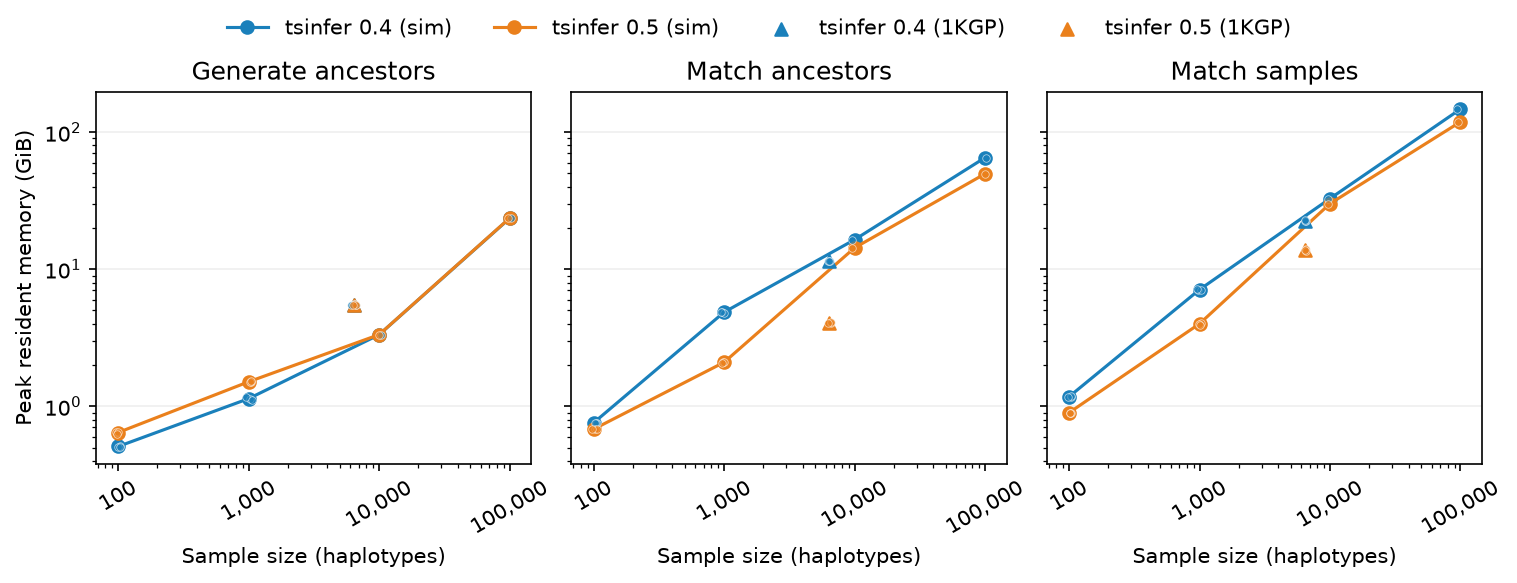

In [105]:
perf_memory_figure = nb_plot.plot_resources(
    perf_data,
    "memory_gib",
    perf_config,
    reference_data=tgp_perf_data,
    dpi=150,
    figsize=(10, 3.8),
    jitter_seed=42,
    parallelism_reference_cores=192,
    reference_markers=("^", "^"),
    repetition_alpha=0.7,
    repetition_marker_size=13,
    resource_jitter_log10=0.025,
    resource_range_capsize=4,
    resource_range_linewidth=0.65,
    stage_labels=("Generate ancestors", "Match ancestors", "Match samples"),
    version_colors=("#1a80bb", "#ea801c"),
    version_labels=("tsinfer 0.4", "tsinfer 0.5"),
)
nb_plot.save_notebook_figure(
    perf_memory_figure,
    figure_folder / "inference_performance_memory.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
nb_plot.show_figure()

### Parallelism

Average active CPU cores = `(user_time + sys_time) / elapsed_time` for each
stage, including setup and I/O inside the inference API call. Top-level
input loading, process startup and output writing are outside that timer.
This measures achieved CPU concurrency, not
speedup from threading: there is no single-threaded baseline here. Shared
linear y axes allow comparison between stages; the dotted line marks the
192-core reference.
Lines connect mean per-run concurrency; capped error bars span min to max
across reps, without individual jittered points. Single runs have zero range.
Triangles show mean 1KGP chr20p (6,404 haplotypes) with the same min–max
error bars, with colours identifying
tsinfer versions in both datasets. Both datasets use the threaded API.

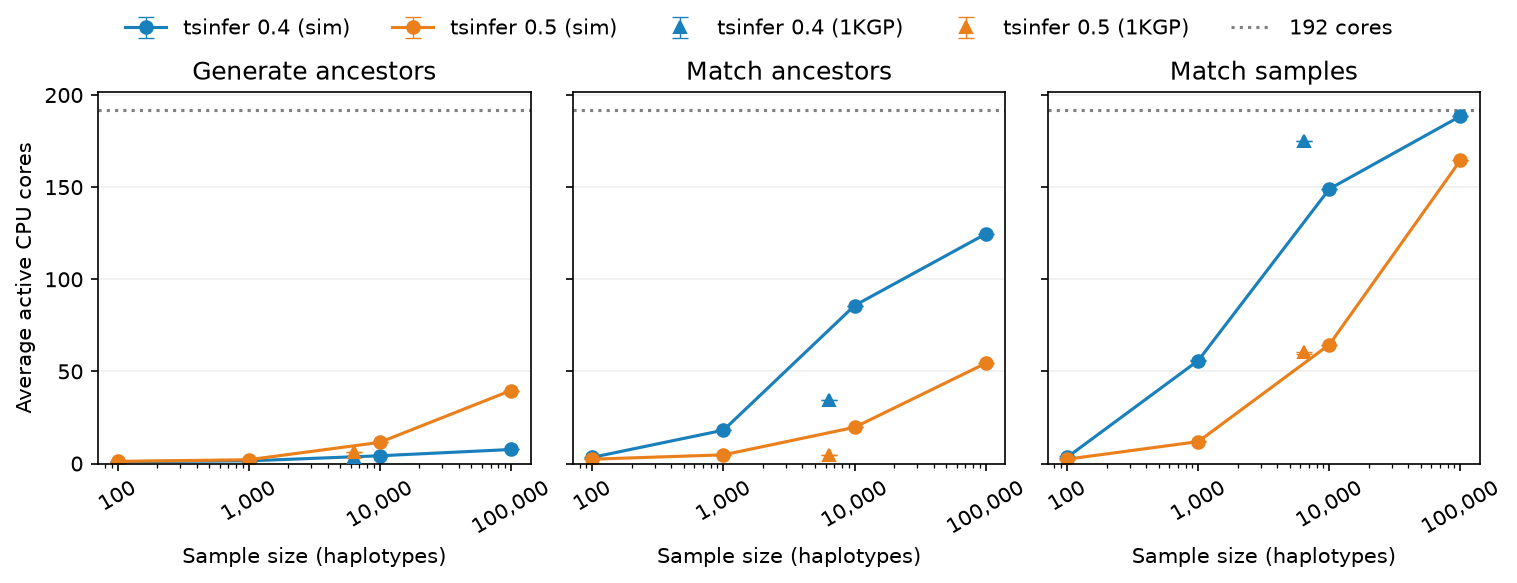

Prepared thesis export: inference_performance_parallelism.png


In [3]:
perf_parallelism_figure = nb_plot.plot_resources(
    perf_data,
    "parallelism",
    perf_config,
    reference_data=tgp_perf_data,
    dpi=150,
    figsize=(10, 3.8),
    jitter_seed=42,
    parallelism_reference_cores=192,
    reference_markers=("^", "^"),
    repetition_alpha=0.7,
    repetition_marker_size=13,
    resource_jitter_log10=0.025,
    resource_range_capsize=4,
    resource_range_linewidth=0.65,
    stage_labels=("Generate ancestors", "Match ancestors", "Match samples"),
    version_colors=("#1a80bb", "#ea801c"),
    version_labels=("tsinfer 0.4", "tsinfer 0.5"),
)
nb_plot.save_notebook_figure(
    perf_parallelism_figure,
    figure_folder / "inference_performance_parallelism.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
nb_plot.show_figure()

### Verification: performance numbers used in the text

Stage rows retain every repetition and compare matching rep IDs.
CPU time includes user and system time. Totals sum stages within each run;
the second table reports mean total minutes and mean paired total speedup.
The old scheduler replay caches describe the original 0.5 ancestor files.
New ancestor files and logs are needed before repeating that analysis.
Their group statistics must not be combined with the alternative timings.

In [107]:
perf_text_metrics = perf_comparison_data.copy()
perf_text_metrics["cpu_seconds"] = (
    perf_text_metrics.user_time + perf_text_metrics.sys_time
)
perf_text_checks = perf_text_metrics[
    [
        "elapsed_time",
        "elapsed_minutes",
        "cpu_seconds",
        "parallelism",
        "memory_gib",
        "num_sites",
        "num_edges",
    ]
].unstack("version")
for metric, output_name in [
    ("elapsed_time", "elapsed_speedup"),
    ("cpu_seconds", "cpu_time_reduction"),
]:
    old_values = perf_text_checks[metric, perf_config.versions[0]]
    new_values = perf_text_checks[metric, perf_config.versions[1]]
    perf_text_checks[output_name, "0.4 / 0.5"] = old_values / new_values
ipdisplay.display(perf_text_checks.style.format("{:.4f}"))
perf_total_seconds = perf_comparison_data.elapsed_time.groupby(
    ["num_samples", "version", "rep"]
).sum()
perf_totals = perf_total_seconds.unstack("version")
perf_total_checks = (
    perf_totals.groupby("num_samples").mean() / perf_config.seconds_per_minute
)
perf_total_checks.columns = [
    f"{version}_minutes" for version in perf_total_checks.columns
]
perf_total_speedup = (
    perf_totals[perf_config.versions[0]] / perf_totals[perf_config.versions[1]]
)
perf_total_checks["total_speedup"] = perf_total_speedup.groupby("num_samples").mean()
ipdisplay.display(perf_total_checks.style.format("{:.4f}"))
perf_site_checks = perf_comparison_data.num_sites.unstack("version")
assert perf_site_checks[perf_config.versions[0]].equals(
    perf_site_checks[perf_config.versions[1]]
)

,0.4_minutes,0.5_minutes,total_speedup
num_samples,,,
100,1.1109,1.1473,0.9696
1000,10.4212,9.3353,1.1163
6404,69.4899,45.6753,1.5214
10000,170.6451,76.5268,2.2299
100000,4125.9589,647.5756,6.3714


### Verification: frequency patterns and remaining numerical placeholders

Count focal sites separately, but ancestor IDs once within each replicate.
Rare-tail cutoffs pool both focal-site sides, matching the overshoot plot.
Overall error fractions count each focal-site overlap once; mismatch fraction
divides summed errors by summed compared inference sites, without averaging bin rates.

In [ ]:
text_check_settings = {
    "rare_frequency": 0.001,
    "tail_probability": 0.001,
    "percent": 100,
}
error_free_spans = nb_utils._no_errors(data.spans)
error_free_overshoots = nb_utils._no_errors(data.overshoots)
focal_count_rows = []
for version, rows in error_free_spans.groupby("version"):
    focal_count_rows.append(
        {
            "version": version,
            "focal_sites": len(rows),
            "true_ancestors": len(rows.drop_duplicates(["replicate", "true_node"])),
            "inferred_ancestors": len(
                rows.drop_duplicates(["replicate", "inferred_node"])
            ),
            "replicates": rows.replicate.nunique(),
        }
    )
focal_count_checks = pd.DataFrame(focal_count_rows).set_index("version")
rare_overshoots = error_free_overshoots.loc[
    error_free_overshoots.allele_frequency < text_check_settings["rare_frequency"]
]
rare_tail_checks = (
    rare_overshoots.groupby("version")
    .overshoot.quantile(text_check_settings["tail_probability"])
    .to_frame("lower_0_1_pct_bp")
)
rare_tail_checks["lower_0_1_pct_mb"] = (
    rare_tail_checks.lower_0_1_pct_bp / config.bp_per_mb
)
whole_overlap_checks = ancestor_overlap_errors.groupby("version").agg(
    comparisons=("num_errors", "size"),
    with_errors=("num_errors", lambda values: values.gt(0).sum()),
    total_errors=("num_errors", "sum"),
    overlap_bp=("overlap_span", "sum"),
    overlap_sites=("overlap_site_span", "sum"),
)
whole_overlap_checks["with_errors_pct"] = (
    text_check_settings["percent"]
    * whole_overlap_checks.with_errors
    / whole_overlap_checks.comparisons
)
whole_overlap_checks["pooled_mismatch_fraction_pct"] = (
    text_check_settings["percent"]
    * whole_overlap_checks.total_errors
    / whole_overlap_checks.overlap_sites
)
span_pattern_checks = ancestor_span_curve_summary.pivot(
    index=["dataset", "bin", "bin_left", "bin_right"],
    columns="version",
    values="mean_span_mb",
)
span_pattern_checks["new_minus_old_mb"] = (
    span_pattern_checks[config.versions[1]] - span_pattern_checks[config.versions[0]]
)
for table in [
    focal_count_checks,
    rare_tail_checks,
    whole_overlap_checks,
    span_pattern_checks,
]:
    ipdisplay.display(table)

### Export numerical checks for the chapter review

Regenerate the observations and units used in the figures with the notebook.

In [109]:
text_check_folder = data_folder / "text_checks_alt"
text_check_folder.mkdir(exist_ok=True)
text_check_tables = {
    "focal_counts": focal_count_checks,
    "rare_overshoot_tail": rare_tail_checks,
    "whole_overlap_errors": whole_overlap_checks,
    "span_patterns": span_pattern_checks,
    "ancestor_span_curves": ancestor_span_curve_summary,
    "tgp_inference_site_extent": tgp_inference_site_extent,
    "demography_quartiles": demography_iqr_table,
    "demography_tails": demography_tail_table,
    "demography_tail_changes": demography_tail_changes,
    "demography_mean_lower_change": demography_lower_change_working,
    "demography_error_changes": demography_error_changes,
    "demography_error_checks": demography_error_checks,
    "demography_error_directions": demography_direction_checks,
    "ancestor_overlap_errors": ancestor_error_summary,
    "genotype_errors": genotype_summary.rates,
    "genotype_transitions": genotype_summary.transitions,
    "performance_stages": perf_text_checks,
    "performance_totals": perf_total_checks,
}
for name, table in text_check_tables.items():
    table.to_csv(text_check_folder / f"{name}.csv")

## Testing error buffering

Compare the standard algorithms with the alternative tsinfer 0.5 algorithm,
which skips sites with no derived carriers in the current sample set.
Bright red denotes tsinfer 0.5 (alt) throughout. These comparisons retain
original 0.5 results and save to dphil-analysis/figures/ch3/error_buffering.
These historical algorithm comparisons keep their separate original input files.

In [ ]:
# Whole-overlap errors occur on both side rows: count only the left copy.
buffering_figure_folder = figure_folder / "error_buffering"
buffering_figure_folder.mkdir(exist_ok=True)
buffering_settings = {"box_multipliers": (0, 1, 10), "alt_version": "0.5 (alt)"}
buffering_config = dataclasses.replace(
    config, versions=(*config.versions, buffering_settings["alt_version"])
)
buffering_multipliers = (0, *config.genotype_multipliers)
buffering_inputs = {
    "standard": aggregated_folder / f"{data_prefix}-aggregated.csv",
    "alternative": data_folder / f"{data_prefix}-aggregated_alt_version.csv",
}
buffering_overshoot_frames = []
buffering_span_frames = []
buffering_summary_frames = []
for algorithm, path in buffering_inputs.items():
    query = pl.scan_csv(path)
    query = query.filter(
        (pl.col("phase_ser") == 0)
        & (pl.col("mispol_rate") == 0)
        & pl.col("geno_multiplier").is_in(buffering_multipliers)
        & pl.col("version").is_in(config.versions)
    )
    if algorithm == "alternative":
        query = query.filter(pl.col("version") == config.versions[1])
        query = query.with_columns(
            pl.lit(buffering_settings["alt_version"]).alias("version")
        )
    left = pl.col("side") == "left"
    grouped = query.group_by("version", "geno_multiplier").agg(
        left.sum().alias("num_ancestors"),
        (left & (pl.col("num_errors") == 0)).sum().alias("num_error_free"),
        pl.col("num_errors").filter(left).sum().alias("num_errors"),
        pl.col("num_should_be_1").filter(left).sum().alias("should_be_0_errors"),
        pl.col("num_should_be_0").filter(left).sum().alias("should_be_1_errors"),
        pl.col("overlap_span").filter(left).sum().alias("overlap_bp"),
        pl.col("overlap_site_span").filter(left).sum().alias("overlap_sites"),
    )
    table = grouped.collect(engine="streaming")
    buffering_summary_frames.append(pd.DataFrame(table.to_dict(as_series=False)))
    overshoots = query.filter(
        pl.col("geno_multiplier").is_in(buffering_settings["box_multipliers"])
    )
    overshoots = overshoots.select(
        "replicate",
        "version",
        "geno_multiplier",
        "true_focal_site",
        "side",
        "allele_frequency",
        "overshoot",
    )
    table = overshoots.collect(engine="streaming")
    buffering_overshoot_frames.append(pd.DataFrame(table.to_dict(as_series=False)))
    spans = query.filter(left & (pl.col("geno_multiplier") == 0))
    spans = spans.select(
        "replicate",
        "version",
        "geno_multiplier",
        "phase_ser",
        "mispol_rate",
        "true_focal_site",
        "allele_frequency",
        "inferred_span",
        "true_span",
    )
    table = spans.collect(engine="streaming")
    buffering_span_frames.append(pd.DataFrame(table.to_dict(as_series=False)))
buffering_summary = pd.concat(buffering_summary_frames, ignore_index=True)
buffering_overshoots = pd.concat(buffering_overshoot_frames, ignore_index=True)
buffering_spans = pd.concat(buffering_span_frames, ignore_index=True)
buffering_counts = buffering_summary.pivot(
    index="geno_multiplier", columns="version", values="num_ancestors"
)
assert set(buffering_counts.index) == set(buffering_multipliers)
assert set(buffering_counts.columns) == set(buffering_config.versions)
assert (
    buffering_counts.eq(buffering_counts[config.versions[0]], axis="index").all().all()
)

### Ancestor spans

Use the error-free simulation profiles and the same frequency bins, truth
curve and count panel as `plot_ancestor_span_curves` above.

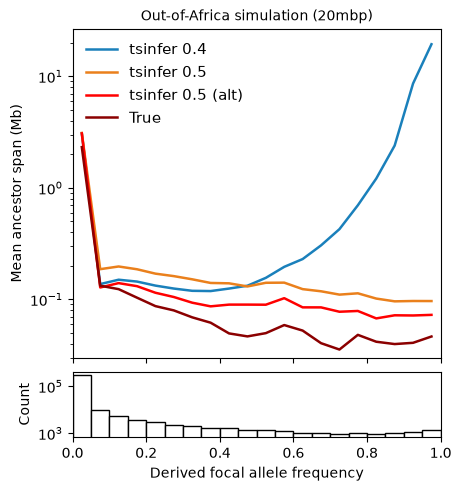

In [111]:
buffering_data = dataclasses.replace(
    data, spans=buffering_spans, config=buffering_config
)
buffering_span_summary = nb_utils.summarise_ancestor_span_curves(
    buffering_data, tgp_ancestor_spans, ancestor_error_bins=20
)
nb_plot.plot_ancestor_span_curves(
    buffering_span_summary,
    "Simulation",
    config=buffering_config,
    title="Out-of-Africa simulation (20mbp)",
    figure_folder=buffering_figure_folder,
    y_log=True,
    dpi=300,
    span_curve_height_ratios=(3, 0.6),
    span_curve_legend_fontsize=11,
    span_curve_limit_factor=1.2,
    span_curve_line_width=1.8,
    span_curve_size=(4.5, 4.8),
    span_curve_title_fontsize=10,
    span_curve_true_color="#8b0000",
    version_colors=("#1a80bb", "#ea801c", "#ff0000"),
)

### Overshoots by focal allele frequency

Use the usual frequency cutoffs, boxplots, coloured jitter, tail quantile
caps and focal-site count panel. Each plot selects one genotype error
multiplier, with zero switch error and mispolarisation. The alternative
implementation adds a third group in bright red within every frequency bin.

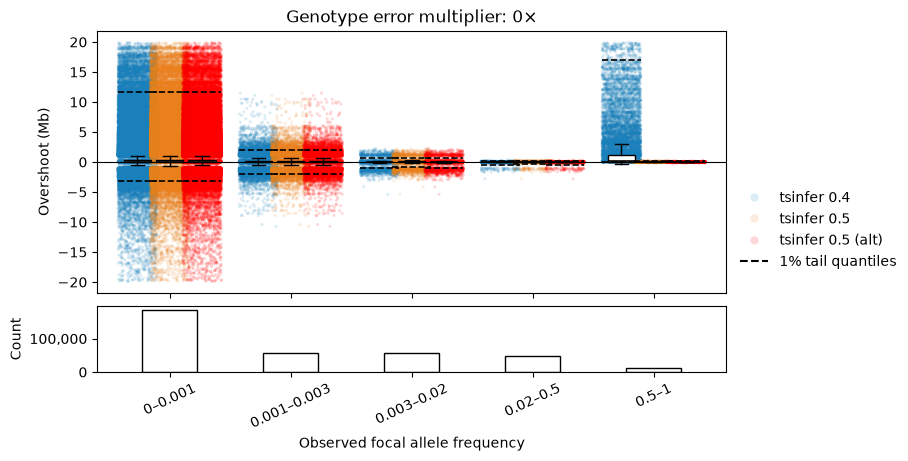

In [12]:
nb_plot.plot_buffering_frequency_overshoots(
    0,
    buffering_config=buffering_config,
    buffering_figure_folder=buffering_figure_folder,
    buffering_overshoots=buffering_overshoots,
    config=config,
    dpi=300,
    jitter_alpha=0.15,
    jitter_seed=42,
    mean_bar_group_width=0.8,
    frequency_cutoffs=(0, 0.001, 0.003, 0.02, 0.5, 1),
    box_size=(9, 4.5),
    version_colors=("#1a80bb", "#ea801c", "#ff0000"),
    tail_quantile=0.01,
    box_y_log=False,
)

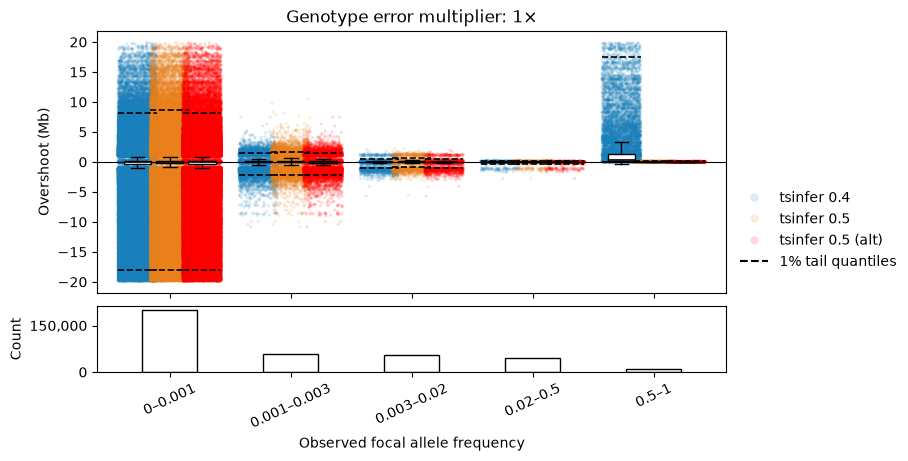

In [13]:
nb_plot.plot_buffering_frequency_overshoots(
    1,
    buffering_config=buffering_config,
    buffering_figure_folder=buffering_figure_folder,
    buffering_overshoots=buffering_overshoots,
    config=config,
    dpi=300,
    jitter_alpha=0.15,
    jitter_seed=42,
    mean_bar_group_width=0.8,
    frequency_cutoffs=(0, 0.001, 0.003, 0.02, 0.5, 1),
    box_size=(9, 4.5),
    version_colors=("#1a80bb", "#ea801c", "#ff0000"),
    tail_quantile=0.01,
    box_y_log=False,
)

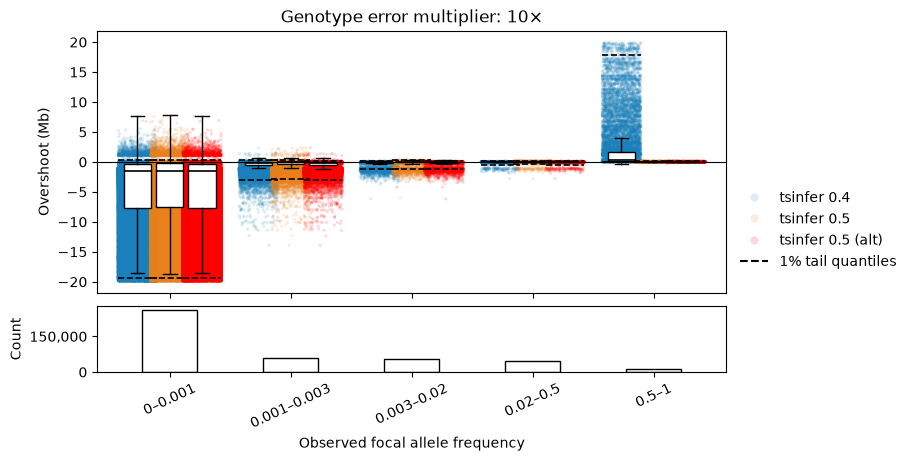

In [14]:
nb_plot.plot_buffering_frequency_overshoots(
    10,
    buffering_config=buffering_config,
    buffering_figure_folder=buffering_figure_folder,
    buffering_overshoots=buffering_overshoots,
    config=config,
    dpi=300,
    jitter_alpha=0.15,
    jitter_seed=42,
    mean_bar_group_width=0.8,
    frequency_cutoffs=(0, 0.001, 0.003, 0.02, 0.5, 1),
    box_size=(9, 4.5),
    version_colors=("#1a80bb", "#ea801c", "#ff0000"),
    tail_quantile=0.01,
    box_y_log=False,
)

### Ancestor errors by genotype error multiplier

Pool all focal frequencies within each multiplier. The top row shows the
fraction of whole-overlap comparisons with no errors; the bottom row shows
total errors divided by total compared inference sites, stacked by error direction.
Each focal site contributes once, retaining the usual two-row format.

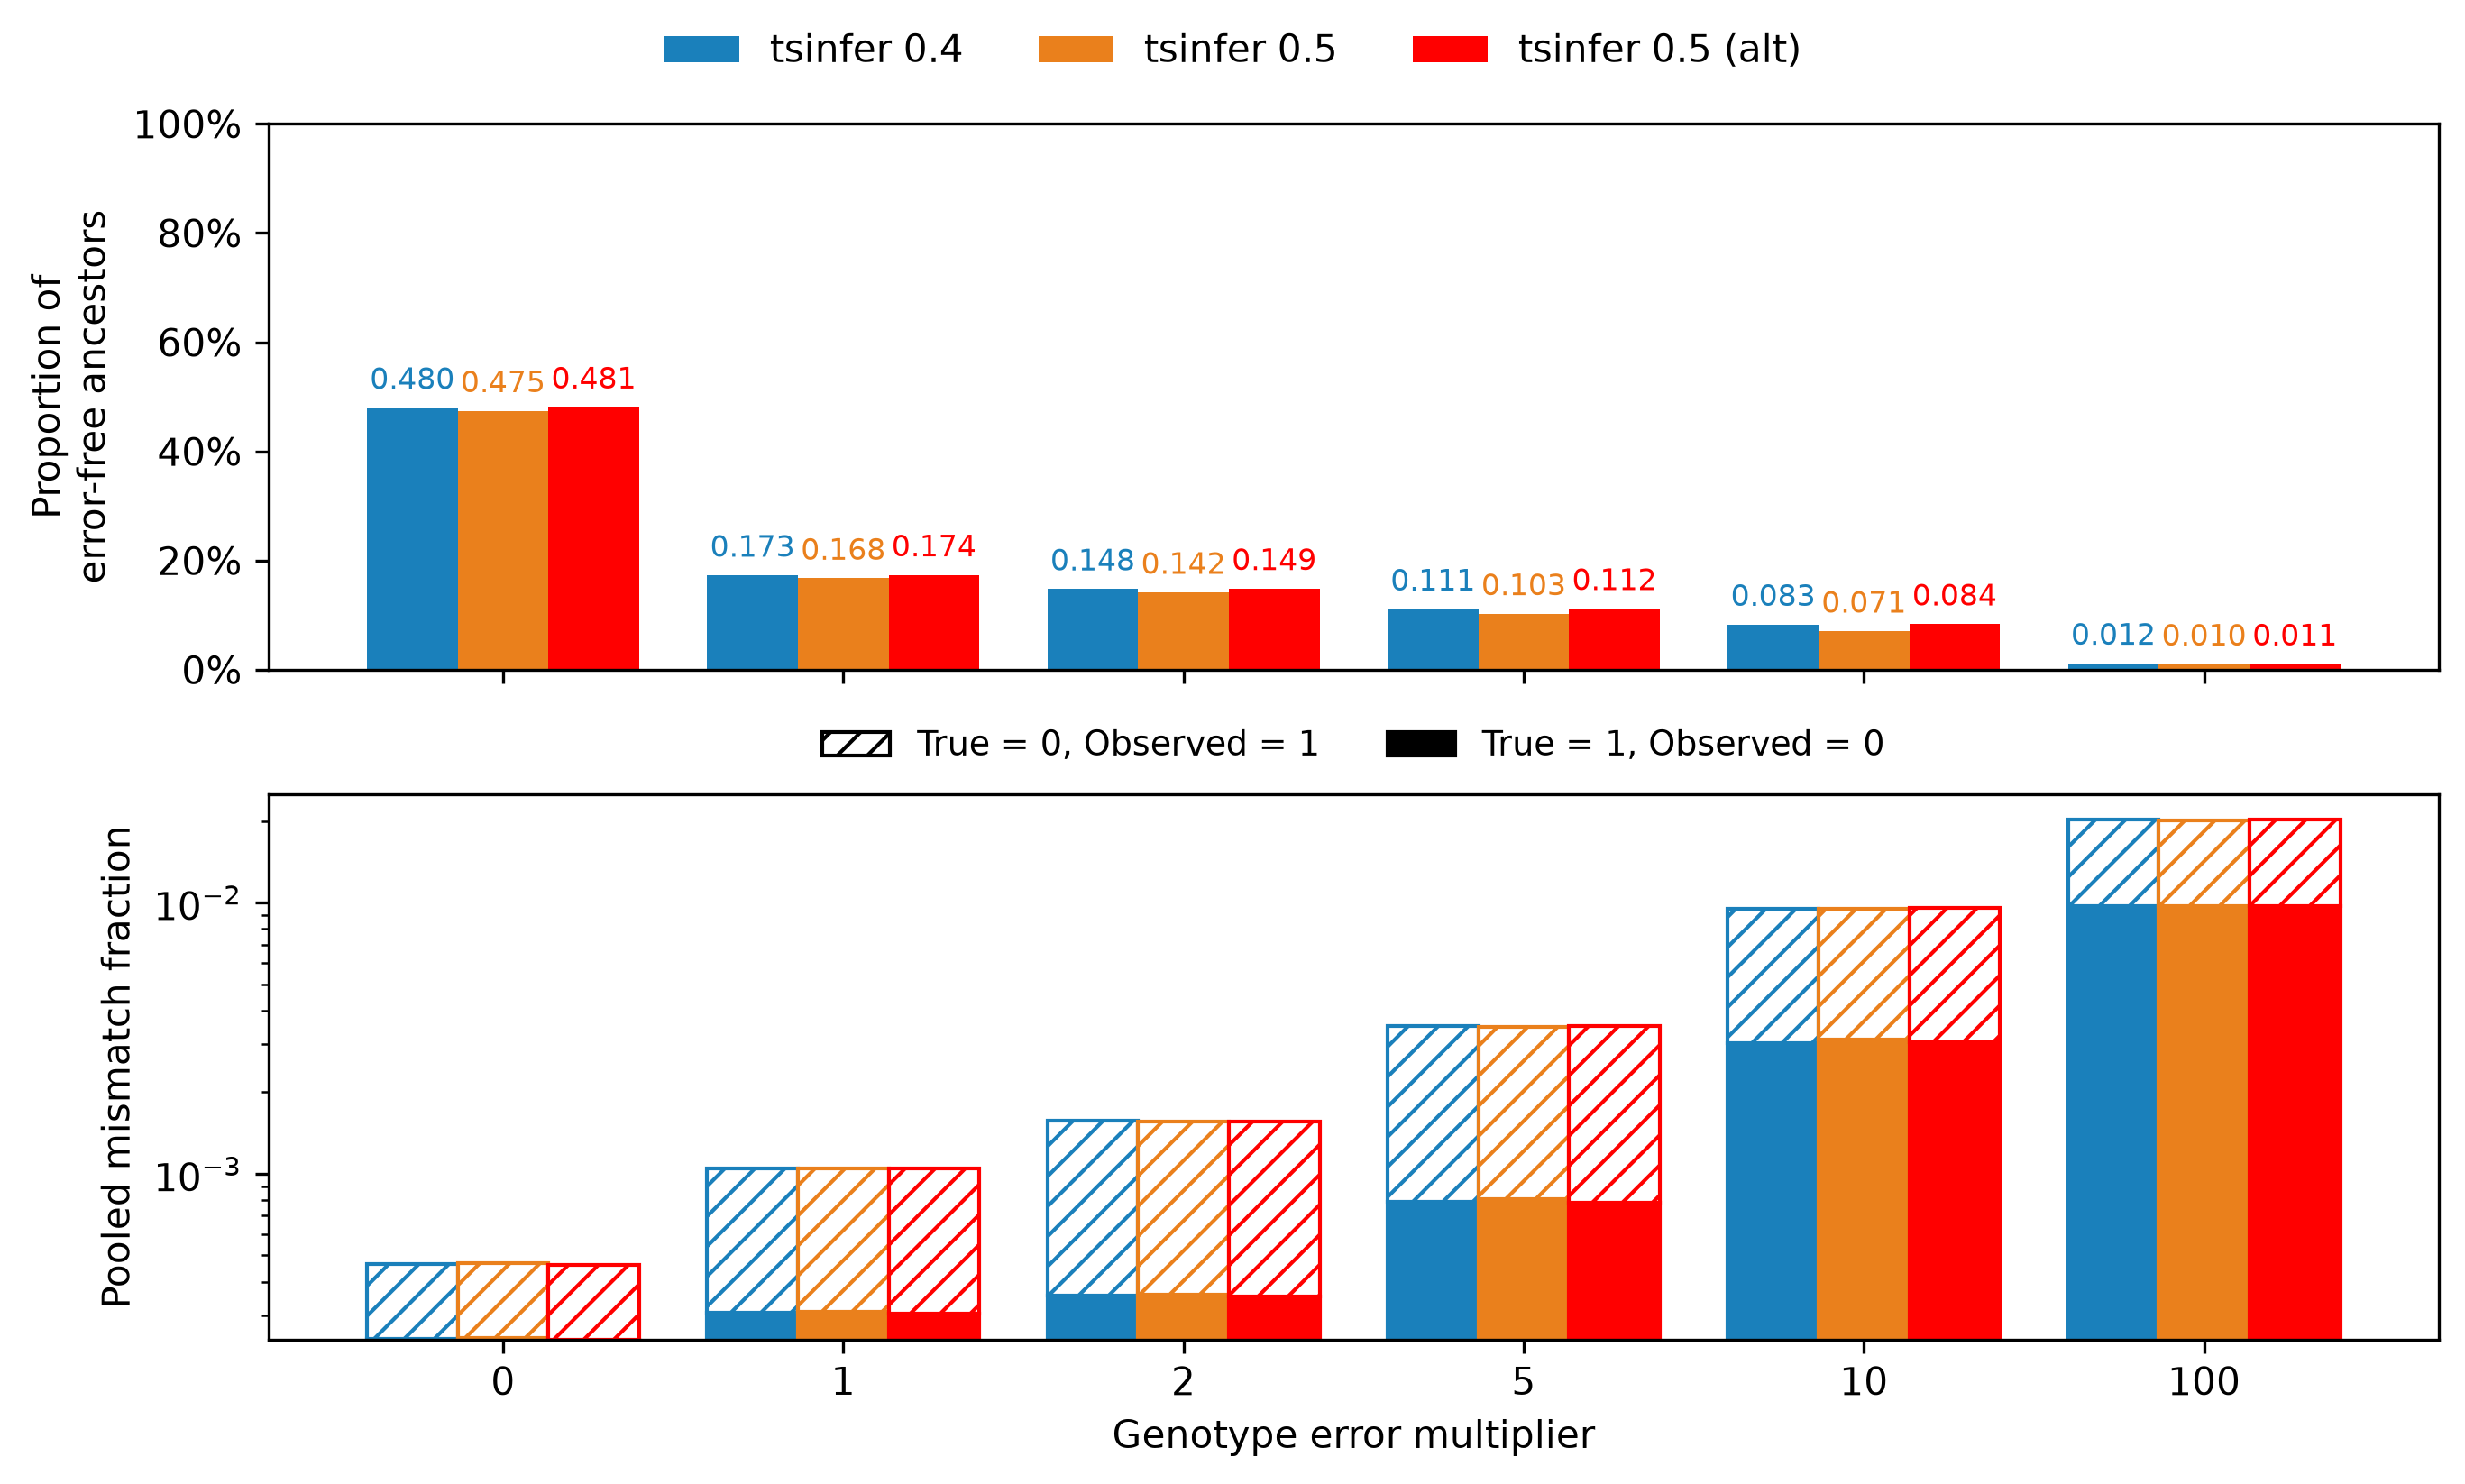

In [ ]:
buffering_positions = np.arange(len(buffering_multipliers))
buffering_bar_width = 0.8 / len(buffering_config.versions)
buffering_group_labels = {rate: f"{rate:g}" for rate in buffering_multipliers}
buffering_error_summary = buffering_summary.copy()
buffering_error_summary["error_free_fraction"] = (
    buffering_error_summary.num_error_free / buffering_error_summary.num_ancestors
)
buffering_overlap_sites = buffering_error_summary.overlap_sites.replace(0, np.nan)
buffering_error_summary["mismatch_fraction"] = (
    buffering_error_summary.num_errors / buffering_overlap_sites
)
buffering_error_summary["should_be_0_mismatch_fraction"] = (
    buffering_error_summary.should_be_0_errors / buffering_overlap_sites
)
buffering_error_summary["should_be_1_mismatch_fraction"] = (
    buffering_error_summary.should_be_1_errors / buffering_overlap_sites
)
buffering_error_figure = nb_plot.plot_ancestor_errors_by_genotype_error_multiplier(
    buffering_bar_width=buffering_bar_width,
    buffering_config=buffering_config,
    buffering_error_summary=buffering_error_summary,
    buffering_figure_folder=buffering_figure_folder,
    buffering_group_labels=buffering_group_labels,
    buffering_multipliers=buffering_multipliers,
    buffering_positions=buffering_positions,
    fontsize=8,
    fontsize_2=9,
    dpi=300,
    error_size=(9, 5.4),
    version_colors=("#1a80bb", "#ea801c", "#ff0000"),
)
nb_plot.close_figure(buffering_error_figure)

### Negative overshoot proportions by focal allele frequency

Each focal-site ancestor comparison contributes once, as in the boxplots
above. A comparison has negative overshoot if either side is negative.
Its negative magnitude is the larger underextension of its two sides,
expressed as a positive length. Pool focal sites across replicates within
the same frequency bins, retaining separate panels for 0×, 1× and 10×
genotype errors. Switch error and mispolarisation remain zero.

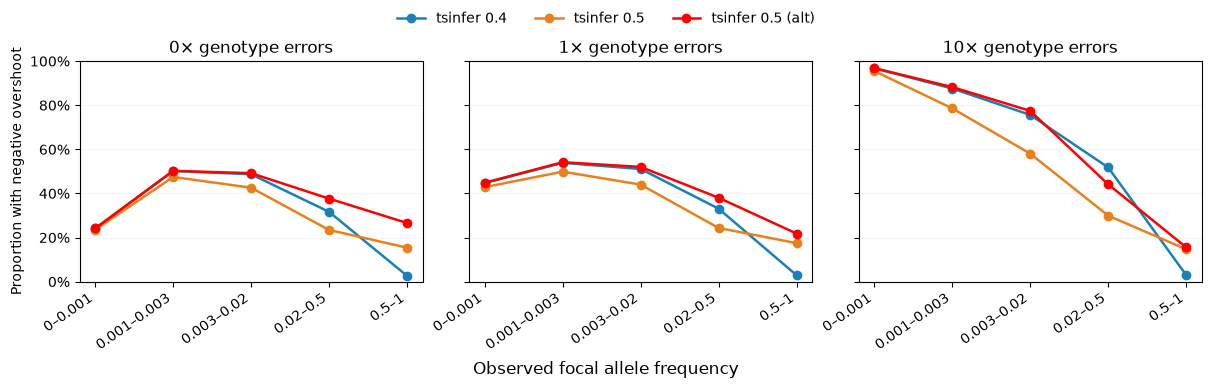

In [117]:
# A populated bin with no negative overshoots has zero conditional magnitude.
buffering_focal_keys = ["replicate", "version", "geno_multiplier", "true_focal_site"]
buffering_negative_focals = (
    buffering_overshoots.groupby(buffering_focal_keys)
    .agg(
        allele_frequency=("allele_frequency", "first"),
        minimum_overshoot_bp=("overshoot", "min"),
        num_sides=("side", "size"),
    )
    .reset_index()
)
assert buffering_negative_focals.num_sides.eq(2).all()
buffering_negative_focals["has_negative_overshoot"] = (
    buffering_negative_focals.minimum_overshoot_bp < 0
)
buffering_negative_focals["negative_magnitude_mb"] = (
    -buffering_negative_focals.minimum_overshoot_bp.clip(upper=0) / config.bp_per_mb
)
buffering_negative_focals["conditional_negative_magnitude_mb"] = (
    buffering_negative_focals.negative_magnitude_mb.where(
        buffering_negative_focals.has_negative_overshoot
    )
)
buffering_line_edges = np.array((0, 0.001, 0.003, 0.02, 0.5, 1), dtype=float)
buffering_line_cut_edges = buffering_line_edges.copy()
buffering_line_cut_edges[-1] = np.nextafter(buffering_line_edges[-1], np.inf)
buffering_negative_focals["frequency_bin"] = pd.cut(
    buffering_negative_focals.allele_frequency,
    buffering_line_cut_edges,
    labels=False,
    right=False,
)
buffering_negative_summary = (
    buffering_negative_focals.groupby(
        ["version", "geno_multiplier", "frequency_bin"], observed=True
    )
    .agg(
        num_focal_sites=("has_negative_overshoot", "size"),
        negative_proportion=("has_negative_overshoot", "mean"),
        mean_negative_magnitude_mb=("conditional_negative_magnitude_mb", "mean"),
        mean_magnitude_all_focals_mb=("negative_magnitude_mb", "mean"),
    )
    .reset_index()
)
buffering_negative_summary["mean_negative_magnitude_mb"] = (
    buffering_negative_summary.mean_negative_magnitude_mb.fillna(0)
)
buffering_negative_summary["weighted_negative_overshoot_score_mb"] = (
    buffering_negative_summary.negative_proportion
    * buffering_negative_summary.mean_negative_magnitude_mb
)
np.testing.assert_allclose(
    buffering_negative_summary.weighted_negative_overshoot_score_mb,
    buffering_negative_summary.mean_magnitude_all_focals_mb,
)
buffering_line_labels = [
    f"{left:g}–{right:g}"
    for left, right in zip(buffering_line_edges[:-1], buffering_line_edges[1:])
]
nb_plot.plot_buffering_negative_lines(
    "negative_proportion",
    "Proportion with negative overshoot",
    proportion=True,
    buffering_config=buffering_config,
    buffering_figure_folder=buffering_figure_folder,
    buffering_line_labels=buffering_line_labels,
    buffering_negative_summary=buffering_negative_summary,
    buffering_settings=buffering_settings,
    dpi=300,
    line_figsize=(12, 3.8),
    version_colors=("#1a80bb", "#ea801c", "#ff0000"),
    line_marker="o",
    line_line_width=1.8,
    line_tick_rotation=35,
)

### Weighted negative overshoot score

Multiply the negative-overshoot proportion by the mean negative magnitude
among affected focal-site comparisons in each bin. The score is in Mb;
equivalently, it is the mean negative magnitude over all comparisons,
assigning zero to comparisons with no negative overshoot. Higher scores
indicate more frequent and/or larger underextension.

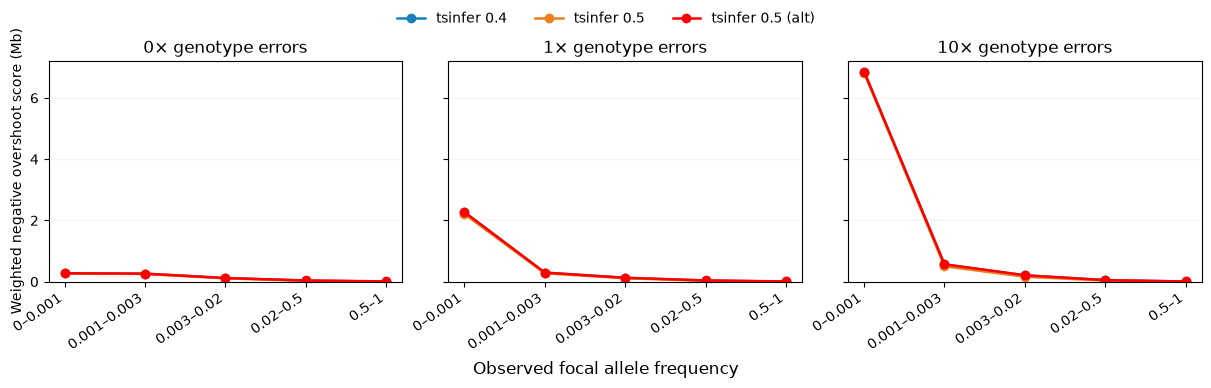

In [118]:
nb_plot.plot_buffering_negative_lines(
    "weighted_negative_overshoot_score_mb",
    "Weighted negative overshoot score (Mb)",
    buffering_config=buffering_config,
    buffering_figure_folder=buffering_figure_folder,
    buffering_line_labels=buffering_line_labels,
    buffering_negative_summary=buffering_negative_summary,
    buffering_settings=buffering_settings,
    dpi=300,
    line_figsize=(12, 3.8),
    version_colors=("#1a80bb", "#ea801c", "#ff0000"),
    line_marker="o",
    line_line_width=1.8,
    line_tick_rotation=35,
)